# 10 · Multi-Layer Perceptrons & Backpropagation from Scratch
*AI Foundations · Notebook 10 of 19*

Logistic and softmax regression can only draw *straight* decision boundaries. Real problems are rarely that polite: think of a ring of points around a center, two interleaving half-moons, or the pixels of a smiling face. A **multi-layer perceptron (MLP)** fixes this by stacking layers of simple "neurons", each a linear model followed by a nonlinear bend. Stack enough of them and the network can approximate essentially any function, *provided you can train it*. Training needs the gradient of the loss with respect to every weight, and the algorithm that computes all of those gradients at once, cheaply, is **backpropagation**.

In this notebook you will build an MLP **completely from scratch in NumPy**: you will derive every gradient by hand, check it numerically, verify it against PyTorch, and then use your own little library to train networks on nonlinear data. Along the way you will learn *why* the standard recipes (ReLU, He initialization, Adam, dropout, ...) look the way they do. At the end every piece is mapped onto PyTorch, ready for the hands-on PyTorch notebooks that follow (Notebooks 11–13: regression on car fuel efficiency, a 3-class nonlinear 2D problem, and facial-expression images).

**What you will learn**
- The perceptron: its learning rule, a full proof that it converges on separable data, and a proof that it can never solve XOR.
- Why stacking linear layers without activations collapses to a single linear map, and what hidden layers really do (they learn new features).
- MLP architecture and notation: layers, widths, parameter counting, and the forward pass in matrix form for a mini-batch, with every shape spelled out.
- Activation functions (sigmoid, tanh, ReLU, Leaky ReLU, GELU, softplus) with their derivatives, saturation, vanishing gradients and dead ReLUs, and how to match output layers with losses (identity + MSE, sigmoid + BCE, softmax + cross-entropy on *logits*).
- Backpropagation: computational graphs, local gradients, the chain rule for matrices, the famous $\delta^{[L]} = P - Y$, a complete backward pass worked by hand, and why backprop is enormously cheaper than finite differences.
- A modular NumPy library (`Linear`, `ReLU`, `Tanh`, `Sigmoid`, `Sequential`, losses, `SGD`, `Adam`), verified with gradient checking and against PyTorch autograd.
- Training on XOR, circles, moons and a 3-class spiral, universal approximation, and depth versus width.
- Initialization (symmetry breaking, Xavier/Glorot, He/Kaiming), optimizers (SGD, momentum, Adam) and regularization (weight decay, early stopping, dropout).
- The bridge to PyTorch: the same model in about 15 lines, plus the full training workflow used in the next notebooks.

**Prerequisites:** Python and NumPy, derivatives and the chain rule, gradient descent, and logistic/softmax regression with cross-entropy (all covered in earlier notebooks of this series).      **Estimated time:** ~7 h (take it in several sittings)

**How to use this notebook:** run cells top to bottom (Runtime → Run all works). Exercises are marked ✏️. Each has an automatic checker and a hidden solution (click "Solution" to expand). Quick-check questions have hidden answers. The lesson never depends on your exercise solutions, so you can skip an exercise and come back later.

**Contents**
1. From linear models to neurons: the perceptron and its limits
2. The multi-layer perceptron: architecture, notation and the forward pass
3. Activation functions, output layers and losses
4. Backpropagation: deriving every gradient
5. A modular MLP library from scratch
6. Training MLPs on nonlinear data
7. Initialization: breaking symmetry and keeping signals alive
8. Optimizers: SGD, momentum and Adam
9. What can an MLP represent? Universal approximation, width and depth
10. Regularization: weight decay, early stopping and dropout
11. Bridge to PyTorch
12. Quiz
13. Summary and going further

In [1]:
# Setup: imports, reproducibility, plotting style and a tiny test harness.
import os

# Our matrices are tiny, so a single math-library thread is fastest (and plays nicely with
# other programs). This must be set before NumPy/PyTorch are imported to take effect.
os.environ.setdefault("OMP_NUM_THREADS", "1")

import copy
import math
import random
import sys
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
from IPython.display import display
from matplotlib.colors import ListedColormap
from scipy.special import erf
from sklearn.linear_model import LogisticRegression

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

# Every dataset in this notebook is generated in code, so nothing is downloaded.
# DATA_DIR is defined only for consistency with the rest of the series.
DATA_DIR = Path("data")

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)

# One consistent set of class colors for every 2D plot in the notebook.
CLASS_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c"]

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | torch {torch.__version__} | matplotlib {matplotlib.__version__}")


def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")

Python 3.13.15 | numpy 2.5.3 | pandas 2.3.3 | scikit-learn 1.9.1 | torch 2.14.1+cu130 | matplotlib 3.11.2


## 1. From linear models to neurons: the perceptron and its limits

### 1.1 A neuron is a linear score followed by a response curve

In logistic regression you computed a probability in two steps:

$$
z = \mathbf{w}^\top \mathbf{x} + b = \sum_{j=1}^{d} w_j x_j + b, \qquad \hat y = \sigma(z) = \frac{1}{1 + e^{-z}}.
$$

These two steps get names, because you will meet them thousands of times from now on:

- the **pre-activation** $z \in \mathbb{R}$: a weighted vote of the inputs $\mathbf{x} \in \mathbb{R}^d$ with **weights** $\mathbf{w} \in \mathbb{R}^d$, plus a **bias** $b \in \mathbb{R}$ that shifts the threshold.
- the **activation** $a = g(z)$: a fixed **activation function** $g$ applied to the vote.

This two-step unit is an **artificial neuron**. An everyday picture: a judge at a talent show listens to several performers' qualities (the inputs), trusts some qualities more than others (the weights), has a personal leaning (the bias) and announces a verdict through a response curve: a hard yes/no (a step function), a probability (sigmoid), or "how enthusiastic am I?" (ReLU, coming soon).

```
  x1 ──── w1 ───╮
  x2 ──── w2 ───┼──►  z = w1*x1 + w2*x2 + w3*x3 + b  ──►  a = g(z)
  x3 ──── w3 ───╯                    ▲
                                     b
```

> **Intuition.** The name comes from biology: a brain neuron collects signals on its dendrites, sums them in the cell body and "fires" when the sum crosses a threshold. The analogy inspired the field, but it is loose. Real neurons are vastly more complicated. Artificial ones are best understood simply as differentiable functions that we know how to optimize.

**Geometry of one neuron.** The points where $z = 0$, that is $\{\mathbf{x} : \mathbf{w}^\top\mathbf{x} + b = 0\}$, form a **hyperplane** (a line when $d = 2$). For any input, $z / \lVert \mathbf{w} \rVert$ is the *signed distance* from $\mathbf{x}$ to that hyperplane: positive on the side $\mathbf{w}$ points to, negative on the other side. So a single neuron answers the question *"which side of my hyperplane are you on, and how far?"*, and the activation turns that answer into an output.

Softmax regression is just $K$ neurons that read the same input, followed by a softmax across their $K$ pre-activations. In other words, **the models from the previous notebooks were already one-layer neural networks.** Everything in this notebook is about putting more layers between the input and the output.

In [2]:
# One neuron with weights w = (2, -1) and bias b = 0.5, applied to three points.
w_demo = np.array([2.0, -1.0])
b_demo = 0.5
points = np.array([[1.0, 1.0], [0.0, 2.0], [-1.0, -1.5]])

z_demo = points @ w_demo + b_demo                   # pre-activations, one per point
dist_demo = z_demo / np.linalg.norm(w_demo)         # signed distance to the line 2*x1 - x2 + 0.5 = 0
a_demo = 1.0 / (1.0 + np.exp(-z_demo))              # sigmoid activation

display(pd.DataFrame({"x1": points[:, 0], "x2": points[:, 1], "z = w.x + b": z_demo,
                      "signed distance": dist_demo, "sigmoid(z)": a_demo}).round(4))

,x1,x2,z = w.x + b,signed distance,sigmoid(z)
0,1.0,1.0,1.5,0.6708,0.8176
1,0.0,2.0,-1.5,-0.6708,0.1824
2,-1.0,-1.5,0.0,0.0000,0.5000


Check the first row by hand: $z = 2(1) - 1(1) + 0.5 = 1.5$, the distance is $1.5/\sqrt{2^2 + 1^2} = 1.5/\sqrt 5 \approx 0.6708$ and $\sigma(1.5) \approx 0.8176$. The third point lies exactly on the line ($z = 0$), so the sigmoid sits at its midpoint $0.5$.

### 1.2 The perceptron: the first learning neuron

Frank Rosenblatt's **perceptron** (1958) is the ancestor of every network in this notebook. It uses labels $y \in \{-1, +1\}$ and the hardest possible response curve, the sign function:

$$
\hat y = \operatorname{sign}(\mathbf{w}^\top \mathbf{x} + b).
$$

**Learning rule.** Visit the training examples one at a time. Call example $i$ a *mistake* when $y_i(\mathbf{w}^\top\mathbf{x}_i + b) \le 0$ (wrong side, or exactly on the line). On a mistake, update

$$
\mathbf{w} \leftarrow \mathbf{w} + y_i\,\mathbf{x}_i, \qquad b \leftarrow b + y_i ,
$$

and on a correct example do nothing. Repeat full passes (**epochs**) until a pass makes no mistakes.

**Why this update is sensible.** Look at the score $y_i(\mathbf{w}^\top\mathbf{x}_i + b)$, which is positive exactly when example $i$ is classified correctly. After the update it becomes

$$
y_i\big((\mathbf{w} + y_i\mathbf{x}_i)^\top\mathbf{x}_i + b + y_i\big) = y_i(\mathbf{w}^\top\mathbf{x}_i + b) + \underbrace{y_i^2}_{=1}\big(\lVert\mathbf{x}_i\rVert^2 + 1\big),
$$

so every update pushes the score of the offending example up by $\lVert\mathbf{x}_i\rVert^2 + 1 > 0$. One push may not be enough, and a push may break another example, so it is not obvious that the procedure ever stops. Section 1.3 proves that it does whenever a separating line exists.

> **Going deeper.** The perceptron is stochastic gradient descent with learning rate 1 on the *perceptron loss* $\ell(\mathbf{w}, b) = \max\big(0, -y(\mathbf{w}^\top\mathbf{x} + b)\big)$: for a mistake its gradient is $(-y\mathbf{x}, -y)$, and for a correct example it is zero. The sign function itself has derivative zero everywhere except at $0$, where it jumps. That is fatal for training *multi-layer* networks with gradients, which is why modern networks replace the step with smooth or piecewise-linear activations.

**A run by hand.** Take four points, $A = (1, 2)$ and $B = (2, -1)$ with label $+1$, and $C = (-1, 1)$ and $D = (-2, -1)$ with label $-1$. Start from $\mathbf{w} = (0, 0)$, $b = 0$.

| step | point | $y$ | score $\mathbf{w}^\top\mathbf{x} + b$ | $y \cdot$ score | mistake? | $\mathbf{w}$ after | $b$ after |
|---|---|---|---|---|---|---|---|
| 1 | $A=(1,2)$ | $+1$ | $0$ | $0$ | yes | $(1, 2)$ | $1$ |
| 2 | $B=(2,-1)$ | $+1$ | $2 - 2 + 1 = 1$ | $1$ | no | $(1, 2)$ | $1$ |
| 3 | $C=(-1,1)$ | $-1$ | $-1 + 2 + 1 = 2$ | $-2$ | yes | $(1,2) - (-1,1) = (2, 1)$ | $0$ |
| 4 | $D=(-2,-1)$ | $-1$ | $-4 - 1 + 0 = -5$ | $5$ | no | $(2, 1)$ | $0$ |

In the second epoch every score has the right sign, so the perceptron stops with the line $2x_1 + x_2 = 0$. Let us confirm with code.

In [3]:
def perceptron_train(X, y, max_epochs=100, record=False):
    """Rosenblatt's perceptron.

    X: (n, d) inputs, y: (n,) labels in {-1, +1}.
    Returns (w, b, mistakes_per_epoch, trace), where trace lists every visit when record=True.
    """
    n, d = X.shape
    w, b = np.zeros(d), 0.0
    mistakes_per_epoch, trace = [], []
    for epoch in range(1, max_epochs + 1):
        mistakes = 0
        for i in range(n):
            score = float(X[i] @ w + b)
            wrong = y[i] * score <= 0                 # exactly on the line counts as a mistake
            if wrong:
                w = w + y[i] * X[i]
                b = b + y[i]
                mistakes += 1
            if record:
                trace.append({"epoch": epoch, "point": i, "y": int(y[i]), "score": score,
                              "mistake?": bool(wrong), "w after": tuple(w.tolist()), "b after": float(b)})
        mistakes_per_epoch.append(mistakes)
        if mistakes == 0:                              # a clean pass: the data are separated
            break
    return w, b, mistakes_per_epoch, trace


X_hand = np.array([[1.0, 2.0], [2.0, -1.0], [-1.0, 1.0], [-2.0, -1.0]])
y_hand = np.array([1, 1, -1, -1])
w_p, b_p, mistakes_p, trace_p = perceptron_train(X_hand, y_hand, record=True)
trace_df = pd.DataFrame(trace_p)
trace_df["point"] = trace_df["point"].map(dict(enumerate("ABCD")))
display(trace_df)
print("final w =", w_p, " b =", b_p, " mistakes per epoch:", mistakes_p)

,epoch,point,y,score,mistake?,w after,b after
0,1,A,1,0.0,True,"(1.0, 2.0)",1.0
1,1,B,1,1.0,False,"(1.0, 2.0)",1.0
2,1,C,-1,2.0,True,"(2.0, 1.0)",0.0
3,1,D,-1,-5.0,False,"(2.0, 1.0)",0.0
4,2,A,1,4.0,False,"(2.0, 1.0)",0.0
5,2,B,1,3.0,False,"(2.0, 1.0)",0.0
6,2,C,-1,-1.0,False,"(2.0, 1.0)",0.0
7,2,D,-1,-5.0,False,"(2.0, 1.0)",0.0


final w = [2. 1.]  b = 0.0  mistakes per epoch: [2, 0]


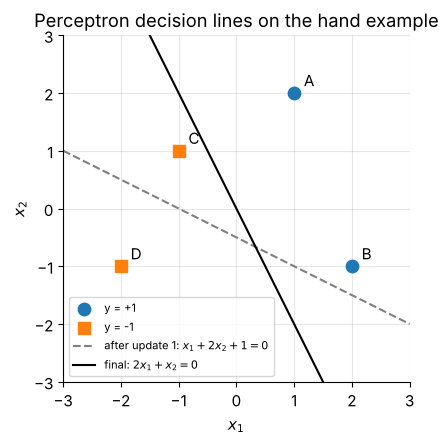

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for label, marker in [(1, "o"), (-1, "s")]:
    m = y_hand == label
    ax.scatter(X_hand[m, 0], X_hand[m, 1], s=80, marker=marker,
               color=CLASS_COLORS[0] if label == 1 else CLASS_COLORS[1], label=f"y = {label:+d}", zorder=3)
for name, (px, py) in zip("ABCD", X_hand):
    ax.annotate(name, (px, py), textcoords="offset points", xytext=(7, 5))
xs_line = np.linspace(-3, 3, 50)
# after the first update: w = (1, 2), b = 1  ->  x2 = -(x1 + 1) / 2
ax.plot(xs_line, -(xs_line + 1) / 2, "--", color="gray", label="after update 1: $x_1 + 2x_2 + 1 = 0$")
# final: w = (2, 1), b = 0  ->  x2 = -2 x1
ax.plot(xs_line, -2 * xs_line, "-", color="black", label="final: $2x_1 + x_2 = 0$")
ax.set(xlim=(-3, 3), ylim=(-3, 3), xlabel="$x_1$", ylabel="$x_2$", title="Perceptron decision lines on the hand example")
ax.set_aspect("equal")
ax.legend(fontsize=8, loc="lower left")
plt.show()

After the first update the line $x_1 + 2x_2 + 1 = 0$ already separates $A$ and $B$ from $D$, but $C$ is on the wrong side. The second update rotates the line until all four points are correct.

### 1.3 The perceptron convergence theorem (with proof)

To state the theorem cleanly, fold the bias into the weights: write $\tilde{\mathbf{x}} = (\mathbf{x}, 1) \in \mathbb{R}^{d+1}$ and $\boldsymbol\theta = (\mathbf{w}, b)$, so that $\mathbf{w}^\top\mathbf{x} + b = \boldsymbol\theta^\top\tilde{\mathbf{x}}$ and the update becomes $\boldsymbol\theta \leftarrow \boldsymbol\theta + y\,\tilde{\mathbf{x}}$.

**Assumptions.**
1. *Bounded data:* $\lVert\tilde{\mathbf{x}}_i\rVert \le R$ for every example.
2. *Separable with margin $\gamma$:* there is a **unit** vector $\mathbf{u}$ ($\lVert\mathbf{u}\rVert = 1$) and a number $\gamma > 0$ with $y_i\,\mathbf{u}^\top\tilde{\mathbf{x}}_i \ge \gamma$ for every $i$. (Every point is at distance at least $\gamma$ from the hyperplane $\mathbf{u}^\top\tilde{\mathbf{x}} = 0$, on its correct side.)

**Theorem (Novikoff, 1962).** Starting from $\boldsymbol\theta_0 = \mathbf{0}$, the perceptron makes at most $(R/\gamma)^2$ mistakes, whatever the order in which examples are visited and however many examples there are.

**Proof.** Let $\boldsymbol\theta_k$ be the weights right after the $k$-th mistake, and suppose that mistake happened on $(\tilde{\mathbf{x}}, y)$.

*Step 1: progress in the right direction grows linearly.* Using assumption 2,

$$
\mathbf{u}^\top\boldsymbol\theta_k = \mathbf{u}^\top\boldsymbol\theta_{k-1} + y\,\mathbf{u}^\top\tilde{\mathbf{x}} \;\ge\; \mathbf{u}^\top\boldsymbol\theta_{k-1} + \gamma,
$$

and since $\mathbf{u}^\top\boldsymbol\theta_0 = 0$, induction gives $\mathbf{u}^\top\boldsymbol\theta_k \ge k\gamma$.

*Step 2: the length grows only like a square root.* Expanding the square,

$$
\lVert\boldsymbol\theta_k\rVert^2 = \lVert\boldsymbol\theta_{k-1}\rVert^2 + 2\,y\,\boldsymbol\theta_{k-1}^\top\tilde{\mathbf{x}} + y^2\lVert\tilde{\mathbf{x}}\rVert^2 \;\le\; \lVert\boldsymbol\theta_{k-1}\rVert^2 + R^2 .
$$

The middle term is $\le 0$ precisely because $(\tilde{\mathbf{x}}, y)$ was a mistake, and $y^2\lVert\tilde{\mathbf{x}}\rVert^2 \le R^2$ by assumption 1. Induction gives $\lVert\boldsymbol\theta_k\rVert^2 \le kR^2$.

*Step 3: combine.* By the Cauchy–Schwarz inequality, $\mathbf{u}^\top\boldsymbol\theta_k \le \lVert\mathbf{u}\rVert\,\lVert\boldsymbol\theta_k\rVert = \lVert\boldsymbol\theta_k\rVert$. Chaining the three facts,

$$
k\gamma \;\le\; \mathbf{u}^\top\boldsymbol\theta_k \;\le\; \lVert\boldsymbol\theta_k\rVert \;\le\; \sqrt{k}\,R
\quad\Longrightarrow\quad \sqrt{k} \le \frac{R}{\gamma}
\quad\Longrightarrow\quad k \le \Big(\frac{R}{\gamma}\Big)^2 .
$$

So the number of mistakes is finite. After the last mistake, the next full pass is clean, and the perceptron has found a separating hyperplane. That completes the proof.

> **Olympiad tip.** This "potential function" argument is a classic: one quantity grows *linearly* with the number of steps while another grows only like the *square root*, yet the first is bounded by the second. Equivalently, the cosine of the angle between $\boldsymbol\theta_k$ and $\mathbf{u}$ is at least $\sqrt{k}\,\gamma/R$, and a cosine can never exceed 1.

Notice what the bound does **not** depend on: the number of examples and the dimension. It depends only on the *geometry*, the ratio of the data's size to the margin. Let us test it on separable datasets with shrinking margins.

In [5]:
def separable_data(n, margin, rng):
    """n points in [-1, 1]^2 labeled by a fixed line, keeping only points at least `margin` from it.

    The 'line' is the hyperplane u . (x1, x2, 1) = 0 for a fixed unit vector u in augmented space,
    exactly the setting of the convergence theorem.
    """
    u = np.array([2.0, -1.0, 0.5])
    u = u / np.linalg.norm(u)
    X = []
    while len(X) < n:
        x = rng.uniform(-1, 1, size=2)
        if abs(np.r_[x, 1.0] @ u) >= margin:          # rejection sampling: keep only far-enough points
            X.append(x)
    X = np.array(X)
    y = np.sign(np.c_[X, np.ones(n)] @ u).astype(int)
    return X, y, u


rows = []
for target_margin in [0.3, 0.2, 0.1, 0.05, 0.02]:
    X_s, y_s, u_s = separable_data(200, target_margin, np.random.default_rng(7))
    X_aug = np.c_[X_s, np.ones(len(X_s))]
    gamma = np.min(y_s * (X_aug @ u_s))                # actual margin with respect to u
    R = np.max(np.linalg.norm(X_aug, axis=1))
    w_s, b_s, per_epoch, _ = perceptron_train(X_s, y_s, max_epochs=1000)
    rows.append({"target margin": target_margin, "gamma": gamma, "R": R,
                 "bound (R/gamma)^2": (R / gamma) ** 2, "mistakes made": sum(per_epoch),
                 "epochs": len(per_epoch), "training errors at end": int(np.sum(np.sign(X_s @ w_s + b_s) != y_s))})
display(pd.DataFrame(rows).round(4))

,target margin,gamma,R,bound (R/gamma)^2,mistakes made,epochs,training errors at end
0,0.30,0.3019,1.6672,30.4963,4,2,0
1,0.20,0.2049,1.6672,66.1978,7,2,0
2,0.10,0.1057,1.6743,251.1001,9,2,0
3,0.05,0.0509,1.6743,1083.5848,23,4,0
4,0.02,0.0329,1.6743,2590.9602,23,2,0


Every run converges to zero training errors, and the number of mistakes always stays below $(R/\gamma)^2$, as the theorem guarantees. The bound is very pessimistic (it must hold for the *worst* possible order of examples), but it captures the trend: a smaller margin means a harder problem. (The rejection sampler sometimes keeps a slightly larger margin than requested, which is why the measured $\gamma$ can exceed the target.)

Three honest limitations:

- If the data are **not** linearly separable, the perceptron never stops: some example is always wrong, so updates go on forever.
- The final line is just *some* separating line, not the "best" one. Support vector machines pick the line with the largest margin.
- A single perceptron can only ever produce a linear boundary. The next subsection shows how severe that restriction is.

### 1.4 XOR: the problem a single neuron cannot solve

The **XOR** (exclusive or) function of two bits outputs 1 when exactly one input is 1:

| $x_1$ | $x_2$ | XOR |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

**Claim.** No line separates the XOR classes: there are no $w_1, w_2, b$ such that $f(\mathbf{x}) = w_1x_1 + w_2x_2 + b$ is positive on both class-1 points and non-positive on both class-0 points.

**Proof.** Suppose such $w_1, w_2, b$ existed. The class-1 points give $f(0,1) = w_2 + b > 0$ and $f(1,0) = w_1 + b > 0$, and adding them gives $w_1 + w_2 + 2b > 0$. The class-0 points give $f(0,0) = b \le 0$ and $f(1,1) = w_1 + w_2 + b \le 0$, and adding them gives $w_1 + w_2 + 2b \le 0$. The same number cannot be both positive and non-positive, so no such line exists.

> **Intuition.** Both sums equal $2f(\tfrac12, \tfrac12)$, because an affine function evaluated at a midpoint equals the average of its values at the endpoints. The two diagonals of the unit square, one joining the class-1 points and one joining the class-0 points, cross at the same midpoint $(\tfrac12, \tfrac12)$. One class demands $f > 0$ there and the other demands $f \le 0$. In general, two finite point sets can be separated by a hyperplane if and only if their *convex hulls* do not intersect, and XOR's two convex hulls (the diagonals) cross.

What does the perceptron do on XOR? Since the theorem's assumption fails, there is no guarantee, and in fact it cycles forever.

In [6]:
X_xor = np.array([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]])
y_xor = np.array([0, 1, 1, 0])                 # XOR labels in {0, 1}
y_xor_pm = 2 * y_xor - 1                       # the same labels in {-1, +1} for the perceptron

w_x, b_x, mistakes_x, trace_x = perceptron_train(X_xor, y_xor_pm, max_epochs=6, record=True)
print("mistakes in each of 6 epochs:", mistakes_x)
epoch1 = pd.DataFrame(trace_x[:4])             # the first epoch, visit by visit
epoch1["point"] = [str(tuple(int(v) for v in X_xor[i])) for i in epoch1["point"]]
display(epoch1)
print("weights after each epoch:", [(t["w after"], t["b after"]) for t in trace_x[3::4]])

mistakes in each of 6 epochs: [4, 4, 4, 4, 4, 4]


,epoch,point,y,score,mistake?,w after,b after
0,1,"(0, 0)",-1,0.0,True,"(0.0, 0.0)",-1.0
1,1,"(0, 1)",1,-1.0,True,"(0.0, 1.0)",0.0
2,1,"(1, 0)",1,0.0,True,"(1.0, 1.0)",1.0
3,1,"(1, 1)",-1,3.0,True,"(0.0, 0.0)",0.0


weights after each epoch: [((0.0, 0.0), 0.0), ((0.0, 0.0), 0.0), ((0.0, 0.0), 0.0), ((0.0, 0.0), 0.0), ((0.0, 0.0), 0.0), ((0.0, 0.0), 0.0)]


In this visiting order, every single visit is a mistake, and after four updates the weights are back to exactly $\mathbf{w} = (0, 0), b = 0$, where they started. The perceptron is trapped in a loop of length four and will repeat it forever.

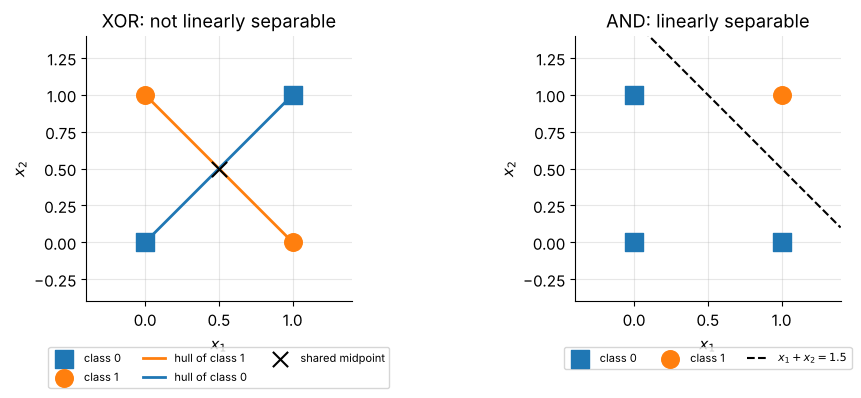

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (title, labels) in zip(axes, [("XOR: not linearly separable", y_xor),
                                      ("AND: linearly separable", np.array([0, 0, 0, 1]))]):
    for cls in (0, 1):
        m = labels == cls
        ax.scatter(X_xor[m, 0], X_xor[m, 1], s=160, color=CLASS_COLORS[cls], label=f"class {cls}", zorder=3,
                   marker="o" if cls == 1 else "s")
    ax.set(xlim=(-0.4, 1.4), ylim=(-0.4, 1.4), xlabel="$x_1$", ylabel="$x_2$", title=title)
    ax.set_aspect("equal")
axes[0].plot([0, 1], [1, 0], color=CLASS_COLORS[1], lw=2, label="hull of class 1")
axes[0].plot([0, 1], [0, 1], color=CLASS_COLORS[0], lw=2, label="hull of class 0")
axes[0].scatter([0.5], [0.5], marker="x", s=120, color="black", zorder=4, label="shared midpoint")
xs_and = np.linspace(-0.4, 1.4, 20)
axes[1].plot(xs_and, 1.5 - xs_and, "k--", label="$x_1 + x_2 = 1.5$")
for ax in axes:
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
fig.tight_layout()
plt.show()

A separating line for AND exists (for example $x_1 + x_2 = 1.5$), while for XOR the two hulls cross at $(\tfrac12, \tfrac12)$, exactly as the proof says.

> **Going deeper.** In 1969 Marvin Minsky and Seymour Papert published *Perceptrons*, a careful analysis of what single-layer perceptrons cannot compute (XOR and, more generally, parity and connectedness). The book is often credited with cooling interest in neural networks for more than a decade. Everyone knew that adding a hidden layer would fix XOR. The real obstacle was *training* it: the perceptron rule needs a target for each unit, and hidden units have no targets. This is the **credit assignment problem**: how much is each hidden weight to blame for the final error? Its solution, popularized for neural networks by Rumelhart, Hinton and Williams in 1986, is **backpropagation** (Section 4): use differentiable activations and the chain rule.

### 1.5 Stacking linear layers is pointless without a nonlinearity

A natural first idea is to stack several linear layers. Using the row-vector convention that we adopt for the rest of the notebook (an input is a row $\mathbf{x} \in \mathbb{R}^{1\times d}$), two linear layers compute

$$
\mathbf{h} = \mathbf{x}W_1 + \mathbf{b}_1, \qquad \hat{\mathbf{y}} = \mathbf{h}W_2 + \mathbf{b}_2 = \mathbf{x}\,\underbrace{(W_1W_2)}_{W_{\text{eff}}} + \underbrace{(\mathbf{b}_1W_2 + \mathbf{b}_2)}_{\mathbf{b}_{\text{eff}}} .
$$

The composition of affine maps is an affine map, so by induction **any number of linear layers collapses into a single one**, with $W_{\text{eff}} = W_1W_2\cdots W_L$. A "deep" network without activations has exactly the decision boundaries of logistic/softmax regression: hyperplanes. It can even be *less* expressive: $\operatorname{rank}(W_{\text{eff}}) \le \min_l \operatorname{rank}(W_l)$, so one narrow layer acts as a bottleneck for everything after it.

In [8]:
rng_c = np.random.default_rng(0)
widths = [4, 16, 2, 3]                         # 4 inputs -> 16 -> 2 (a bottleneck) -> 3 outputs
Ws = [rng_c.normal(size=(widths[i], widths[i + 1])) for i in range(3)]
bs = [rng_c.normal(size=(1, widths[i + 1])) for i in range(3)]
X_lin = rng_c.normal(size=(5, 4))              # a batch of 5 inputs

H = X_lin
for W, b in zip(Ws, bs):
    H = H @ W + b                              # three linear layers, no activation in between

W_eff = Ws[0] @ Ws[1] @ Ws[2]
b_eff = (bs[0] @ Ws[1] + bs[1]) @ Ws[2] + bs[2]
print("max |three layers - one collapsed layer| =", np.abs(H - (X_lin @ W_eff + b_eff)).max())
print("W_eff has shape", W_eff.shape, "but rank", np.linalg.matrix_rank(W_eff), "(limited by the width-2 layer)")

max |three layers - one collapsed layer| = 4.440892098500626e-15
W_eff has shape (4, 3) but rank 2 (limited by the width-2 layer)


The difference is at the level of floating-point round-off ($10^{-15}$ or so): three layers really are one layer. The remedy is to put a **nonlinear** activation between layers, $\mathbf{h} = g(\mathbf{x}W_1 + \mathbf{b}_1)$. Then no collapse is possible, and Section 2 shows that a single hidden layer already solves XOR.

> **Key idea.** Depth only adds expressive power when nonlinearities separate the layers.

> **Going deeper.** Deep *linear* networks are still studied, because although they represent only linear maps, their gradient-descent *training dynamics* are nonlinear and surprisingly rich. For representing functions, though, they add nothing.

**Quick check.** A network applies a ReLU after its first layer and then three more linear layers without activations. Does it collapse to a linear model?

<details>
<summary>Answer</summary>

Not completely. The three final linear layers collapse into one linear layer, but the ReLU layer before them cannot be absorbed. The network is equivalent to an MLP with a single hidden layer: $\hat{\mathbf{y}} = \operatorname{ReLU}(\mathbf{x}W_1 + \mathbf{b}_1)\,W_{\text{eff}} + \mathbf{b}_{\text{eff}}$.
</details>

### ✏️ Exercise 1: collapse a stack of linear layers

Write `collapse_linear(Ws, bs)` that takes lists of weight matrices `Ws[l]` with shape `(n_l, n_{l+1})` and bias rows `bs[l]` with shape `(1, n_{l+1})`, and returns `(W_eff, b_eff)` such that `X @ W_eff + b_eff` equals applying the layers one after another. Hint: start from the identity map and absorb one layer at a time.

In [9]:
# ✏️ Exercise 1: collapse linear layers into one
def collapse_linear(Ws, bs):
    """Return (W_eff, b_eff) equivalent to applying X -> X @ W + b for each (W, b) in order."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    r = np.random.default_rng(1)
    sizes = [3, 5, 4, 2]
    Ws_t = [r.normal(size=(sizes[i], sizes[i + 1])) for i in range(3)]
    bs_t = [r.normal(size=(1, sizes[i + 1])) for i in range(3)]
    X_t = r.normal(size=(7, 3))
    W_e, b_e = collapse_linear(Ws_t, bs_t)
    assert np.shape(W_e) == (3, 2), f"W_eff should have shape (3, 2), got {np.shape(W_e)}"
    assert np.shape(b_e) == (1, 2), f"b_eff should have shape (1, 2), got {np.shape(b_e)}"
    H_t = X_t
    for W_t, b_t in zip(Ws_t, bs_t):
        H_t = H_t @ W_t + b_t
    assert np.allclose(X_t @ W_e + b_e, H_t), "collapsed layer does not reproduce the stack"
    W1_e, b1_e = collapse_linear(Ws_t[:1], bs_t[:1])
    assert np.allclose(W1_e, Ws_t[0]) and np.allclose(b1_e, bs_t[0]), "a single layer should come back unchanged"


run_check("Exercise 1", _test)

⏳ Exercise 1: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def collapse_linear(Ws, bs):
    n_in = Ws[0].shape[0]
    W_eff, b_eff = np.eye(n_in), np.zeros((1, n_in))   # the identity map X -> X
    for W, b in zip(Ws, bs):
        W_eff = W_eff @ W            # (X W_eff + b_eff) W + b = X (W_eff W) + (b_eff W + b)
        b_eff = b_eff @ W + b
    return W_eff, b_eff
```
Each new layer multiplies the accumulated weight matrix on the right and transforms the accumulated bias exactly like an input row, then adds its own bias.
</details>

## 2. The multi-layer perceptron: architecture, notation and the forward pass

### 2.1 Layers, widths and depth

A **multi-layer perceptron** chains several layers of neurons. Every neuron in a layer reads *all* outputs of the previous layer (so these layers are called **fully connected** or **dense**), and each layer applies a nonlinear activation before passing its outputs on. Here is the tiny network we will compute with by hand throughout the notebook: 2 inputs, one hidden layer of 3 ReLU units, and 2 outputs.

```
    input layer          hidden layer (ReLU)          output layer (logits)
     (2 features)          (3 units)                    (2 classes)

       x1 ───────────┬──────►  h1 ─────────┬──────────►  z1 ─┐
                     ├──────►  h2 ─────────┤               ├──► softmax ──► (p1, p2)
       x2 ───────────┴──────►  h3 ─────────┴──────────►  z2 ─┘

           every input feeds every hidden unit (2 x 3 weights + 3 biases)
           every hidden unit feeds every output (3 x 2 weights + 2 biases)
```

Vocabulary:

- The **input layer** is just the feature vector. It does no computation.
- **Hidden layers** sit between input and output. Their values never appear in the data (nobody tells the network what $h_1$ should be), hence "hidden".
- The **output layer** produces the prediction: one number for regression, one logit per class for classification.
- The **width** of a layer is its number of units, and the **depth** is the number of layers with weights. The network above is a *2-layer* MLP (one hidden layer + the output layer), with widths $2 \to 3 \to 2$. Conventions for counting layers vary between authors, so when in doubt, list the widths.

> **Common pitfall.** Despite the name, the units of a modern MLP are *not* perceptrons: they use differentiable activations instead of the sign function, precisely so that gradients can flow through them (Section 4).

### 2.2 Notation for a mini-batch

We process a **mini-batch** of $m$ examples at once and store it the way data tables are stored: **one example per row**. This *row-major* convention matches NumPy and PyTorch, so our formulas and our code will read the same.

| symbol | meaning | shape |
|---|---|---|
| $m$ | number of examples in the mini-batch | scalar |
| $L$ | number of layers with weights (hidden layers + output layer) | scalar |
| $n_l$ | width of layer $l$ ($n_0 = d$ is the number of input features) | scalar |
| $X = A^{[0]}$ | input batch, row $i$ is example $\mathbf{x}_i$ | $m \times n_0$ |
| $W^{[l]}$ | weights of layer $l$, where column $j$ holds the incoming weights of unit $j$ | $n_{l-1} \times n_l$ |
| $\mathbf{b}^{[l]}$ | bias row of layer $l$ | $1 \times n_l$ |
| $Z^{[l]}$ | pre-activations of layer $l$ | $m \times n_l$ |
| $A^{[l]}$ | activations (outputs) of layer $l$ | $m \times n_l$ |
| $g^{[l]}$ | activation function of layer $l$, applied elementwise | |

The **forward pass** is the loop

$$
Z^{[l]} = A^{[l-1]}\,W^{[l]} + \mathbf{b}^{[l]}, \qquad A^{[l]} = g^{[l]}\big(Z^{[l]}\big), \qquad l = 1, 2, \dots, L .
$$

Entry by entry, for example $i$ and unit $j$ of layer $l$:

$$
z^{[l]}_{ij} = \sum_{k=1}^{n_{l-1}} a^{[l-1]}_{ik}\, w^{[l]}_{kj} + b^{[l]}_j .
$$

Adding the $1 \times n_l$ row $\mathbf{b}^{[l]}$ to the $m \times n_l$ matrix $A^{[l-1]}W^{[l]}$ means adding it to *every row*. NumPy does this automatically (**broadcasting**): every example gets the same biases.

For the output layer we usually take $g^{[L]}$ to be the identity, so $Z^{[L]}$ holds raw scores called **logits**. The softmax (or sigmoid) is applied inside the loss function, for reasons explained in Section 3.5.

> **Common pitfall.** Many textbooks use the *column* convention $\mathbf{z} = W\mathbf{x} + \mathbf{b}$ with $W \in \mathbb{R}^{n_l \times n_{l-1}}$, which is the transpose of ours. PyTorch's `nn.Linear` also stores its weight with shape `(out_features, in_features)` and computes `x @ weight.T + bias`. So PyTorch's `weight` equals our $W^\top$. Nothing deep is going on, but forgetting a transpose is the most common bug when moving weights between conventions (we will do it carefully in Sections 5 and 11).

### 2.3 Counting parameters

Layer $l$ has $n_{l-1} n_l$ weights and $n_l$ biases, so the whole network has

$$
P = \sum_{l=1}^{L} \big(n_{l-1} + 1\big)\, n_l
$$

parameters. For our $2 \to 3 \to 2$ network: $(2 + 1)\cdot 3 + (3 + 1)\cdot 2 = 9 + 8 = 17$.

A more realistic example: in Notebook 13 you will classify $48 \times 48$ grayscale face images into 7 expressions. Each image is flattened into $48 \cdot 48 = 2304$ numbers and fed to a "pyramid" MLP whose hidden widths halve, $2304 \to 256 \to 128 \to 64 \to 7$, with

$$
(2304 + 1)\cdot 256 + (256 + 1)\cdot 128 + (128 + 1)\cdot 64 + (64 + 1)\cdot 7 = 590{,}080 + 32{,}896 + 8{,}256 + 455 = 631{,}687
$$

parameters. A common reflex, examined in Notebook 13, is to upsample every image to $128 \times 128$ first. Here is the count for that bigger version, $16384 \to 256 \to 128 \to 64 \to 7$ (each image is now flattened into $128 \cdot 128 = 16384$ numbers):

In [10]:
def layer_table(sizes):
    """Parameter count of each dense layer of an MLP with the given widths."""
    rows = []
    for l in range(1, len(sizes)):
        n_in, n_out = sizes[l - 1], sizes[l]
        rows.append({"layer": l, "shape of W": f"{n_in} x {n_out}", "weights": n_in * n_out,
                     "biases": n_out, "total": (n_in + 1) * n_out})
    return pd.DataFrame(rows)


print("2 -> 3 -> 2 network:", layer_table([2, 3, 2])["total"].sum(), "parameters")
pyramid = layer_table([128 * 128, 256, 128, 64, 7])
pyramid["share of all parameters"] = pyramid["total"] / pyramid["total"].sum()
display(pyramid)
print(f"total: {pyramid['total'].sum():,} parameters")

2 -> 3 -> 2 network: 17 parameters


,layer,shape of W,weights,biases,total,share of all parameters
0,1,16384 x 256,4194304,256,4194560,0.9902
1,2,256 x 128,32768,128,32896,0.0078
2,3,128 x 64,8192,64,8256,0.0019
3,4,64 x 7,448,7,455,0.0001


total: 4,236,167 parameters


Over 4.2 million parameters, and **99% of them sit in the first layer**, because every one of the 16384 pixels connects to every one of the 256 first-layer units. (At the native $48 \times 48$ resolution the first layer still holds 93% of the 631,687 parameters, and Notebook 13 shows that upsampling multiplies the parameters but adds no information.) This is the main weakness of MLPs on images: they ignore the fact that neighboring pixels belong together, and pay for it with a huge first layer. Convolutional networks, later in the series, fix exactly this.

> **Olympiad tip.** Parameter counting is a favorite exam question. Count "inputs × outputs" weights plus "outputs" biases for each layer, and remember that activations, softmax and losses have no parameters.

### 2.4 A forward pass by hand

Let us push a mini-batch of $m = 2$ examples through the $2 \to 3 \to 2$ network with ReLU hidden units, $\operatorname{ReLU}(z) = \max(0, z)$. The parameters were chosen to keep the arithmetic friendly:

$$
X = \begin{pmatrix} 1 & 2 \\ 2 & -1 \end{pmatrix}, \quad
W^{[1]} = \begin{pmatrix} -0.5 & 0.5 & -0.5 \\ 1 & 0.5 & -1 \end{pmatrix}, \quad
\mathbf{b}^{[1]} = \begin{pmatrix} -0.5 & 0 & 0.5 \end{pmatrix},
$$

$$
W^{[2]} = \begin{pmatrix} 0.5 & -1 \\ -0.5 & 1 \\ -0.5 & -1 \end{pmatrix}, \quad
\mathbf{b}^{[2]} = \begin{pmatrix} 0 & 0 \end{pmatrix}, \quad
\text{labels } \mathbf{y} = (0, 1).
$$

**Hidden layer.** Each entry of $Z^{[1]} = XW^{[1]} + \mathbf{b}^{[1]}$ is "row of $X$" dotted with "column of $W^{[1]}$", plus a bias:

| | unit 1 | unit 2 | unit 3 |
|---|---|---|---|
| example 1, $\mathbf{x} = (1, 2)$ | $1(-0.5) + 2(1) - 0.5 = 1.0$ | $1(0.5) + 2(0.5) + 0 = 1.5$ | $1(-0.5) + 2(-1) + 0.5 = -2.0$ |
| example 2, $\mathbf{x} = (2, -1)$ | $2(-0.5) - 1(1) - 0.5 = -2.5$ | $2(0.5) - 1(0.5) + 0 = 0.5$ | $2(-0.5) - 1(-1) + 0.5 = 0.5$ |

ReLU zeroes the negative entries: $A^{[1]} = \begin{pmatrix} 1 & 1.5 & 0 \\ 0 & 0.5 & 0.5 \end{pmatrix}$. Each example "switches off" a different unit.

**Output layer.** $Z^{[2]} = A^{[1]}W^{[2]} + \mathbf{b}^{[2]}$:

| | logit of class 0 | logit of class 1 |
|---|---|---|
| example 1 | $1(0.5) + 1.5(-0.5) + 0 = -0.25$ | $1(-1) + 1.5(1) + 0 = 0.5$ |
| example 2 | $0 + 0.5(-0.5) + 0.5(-0.5) = -0.5$ | $0 + 0.5(1) + 0.5(-1) = 0$ |

**Softmax and loss.** For example 1, $e^{-0.25} \approx 0.7788$ and $e^{0.5} \approx 1.6487$, so $p = (0.7788, 1.6487)/2.4275 \approx (0.3208, 0.6792)$. For example 2, $e^{-0.5} \approx 0.6065$ and $e^{0} = 1$, so $p \approx (0.3775, 0.6225)$. The cross-entropy of each example is $-\log(\text{probability of the true class})$:

$$
\ell_1 = -\log 0.3208 \approx 1.1369 \;(\text{true class 0, predicted wrongly}), \qquad
\ell_2 = -\log 0.6225 \approx 0.4741 \;(\text{true class 1, predicted correctly}),
$$

and the mini-batch loss is the mean, $\mathcal{L} = (1.1369 + 0.4741)/2 \approx 0.8055$. Now the same computation in NumPy:

In [11]:
# The tiny network used for every hand computation in this notebook.
X_tiny = np.array([[1.0, 2.0], [2.0, -1.0]])
y_tiny = np.array([0, 1])
W1_tiny = np.array([[-0.5, 0.5, -0.5], [1.0, 0.5, -1.0]])
b1_tiny = np.array([[-0.5, 0.0, 0.5]])
W2_tiny = np.array([[0.5, -1.0], [-0.5, 1.0], [-0.5, -1.0]])
b2_tiny = np.array([[0.0, 0.0]])

Z1 = X_tiny @ W1_tiny + b1_tiny          # (2, 2) @ (2, 3) + (1, 3) -> (2, 3)
A1 = np.maximum(Z1, 0.0)                 # ReLU, elementwise
Z2 = A1 @ W2_tiny + b2_tiny              # (2, 3) @ (3, 2) + (1, 2) -> (2, 2): logits
P = np.exp(Z2) / np.exp(Z2).sum(axis=1, keepdims=True)    # softmax of each row
per_example = -np.log(P[np.arange(2), y_tiny])             # cross-entropy of each example
print("Z1 =\n", Z1, "\nA1 =\n", A1, "\nZ2 (logits) =\n", Z2, "\nP =\n", P)
print("per-example losses:", per_example.round(4), " mean loss:", round(per_example.mean(), 4))

Z1 =
 [[ 1.   1.5 -2. ]
 [-2.5  0.5  0.5]] 
A1 =
 [[1.  1.5 0. ]
 [0.  0.5 0.5]] 
Z2 (logits) =
 [[-0.25  0.5 ]
 [-0.5   0.  ]] 
P =
 [[0.3208 0.6792]
 [0.3775 0.6225]]
per-example losses: [1.1369 0.4741]  mean loss: 0.8055


Every number matches the hand computation. Notice the indexing trick `P[np.arange(2), y_tiny]`: it picks entry `(i, y_i)` from each row, the probability of each example's true class.

### 2.5 Shapes for a general mini-batch

The safest habit when working with networks is to write the shape next to every quantity. For a network with widths $n_0 \to n_1 \to \dots \to n_L$:

| quantity | computation | shape |
|---|---|---|
| input | $A^{[0]} = X$ | $m \times n_0$ |
| pre-activation | $Z^{[l]} = A^{[l-1]}W^{[l]} + \mathbf{b}^{[l]}$ | $(m \times n_{l-1})(n_{l-1} \times n_l) + (1 \times n_l) \to m \times n_l$ |
| activation | $A^{[l]} = g(Z^{[l]})$ | $m \times n_l$ (elementwise, shape unchanged) |
| logits | $Z^{[L]}$ | $m \times n_L$ (one row of class scores per example) |
| probabilities | $\operatorname{softmax}$ of each row of $Z^{[L]}$ | $m \times n_L$, each row sums to 1 |
| loss | mean of the $m$ per-example losses | scalar |

The inner dimensions must agree ($n_{l-1}$), and the batch size $m$ passes through untouched: the network treats each row independently, so the *same* code works for one example or a million.

### 2.6 What hidden layers do: they learn new features

Why does a hidden layer help? Because it **re-describes the input**. The output layer is still a linear model, but it now looks at the hidden activations $\mathbf{h} = g(\mathbf{x}W^{[1]} + \mathbf{b}^{[1]})$ instead of the raw inputs. If the hidden layer maps the data into a space where the classes *are* linearly separable, the problem is solved.

Here is a hand-built network that computes XOR exactly:

$$
h_1 = \operatorname{ReLU}(x_1 + x_2), \qquad h_2 = \operatorname{ReLU}(x_1 + x_2 - 1), \qquad \hat y = h_1 - 2h_2 ,
$$

that is, $W^{[1]} = \begin{pmatrix} 1 & 1 \\ 1 & 1 \end{pmatrix}$, $\mathbf{b}^{[1]} = (0, -1)$, $W^{[2]} = \begin{pmatrix} 1 \\ -2 \end{pmatrix}$, $b^{[2]} = 0$. On the four corners:

| $\mathbf{x}$ | $(h_1, h_2)$ | $\hat y = h_1 - 2h_2$ | XOR |
|---|---|---|---|
| $(0, 0)$ | $(0, 0)$ | $0$ | 0 |
| $(0, 1)$ | $(1, 0)$ | $1$ | 1 |
| $(1, 0)$ | $(1, 0)$ | $1$ | 1 |
| $(1, 1)$ | $(2, 1)$ | $0$ | 0 |

In the hidden space the two class-1 points land on the *same* point $(1, 0)$, and a straight line (for example $h_1 - 2h_2 = 0.5$) separates the classes.

hidden features:
 [[0. 0.]
 [1. 0.]
 [1. 0.]
 [2. 1.]] 
outputs: [0. 1. 1. 0.]  (XOR: [0 1 1 0] )


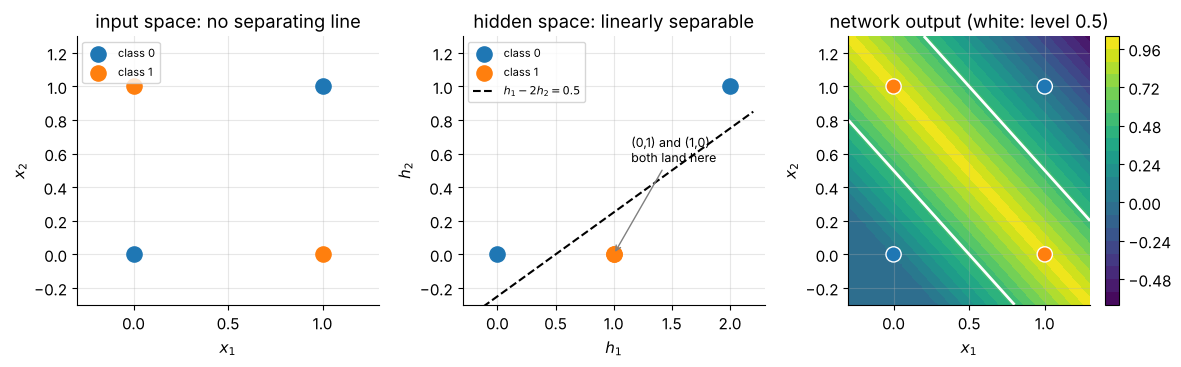

In [12]:
W1_xor = np.array([[1.0, 1.0], [1.0, 1.0]])
b1_xor = np.array([[0.0, -1.0]])
W2_xor = np.array([[1.0], [-2.0]])


def xor_net(X):
    """Hand-built 2 -> 2 -> 1 ReLU network. Returns (hidden activations, output)."""
    H = np.maximum(X @ W1_xor + b1_xor, 0.0)
    return H, H @ W2_xor


H_xor, out_xor = xor_net(X_xor)
print("hidden features:\n", H_xor, "\noutputs:", out_xor.ravel(), " (XOR:", y_xor, ")")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for cls in (0, 1):
    m = y_xor == cls
    axes[0].scatter(X_xor[m, 0], X_xor[m, 1], s=120, color=CLASS_COLORS[cls], label=f"class {cls}", zorder=3)
    axes[1].scatter(H_xor[m, 0], H_xor[m, 1], s=120, color=CLASS_COLORS[cls], label=f"class {cls}", zorder=3)
h1_line = np.linspace(-0.2, 2.2, 10)
axes[1].plot(h1_line, (h1_line - 0.5) / 2, "k--", label="$h_1 - 2h_2 = 0.5$")
axes[1].annotate("(0,1) and (1,0)\nboth land here", xy=(1.0, 0.0), xytext=(1.15, 0.55), fontsize=9,
                 arrowprops=dict(arrowstyle="->", color="gray"))
axes[0].set(title="input space: no separating line", xlabel="$x_1$", ylabel="$x_2$", xlim=(-0.3, 1.3), ylim=(-0.3, 1.3))
axes[1].set(title="hidden space: linearly separable", xlabel="$h_1$", ylabel="$h_2$", xlim=(-0.3, 2.3), ylim=(-0.3, 1.3))
grid = np.linspace(-0.3, 1.3, 201)
G1, G2 = np.meshgrid(grid, grid)
_, out_grid = xor_net(np.c_[G1.ravel(), G2.ravel()])
im = axes[2].contourf(G1, G2, out_grid.reshape(G1.shape), levels=20, cmap="viridis")
axes[2].contour(G1, G2, out_grid.reshape(G1.shape), levels=[0.5], colors="white", linewidths=2)
axes[2].scatter(X_xor[:, 0], X_xor[:, 1], c=[CLASS_COLORS[c] for c in y_xor], s=120, edgecolors="white", zorder=3)
axes[2].set(title="network output (white: level 0.5)", xlabel="$x_1$", ylabel="$x_2$")
fig.colorbar(im, ax=axes[2])
for ax in axes[:2]:
    ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

The right panel shows the whole function the network computes. Along the diagonal direction $s = x_1 + x_2$ the output is a "tent": it rises from 0 at $s = 0$ to 1 at $s = 1$ and falls back to 0 at $s = 2$. Thresholding at $0.5$ carves out the diagonal band $0.5 < x_1 + x_2 < 1.5$, which contains exactly the two class-1 corners. Two ReLU units, i.e. two lines, were enough to build a non-linear region.

> **Key idea.** An MLP is "a linear model on learned features". The hidden layers compute a representation $\mathbf{h} = \phi(\mathbf{x})$, and the output layer is ordinary logistic/softmax/linear regression on $\mathbf{h}$. Training learns $\phi$ and the final linear model *at the same time*. This is the sense in which deep learning is **representation learning**.

**Quick check.** How many parameters does this XOR network have, and which of them could you delete without changing its output?

<details>
<summary>Answer</summary>

$W^{[1]}$ has 4 weights, $\mathbf{b}^{[1]}$ has 2 biases, $W^{[2]}$ has 2 weights and $b^{[2]}$ has 1 bias: 9 parameters. The output bias is 0 and the first hidden bias is 0, so those two could be removed. The remaining 7 are all needed in this construction.
</details>

### ✏️ Exercise 2: parameters and compute of an MLP

Write `mlp_cost(sizes, m)` for an MLP with widths `sizes = [n_0, n_1, ..., n_L]`. It must return a pair `(n_params, n_mult_adds)`: the number of parameters (weights + biases) and the number of scalar **multiply-add** operations in the matrix products $A^{[l-1]}W^{[l]}$ during one forward pass of a mini-batch of `m` examples (ignore biases and activations for the second number). Each output entry $z_{ij}$ needs $n_{l-1}$ multiply-adds.

In [13]:
# ✏️ Exercise 2: count parameters and multiply-adds
def mlp_cost(sizes, m):
    """Return (number of parameters, multiply-adds of one forward pass on m examples)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    out = mlp_cost([2, 3, 2], 1)
    assert np.shape(out) == (2,), f"return a pair (n_params, n_mult_adds), got {out!r}"
    assert tuple(out) == (17, 12), f"tiny network: got {out}"
    assert tuple(mlp_cost([2, 3, 2], 10)) == (17, 120), "multiply-adds scale linearly with the batch size m"
    assert mlp_cost([10, 64, 32, 3], 1)[0] == 2883, "check the parameter count of 10 -> 64 -> 32 -> 3"
    n_p, n_ma = mlp_cost([16384, 256, 128, 64, 7], 256)
    assert n_p == 4236167, f"pyramid parameters: got {n_p}"
    assert n_ma == 256 * (16384 * 256 + 256 * 128 + 128 * 64 + 64 * 7), "pyramid multiply-adds are wrong"


run_check("Exercise 2", _test)

⏳ Exercise 2: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def mlp_cost(sizes, m):
    n_params = sum((a + 1) * b for a, b in zip(sizes[:-1], sizes[1:]))
    n_mult_adds = m * sum(a * b for a, b in zip(sizes[:-1], sizes[1:]))
    return n_params, n_mult_adds
```
Layer $l$ computes an $m \times n_l$ output, and each entry is a dot product of length $n_{l-1}$, so it costs $m\,n_{l-1}n_l$ multiply-adds. For the $128 \times 128$ pyramid with $m = 256$ that is about $1.08 \times 10^9$ per forward pass, almost all of it in the first layer.
</details>

### ✏️ Exercise 3: a general forward pass

Implement `mlp_forward(X, params)` where `params` is a list of `(W, b)` pairs. Apply ReLU after every layer **except the last**, which returns raw logits. Return the logits together with the list of all pre-activations `[Z1, ..., ZL]` (you will need such a cache for backpropagation).

In [14]:
# ✏️ Exercise 3: forward pass of an MLP with ReLU hidden layers
def mlp_forward(X, params):
    """X: (m, n_0), and params: [(W1, b1), ..., (WL, bL)] with W_l of shape (n_{l-1}, n_l), b_l of shape (1, n_l).

    Returns (logits of shape (m, n_L), [Z1, ..., ZL]).
    """
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    logits, Zs = mlp_forward(X_tiny, [(W1_tiny, b1_tiny), (W2_tiny, b2_tiny)])
    assert np.allclose(logits, [[-0.25, 0.5], [-0.5, 0.0]]), f"tiny network logits wrong: {logits}"
    assert len(Zs) == 2 and np.allclose(Zs[0], [[1.0, 1.5, -2.0], [-2.5, 0.5, 0.5]]), "cache of Z's is wrong"
    r = np.random.default_rng(3)
    sizes = [5, 8, 6, 4]
    params = [(r.normal(size=(a, b)), r.normal(size=(1, b))) for a, b in zip(sizes[:-1], sizes[1:])]
    X_t = r.normal(size=(7, 5))
    logits, Zs = mlp_forward(X_t, params)
    assert logits.shape == (7, 4), f"logits should have shape (7, 4), got {logits.shape}"
    assert [Z.shape for Z in Zs] == [(7, 8), (7, 6), (7, 4)], f"wrong cache shapes {[Z.shape for Z in Zs]}"
    H = np.maximum(X_t @ params[0][0] + params[0][1], 0)
    H = np.maximum(H @ params[1][0] + params[1][1], 0)
    assert np.allclose(logits, H @ params[2][0] + params[2][1]), "values do not match a reference forward pass"
    assert np.allclose(logits, Zs[-1]), "the last cached Z should be the logits (no ReLU on the output)"


run_check("Exercise 3", _test)

⏳ Exercise 3: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def mlp_forward(X, params):
    A, Zs = X, []
    for l, (W, b) in enumerate(params):
        Z = A @ W + b
        Zs.append(Z)
        A = np.maximum(Z, 0.0) if l < len(params) - 1 else Z   # no ReLU on the output layer
    return A, Zs
```
The loop is the forward-pass formula $Z^{[l]} = A^{[l-1]}W^{[l]} + \mathbf{b}^{[l]}$, $A^{[l]} = g(Z^{[l]})$, with $g$ the identity on the last layer.
</details>

## 3. Activation functions, output layers and losses

### 3.1 What makes a good activation function?

Section 1.5 showed that the activation must be **nonlinear**, or the layers collapse. Beyond that, training by gradient descent asks for a few more properties:

1. **Useful derivatives.** Backpropagation (Section 4) multiplies the gradient by $g'(z)$ at every layer. If $g'$ is tiny over most of its input range, the learning signal fades.
2. **Cheap to compute.** A network evaluates its activation billions of times.
3. **Nice to have:** outputs centered around zero (it keeps the next layer's inputs balanced) and no flat regions where the unit gets stuck.

### 3.2 The activation zoo

| name | $g(z)$ | $g'(z)$ | range | remarks |
|---|---|---|---|---|
| sigmoid | $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ | $\sigma(z)\,(1 - \sigma(z))$ | $(0, 1)$ | max slope $\tfrac14$ at $0$, saturates, and is not zero-centered |
| tanh | $\tanh z = \dfrac{e^{z} - e^{-z}}{e^{z} + e^{-z}} = 2\sigma(2z) - 1$ | $1 - \tanh^2 z$ | $(-1, 1)$ | zero-centered, max slope $1$, and it saturates |
| ReLU | $\max(0, z)$ | $1$ if $z > 0$, $0$ if $z < 0$ | $[0, \infty)$ | very cheap, never saturates for $z > 0$, but units can "die" |
| Leaky ReLU | $\max(\alpha z, z)$, e.g. $\alpha = 0.01$ | $1$ if $z > 0$, $\alpha$ if $z < 0$ | $\mathbb{R}$ | a small slope keeps negative units alive |
| GELU | $z\,\Phi(z)$ | $\Phi(z) + z\,\varphi(z)$ | $\approx[-0.17, \infty)$ | smooth ReLU-like curve, used in many Transformers (BERT, GPT-2, ViT) |
| softplus | $\log(1 + e^{z})$ | $\sigma(z)$ | $(0, \infty)$ | a smooth version of ReLU |

Here $\Phi$ and $\varphi$ are the cumulative distribution function and the density of the standard normal distribution: $\Phi(z) = \tfrac12\big(1 + \operatorname{erf}(z/\sqrt2)\big)$ and $\varphi(z) = e^{-z^2/2}/\sqrt{2\pi}$.

The derivatives are short calculations worth doing once:

- **Sigmoid.** $\sigma(z) = (1 + e^{-z})^{-1}$, so $\sigma'(z) = \dfrac{e^{-z}}{(1 + e^{-z})^2} = \underbrace{\dfrac{1}{1 + e^{-z}}}_{\sigma(z)} \cdot \underbrace{\dfrac{e^{-z}}{1 + e^{-z}}}_{1 - \sigma(z)}$. The maximum of $s(1 - s)$ over $s \in (0, 1)$ is $\tfrac14$, reached at $s = \tfrac12$, i.e. $z = 0$.
- **Tanh.** Since $\tanh z = 2\sigma(2z) - 1$, the chain rule gives $\tanh' z = 4\sigma'(2z) = 4s(1 - s)$ with $s = \sigma(2z)$, and indeed $1 - \tanh^2 z = 1 - (2s - 1)^2 = 4s - 4s^2$. So tanh is a sigmoid stretched to $(-1, 1)$, with slope $1$ at the origin.
- **Softplus.** $\dfrac{d}{dz}\log(1 + e^{z}) = \dfrac{e^{z}}{1 + e^{z}} = \sigma(z)$: the derivative of the smooth ReLU is the sigmoid.
- **GELU.** Product rule with $\Phi' = \varphi$: $\dfrac{d}{dz}\big(z\,\Phi(z)\big) = \Phi(z) + z\,\varphi(z)$.
- **ReLU.** The slope is $0$ on the left and $1$ on the right. At exactly $z = 0$ the derivative does not exist, and libraries simply use $0$ there (any value in $[0, 1]$ is a valid *subgradient*). In floating point, hitting exactly $0$ is rare enough not to matter.

Below, each activation and its derivative is written in NumPy. Two implementation details deserve attention: the sigmoid and softplus are written so that $e^{z}$ never overflows for large $|z|$.

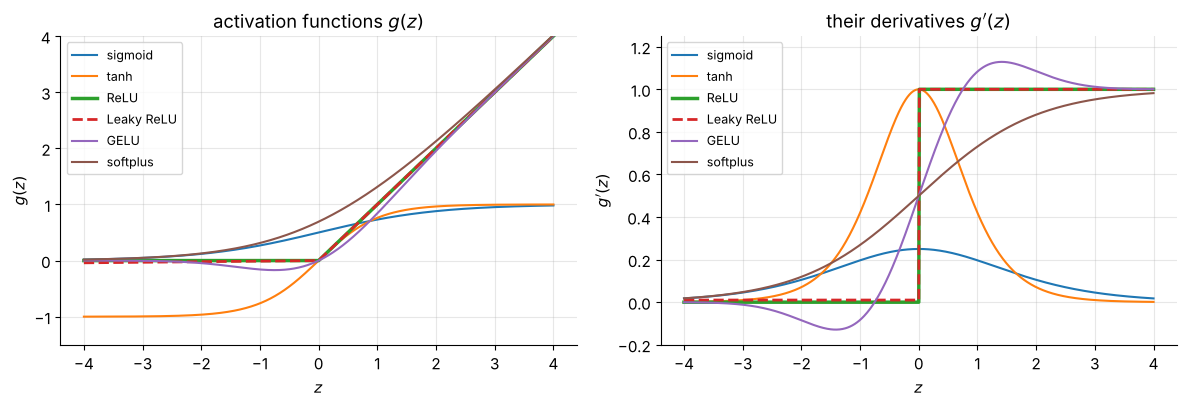

In [15]:
def sigmoid(z):
    """Numerically stable logistic function: never computes exp of a large positive number."""
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])                      # z < 0 here, so exp(z) < 1 cannot overflow
    out[~pos] = ez / (1.0 + ez)
    return out


def softplus(z):
    """log(1 + e^z) computed stably as max(z, 0) + log(1 + e^{-|z|})."""
    z = np.asarray(z, dtype=float)
    return np.maximum(z, 0.0) + np.log1p(np.exp(-np.abs(z)))


def std_normal_cdf(z):
    return 0.5 * (1.0 + erf(z / np.sqrt(2.0)))


def std_normal_pdf(z):
    return np.exp(-0.5 * z ** 2) / np.sqrt(2.0 * np.pi)


LEAK = 0.01
# name -> (activation g, derivative g')
ACTIVATIONS = {
    "sigmoid": (sigmoid, lambda z: sigmoid(z) * (1.0 - sigmoid(z))),
    "tanh": (np.tanh, lambda z: 1.0 - np.tanh(z) ** 2),
    "ReLU": (lambda z: np.maximum(z, 0.0), lambda z: (z > 0).astype(float)),
    "Leaky ReLU": (lambda z: np.where(z > 0, z, LEAK * z), lambda z: np.where(z > 0, 1.0, LEAK)),
    "GELU": (lambda z: z * std_normal_cdf(z), lambda z: std_normal_cdf(z) + z * std_normal_pdf(z)),
    "softplus": (softplus, sigmoid),
}

z_plot = np.linspace(-4, 4, 801)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for name, (g, dg) in ACTIVATIONS.items():
    style = dict(ls="--", lw=2) if name == "Leaky ReLU" else dict(lw=2.5 if name == "ReLU" else 1.5)
    axes[0].plot(z_plot, g(z_plot), label=name, **style)
    axes[1].plot(z_plot, dg(z_plot), label=name, **style)
axes[0].set(title="activation functions $g(z)$", xlabel="$z$", ylabel="$g(z)$", ylim=(-1.5, 4))
axes[1].set(title="their derivatives $g'(z)$", xlabel="$z$", ylabel="$g'(z)$", ylim=(-0.2, 1.25))
for ax in axes:
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

Things to notice in the right panel: the sigmoid's slope never exceeds $0.25$, sigmoid and tanh slopes melt to zero for $|z| \gtrsim 3$, ReLU's slope is a clean step from 0 to 1, and GELU's slope even dips slightly below zero and overshoots 1, because GELU is not monotonic (it has a small negative "dip"). Let us measure that dip and check all six derivative formulas twice: against **central finite differences** and against **PyTorch autograd**.

In [16]:
z_chk = np.linspace(-4, 4, 161)
z_chk = z_chk[np.abs(z_chk) > 1e-3]          # stay away from the ReLU kink at 0
h = 1e-5
torch_fns = {"sigmoid": torch.sigmoid, "tanh": torch.tanh, "ReLU": torch.relu,
             "Leaky ReLU": lambda t: nn.functional.leaky_relu(t, LEAK), "GELU": nn.functional.gelu,
             "softplus": nn.functional.softplus}
rows = []
for name, (g, dg) in ACTIVATIONS.items():
    fd = (g(z_chk + h) - g(z_chk - h)) / (2 * h)                  # central difference
    zt = torch.tensor(z_chk, requires_grad=True)
    torch_fns[name](zt).sum().backward()                          # d(sum g)/dz_i = g'(z_i)
    rows.append({"activation": name,
                 "max |formula - finite diff|": np.abs(dg(z_chk) - fd).max(),
                 "max |formula - autograd|": np.abs(dg(z_chk) - zt.grad.numpy()).max(),
                 "max |g - torch g|": np.abs(g(z_chk) - torch_fns[name](torch.tensor(z_chk)).numpy()).max()})
display(pd.DataFrame(rows))

gelu = ACTIVATIONS["GELU"][0]
z_fine = np.linspace(-3, 0, 300001)
i_min = np.argmin(gelu(z_fine))
print(f"GELU minimum: g({z_fine[i_min]:.4f}) = {gelu(z_fine)[i_min]:.4f}")
gelu_tanh = 0.5 * z_plot * (1 + np.tanh(np.sqrt(2 / np.pi) * (z_plot + 0.044715 * z_plot ** 3)))
print(f"max |exact GELU - tanh approximation| on [-4, 4]: {np.abs(gelu(z_plot) - gelu_tanh).max():.1e}")

,activation,max |formula - finite diff|,max |formula - autograd|,max |g - torch g|
0,sigmoid,1.1264e-11,5.5511e-17,1.1102e-16
1,tanh,3.2917e-11,2.6541e-16,1.1102e-16
2,ReLU,1.5653e-11,0.0000e+00,0.0000e+00
3,Leaky ReLU,1.5653e-11,0.0000e+00,0.0000e+00
4,GELU,4.4760e-11,2.2204e-16,2.2204e-16
5,softplus,2.6352e-11,2.2204e-16,4.4409e-16


GELU minimum: g(-0.7518) = -0.1700
max |exact GELU - tanh approximation| on [-4, 4]: 4.7e-04


All three columns are tiny (finite differences agree to better than $10^{-10}$, autograd to machine precision), so the formulas in the table are right. GELU dips to about $-0.17$ near $z \approx -0.75$. Many libraries also offer a cheaper tanh-based approximation of GELU, which differs from the exact curve by less than $10^{-3}$.

> **Going deeper.** Why GELU? Think of it as a *soft gate*: the input $z$ is multiplied by $\Phi(z)$, the probability that a standard normal variable is below $z$. Large positive inputs pass almost unchanged, large negative inputs are almost blocked, and the transition is smooth. A close cousin is **SiLU** (also called Swish), $z\,\sigma(z)$, which you will differentiate in Exercise 4.

### 3.3 Saturation and vanishing gradients

A unit **saturates** when its input lands on a flat part of the curve. There $g'(z) \approx 0$, so almost no gradient flows back through the unit, whatever the error is.

In [17]:
z_sat = np.array([0.0, 2.0, 5.0, 10.0])
display(pd.DataFrame({name: ACTIVATIONS[name][1](z_sat) for name in ["sigmoid", "tanh", "ReLU"]},
                     index=pd.Index(z_sat, name="z")).T.rename(columns=lambda v: f"g'({v:g})"))

z,g'(0),g'(2),g'(5),g'(10)
sigmoid,0.25,0.1050,0.0066,4.5396e-05
tanh,1.00,0.0707,0.0002,8.2446e-09
ReLU,0.00,1.0000,1.0000,1.0000e+00


At $z = 5$ the sigmoid's slope is already below $0.007$, and tanh's is below $2 \times 10^{-4}$. Saturation becomes a serious problem in **deep** networks, because backpropagation *multiplies* one local derivative per layer. Consider the simplest deep "network": a chain of scalar units $a_l = g(a_{l-1})$, all weights equal to 1. By the chain rule,

$$
\frac{\partial a_L}{\partial a_0} = \prod_{l=1}^{L} g'(a_{l-1}) .
$$

With sigmoids every factor is at most $\tfrac14$, so the product is at most $4^{-L}$: about $10^{-6}$ for $L = 10$. This exponential decay of the learning signal with depth is the **vanishing gradient problem**.

In [18]:
def chain_derivative(g, dg, depth, a0=0.5):
    """d a_L / d a_0 for the scalar chain a_l = g(a_{l-1})."""
    a, deriv = a0, 1.0
    for _ in range(depth):
        deriv *= float(dg(np.array(a)))
        a = float(g(np.array(a)))
    return deriv


depths = [1, 2, 5, 10, 20]
display(pd.DataFrame({name: [chain_derivative(*ACTIVATIONS[name], L) for L in depths]
                      for name in ["sigmoid", "tanh", "ReLU"]}, index=pd.Index(depths, name="depth L")))
print("upper bound for sigmoid chains, 4^-L:", [f"{4.0 ** -L:.1e}" for L in depths])

,sigmoid,tanh,ReLU
depth L,,,
1,2.3500e-01,0.7864,1.0
2,5.3408e-02,0.6398,1.0
5,6.0799e-04,0.3930,1.0
10,3.4831e-07,0.2228,1.0
20,1.1431e-13,0.1073,1.0


upper bound for sigmoid chains, 4^-L: ['2.5e-01', '6.2e-02', '9.8e-04', '9.5e-07', '9.1e-13']


Starting from $a_0 = 0.5$, the sigmoid chain loses roughly a factor of 4 to 5 per layer (its derivatives sit near $0.2$), tanh decays far more slowly (its slope near zero is close to 1), and ReLU passes the derivative through **exactly** unchanged as long as the unit is active. This is one of the main reasons ReLU-like activations made deep networks trainable. In real networks the weights also multiply the gradient at each layer, so gradients can *explode* as well as vanish. Section 7 shows how a good initialization keeps the per-layer factor close to 1.

### 3.4 Dead ReLUs

ReLU has its own failure mode. If a unit's pre-activation $z = \mathbf{w}^\top\mathbf{x} + b$ is negative **for every training input**, the unit outputs 0 everywhere *and* its local derivative is 0 everywhere. No gradient ever reaches $\mathbf{w}$ or $b$, so gradient descent can never revive it: the unit is **dead**. Typical causes are a learning rate so large that one update throws $b$ far into the negative range, or an unlucky initialization. Leaky ReLU keeps a small slope $\alpha$ on the negative side, so the unit always receives *some* gradient.

In [19]:
x_in = torch.linspace(0, 2, 101).reshape(-1, 1)                      # inputs in [0, 2]
for name, act in [("ReLU", torch.relu), ("Leaky ReLU", lambda t: nn.functional.leaky_relu(t, LEAK))]:
    w = torch.tensor([[1.0]], requires_grad=True)
    b = torch.tensor([-3.0], requires_grad=True)                     # z = x - 3 < 0 for every input
    out = act(x_in @ w + b)
    out.mean().backward()
    print(f"{name:>10}: mean output {out.mean().item():+.4f} | dL/dw = {w.grad.item():+.4f} | dL/db = {b.grad.item():+.4f}")

      ReLU: mean output +0.0000 | dL/dw = +0.0000 | dL/db = +0.0000
Leaky ReLU: mean output -0.0200 | dL/dw = +0.0100 | dL/db = +0.0100


The dead ReLU unit receives exactly zero gradient. The leaky one receives a small but nonzero gradient ($\alpha = 0.01$ times the slope it would otherwise have) and can recover. Section 6 measures how many units die when the learning rate is too large.

### 3.5 Output layers and their matching losses

The hidden activation is a design choice, and the **output** layer is dictated by the task. Each task has a natural "output activation + loss" pair:

| task | output units | output activation (applied inside the loss) | loss for one example | $\partial \ell / \partial z$ |
|---|---|---|---|---|
| regression | 1 per target | identity, $\hat y = z$ | squared error $(\hat y - y)^2$ | $2(\hat y - y)$ |
| binary classification, $y \in \{0, 1\}$ | 1 logit | sigmoid, $p = \sigma(z)$ | binary cross-entropy $-[y\log p + (1 - y)\log(1 - p)]$ | $p - y$ |
| $K$-class classification | $K$ logits | softmax, $p_k = e^{z_k} / \sum_j e^{z_j}$ | cross-entropy $-\log p_{y}$ | $\mathbf{p} - \mathbf{y}$ (one-hot $\mathbf{y}$) |

Look at the last column: in all three cases the gradient with respect to the output pre-activation is simply **prediction minus target** (up to the factor 2 for squared error, which disappears if you use $\tfrac12(\hat y - y)^2$). This is not a coincidence: each pair corresponds to a probability model (Gaussian, Bernoulli, categorical) with its "canonical" link function, and maximum likelihood then always produces this clean gradient. The softmax case is derived carefully in Section 4.4. Here is the binary one.

**Binary cross-entropy from a logit.** Use $\log\sigma(z) = -\log(1 + e^{-z}) = -\operatorname{softplus}(-z)$ and $\log(1 - \sigma(z)) = \log\sigma(-z) = -\operatorname{softplus}(z)$:

$$
\ell(z, y) = y\,\operatorname{softplus}(-z) + (1 - y)\operatorname{softplus}(z) = \operatorname{softplus}(z) - y\,z ,
$$

using $\operatorname{softplus}(-z) = \operatorname{softplus}(z) - z$. Differentiating, $\partial\ell/\partial z = \sigma(z) - y = p - y$. The last form, $\operatorname{softplus}(z) - yz = \max(z, 0) - yz + \log(1 + e^{-|z|})$, is also the numerically safe way to compute the loss: no exponential of a large number, no logarithm of zero.

**Why we feed logits, not probabilities, to the loss.** Computing $p$ first and then $\log p$ throws away precision: when the true class is very unlikely, $p$ underflows to exactly $0$ and $\log 0 = -\infty$. Working with logits, $\log p_k = z_k - \log\sum_j e^{z_j}$, and the log-sum-exp is computed safely by factoring out the largest logit. This is why PyTorch's `nn.CrossEntropyLoss` and `nn.BCEWithLogitsLoss` take **raw logits**, and why a classification network's last layer has **no activation**.

In [20]:
z_bad = np.array([[-120.0, 0.0]], dtype=np.float32)     # true class 0 is extremely unlikely
p_naive = np.exp(z_bad) / np.exp(z_bad).sum(axis=1, keepdims=True)
with np.errstate(divide="ignore"):                       # we *want* to show the log(0) here
    loss_naive = -np.log(p_naive[0, 0])
lse = z_bad.max() + np.log(np.exp(z_bad - z_bad.max()).sum())   # log-sum-exp with the max factored out
loss_stable = -(z_bad[0, 0] - lse)
loss_torch = nn.functional.cross_entropy(torch.tensor(z_bad), torch.tensor([0]))
print(f"float32 softmax-then-log: p = {p_naive[0, 0]}, loss = {loss_naive}")
print(f"log-sum-exp from logits:  loss = {loss_stable:.4f}   (PyTorch cross_entropy: {loss_torch.item():.4f})")

float32 softmax-then-log: p = 0.0, loss = inf
log-sum-exp from logits:  loss = 120.0000   (PyTorch cross_entropy: 120.0000)


The naive route returns an infinite loss (and would produce NaN gradients). The logit route returns the correct value $120$.

> **Common pitfall: the double softmax.** If your PyTorch model ends with `nn.Softmax` *and* you train it with `nn.CrossEntropyLoss`, softmax is applied twice. The loss then sees "logits" that are probabilities in $[0, 1]$, so the second softmax can never become confident: with $K = 3$ classes, the best possible input is a one-hot vector, giving at most $e/(e + 2) \approx 0.576$ for the true class and a loss that can never fall below $\approx 0.551$. The model still trains, but badly. Let the loss do the softmax.

In [21]:
best_q = torch.tensor([[1.0, 0.0, 0.0]])                  # the "most confident" probabilities a model can output
print("double-softmax probability of the true class:", torch.softmax(best_q, dim=1)[0, 0].item())
print("lowest achievable loss:", nn.functional.cross_entropy(best_q, torch.tensor([0])).item())

double-softmax probability of the true class: 0.5761169195175171
lowest achievable loss: 0.5514446496963501


**Why cross-entropy rather than squared error for classification?** Compare the two losses for a sigmoid output when the true label is $y = 1$:

$$
\frac{\partial}{\partial z}\big(\sigma(z) - 1\big)^2 = 2\big(\sigma(z) - 1\big)\,\sigma(z)\big(1 - \sigma(z)\big), \qquad
\frac{\partial}{\partial z}\Big(-\log\sigma(z)\Big) = \sigma(z) - 1 .
$$

The squared-error gradient carries the extra factor $\sigma'(z) = \sigma(z)(1 - \sigma(z))$, which vanishes when the model is *confidently wrong* ($z \ll 0$). Exactly when learning matters most, the signal disappears. Cross-entropy's $\log$ cancels the sigmoid's saturation.

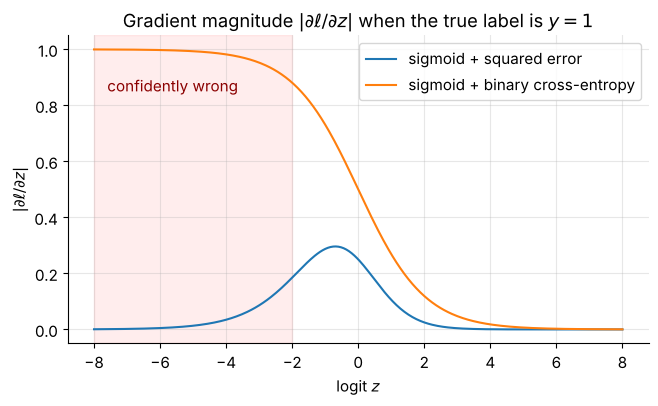

at z = -6.0: squared-error gradient -0.0049, cross-entropy gradient -0.9975


In [22]:
z_cmp = np.linspace(-8, 8, 401)
s = sigmoid(z_cmp)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(z_cmp, np.abs(2 * (s - 1) * s * (1 - s)), label="sigmoid + squared error")
ax.plot(z_cmp, np.abs(s - 1), label="sigmoid + binary cross-entropy")
ax.axvspan(-8, -2, color="red", alpha=0.07)
ax.text(-7.6, 0.85, "confidently wrong", color="darkred")
ax.set(title="Gradient magnitude $|\\partial \\ell / \\partial z|$ when the true label is $y = 1$",
       xlabel="logit $z$", ylabel="$|\\partial \\ell / \\partial z|$")
ax.legend()
plt.show()
z_wrong = -6.0
s_w = sigmoid(np.array(z_wrong))
print(f"at z = {z_wrong}: squared-error gradient {2 * (s_w - 1) * s_w * (1 - s_w):.4f}, "
      f"cross-entropy gradient {s_w - 1:.4f}")

At $z = -6$ the cross-entropy gradient is about $200$ times larger than the squared-error one.

**Quick check.** You build a classifier for 7 facial expressions. What should the last layer of the network output, and what do you pass to `nn.CrossEntropyLoss` as targets?

<details>
<summary>Answer</summary>

The last layer should be a plain linear layer with 7 outputs and **no activation**: it outputs 7 logits per image. The targets are the class indices $0, \dots, 6$ as a tensor of integers (`dtype=torch.long`), one per image. The loss applies log-softmax internally. (To report probabilities later, apply `torch.softmax(logits, dim=1)` yourself, outside the loss.)
</details>

### ✏️ Exercise 4: derivatives of two more activations

Derive and implement the derivatives of

- **SiLU** (also called Swish): $\operatorname{silu}(z) = z\,\sigma(z)$,
- **ELU** with $\alpha = 1$: $\operatorname{elu}(z) = z$ for $z > 0$ and $\alpha(e^{z} - 1)$ for $z \le 0$.

Use the `sigmoid` function defined above. Both functions take and return NumPy arrays.

In [23]:
# ✏️ Exercise 4: derivatives of SiLU and ELU
def silu_grad(z):
    """Derivative of z * sigmoid(z)."""
    # YOUR CODE HERE
    raise NotImplementedError


def elu_grad(z, alpha=1.0):
    """Derivative of ELU: 1 for z > 0, alpha * exp(z) for z <= 0."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    z = np.linspace(-6, 6, 241)
    z = z[np.abs(z) > 1e-3]
    h = 1e-5
    silu = lambda t: t * sigmoid(t)
    elu = lambda t: np.where(t > 0, t, np.expm1(np.minimum(t, 0)))
    fd_silu = (silu(z + h) - silu(z - h)) / (2 * h)
    fd_elu = (elu(z + h) - elu(z - h)) / (2 * h)
    assert np.allclose(silu_grad(z), fd_silu, atol=1e-6), "silu_grad disagrees with finite differences"
    assert np.allclose(elu_grad(z), fd_elu, atol=1e-6), "elu_grad disagrees with finite differences"
    assert np.isclose(float(silu_grad(np.array(0.0))), 0.5), "silu'(0) should be 1/2"
    assert np.allclose(elu_grad(np.array([-1.0, 2.0]), alpha=0.5), [0.5 * np.exp(-1.0), 1.0]), "alpha is not used correctly"


run_check("Exercise 4", _test)

⏳ Exercise 4: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def silu_grad(z):
    s = sigmoid(z)
    return s + z * s * (1.0 - s)        # product rule: (z)' s + z s'

def elu_grad(z, alpha=1.0):
    return np.where(z > 0, 1.0, alpha * np.exp(np.minimum(z, 0.0)))
```
For SiLU, the product rule gives $\sigma(z) + z\,\sigma(z)(1 - \sigma(z))$, which equals $\tfrac12$ at $z = 0$. For ELU, the negative branch $\alpha(e^z - 1)$ has derivative $\alpha e^z$ (the `np.minimum` only avoids computing a huge, unused `exp` on the positive side).
</details>

### ✏️ Exercise 5: stable binary cross-entropy from logits

Implement `bce_with_logits(z, y)` returning `(loss, grad)`: the **mean** binary cross-entropy over the $m$ entries of `z` (logits) with targets `y` in $\{0, 1\}$, and its gradient with respect to `z`. It must not overflow or return `inf` for logits like $\pm 1000$. Use the identities derived in Section 3.5.

In [24]:
# ✏️ Exercise 5: binary cross-entropy computed from logits
def bce_with_logits(z, y):
    """z, y: arrays of shape (m,). Returns (mean loss, gradient of the mean loss w.r.t. z)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    z = np.array([-1000.0, -2.0, 0.0, 3.0, 1000.0])
    y = np.array([1.0, 0.0, 1.0, 1.0, 0.0])
    loss, grad = bce_with_logits(z, y)
    zt = torch.tensor(z, requires_grad=True)
    ref = nn.functional.binary_cross_entropy_with_logits(zt, torch.tensor(y))
    ref.backward()
    assert np.isfinite(loss) and np.all(np.isfinite(grad)), "loss and gradient must be finite"
    assert np.isclose(loss, ref.item()), f"loss {loss} differs from PyTorch's {ref.item()}"
    assert np.allclose(grad, zt.grad.numpy()), f"gradient {grad} differs from PyTorch's {zt.grad.numpy()}"
    assert np.shape(grad) == z.shape, "the gradient must have the same shape as z"


run_check("Exercise 5", _test)

⏳ Exercise 5: not implemented yet. Fill in the function and re-run this cell.

<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def bce_with_logits(z, y):
    m = z.shape[0]
    losses = np.maximum(z, 0.0) - y * z + np.log1p(np.exp(-np.abs(z)))   # softplus(z) - y z
    grad = (sigmoid(z) - y) / m                                         # d(mean)/dz = (p - y)/m
    return losses.mean(), grad
```
The loss uses $\operatorname{softplus}(z) - yz$ with the stable softplus, and the gradient is $(p - y)$ divided by $m$ because we average over the $m$ examples. For $z = -1000$ and $y = 1$ the loss correctly comes out as $1000$.
</details>

## 4. Backpropagation: deriving every gradient

### 4.1 The problem: one derivative per parameter

Training means gradient descent on the average loss $\mathcal{L}(\boldsymbol\theta)$, where $\boldsymbol\theta$ collects every weight and bias:

$$
\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\,\nabla_{\boldsymbol\theta}\mathcal{L}(\boldsymbol\theta).
$$

So at every step we need $\partial\mathcal{L}/\partial\theta_j$ for **every** parameter: 17 numbers for the tiny network, 4.2 million for the upsampled $128 \times 128$ image pyramid of Section 2.3. The most obvious method is the **finite difference**

$$
\frac{\partial\mathcal{L}}{\partial\theta_j} \approx \frac{\mathcal{L}(\boldsymbol\theta + h\,\mathbf{e}_j) - \mathcal{L}(\boldsymbol\theta - h\,\mathbf{e}_j)}{2h},
$$

where $\mathbf{e}_j$ is the $j$-th unit vector. It needs two forward passes *per parameter*: $2P$ passes per training step, 8.5 million for that pyramid. Hopeless.

**Backpropagation** computes the *exact* gradient with respect to all $P$ parameters at the cost of roughly **three forward passes**, whatever $P$ is. It is nothing more than the chain rule, applied in a clever order. We build it up in three steps: scalar computational graphs (4.2), matrix-valued layers (4.3–4.5), and a complete numeric example (4.6).

### 4.2 Computational graphs and local gradients

Any formula can be broken into elementary operations and drawn as a **computational graph**: nodes are intermediate values, arrows show which values feed which operations. Take a single sigmoid neuron with a squared-error loss, $\mathcal{L} = (\sigma(wx + b) - y)^2$, at $x = 2$, $w = 0.5$, $b = -1.5$, $y = 1$:

```
  w ──┐
      (×)──► u ──┐
  x ──┘          (+)──► z ──► (σ) ──► a ──┐
  b ─────────────┘                        (−)──► e ──► (·)² ──► L
  y ──────────────────────────────────────┘
```

**Forward pass** (left to right): $u = wx = 1$, $z = u + b = -0.5$, $a = \sigma(z) \approx 0.3775$, $e = a - y \approx -0.6225$, $\mathcal{L} = e^2 \approx 0.3875$.

**Backward pass** (right to left). For every node $v$ define its **adjoint** $\bar v = \partial\mathcal{L}/\partial v$, the sensitivity of the final loss to that node. Start with $\bar{\mathcal{L}} = 1$. Each node only needs its **local derivative** (how its output changes with its input) and the adjoint of the node it feeds, because the chain rule says

$$
\bar v = \bar c \cdot \frac{\partial c}{\partial v} \qquad \text{for a node } v \text{ that feeds a single node } c .
$$

| node | local derivative | adjoint $\bar v = \partial\mathcal{L}/\partial v$ |
|---|---|---|
| $e$ | $\partial\mathcal{L}/\partial e = 2e$ | $\bar e = 2(-0.6225) = -1.2449$ |
| $a$ | $\partial e/\partial a = 1$ | $\bar a = -1.2449$ |
| $z$ | $\partial a/\partial z = \sigma(z)(1 - \sigma(z)) = 0.2350$ | $\bar z = -1.2449 \times 0.2350 = -0.2926$ |
| $b$ | $\partial z/\partial b = 1$ | $\bar b = -0.2926$ |
| $u$ | $\partial z/\partial u = 1$ | $\bar u = -0.2926$ |
| $w$ | $\partial u/\partial w = x = 2$ | $\bar w = -0.2926 \times 2 = -0.5851$ |
| $x$ | $\partial u/\partial x = w = 0.5$ | $\bar x = -0.2926 \times 0.5 = -0.1463$ |

The signs make sense: the neuron outputs $0.38$ but should output $1$, so increasing $w$ or $b$ (negative gradient) would reduce the loss, and gradient descent will do exactly that. Let PyTorch's autograd confirm the table:

In [25]:
x_s, y_s = torch.tensor(2.0), torch.tensor(1.0)
w_s = torch.tensor(0.5, requires_grad=True)
b_s = torch.tensor(-1.5, requires_grad=True)
loss_s = (torch.sigmoid(w_s * x_s + b_s) - y_s) ** 2
loss_s.backward()                                    # reverse pass through the recorded graph
print(f"loss = {loss_s.item():.4f} | dL/dw = {w_s.grad.item():.4f} | dL/db = {b_s.grad.item():.4f}")

loss = 0.3875 | dL/dw = -0.5851 | dL/db = -0.2926


**Patterns worth memorizing.** Looking at how adjoints flow through common nodes saves a lot of algebra:

- **Add** ($z = u + b$): the adjoint is passed unchanged to *both* inputs (a "distributor").
- **Multiply** ($u = wx$): each input receives the adjoint times the *other* input (a "swap"): $\bar w = \bar u\,x$, $\bar x = \bar u\,w$.
- **Max / ReLU**: the adjoint is routed to the input that won, and the loser gets 0.
- **Fan-out** (a value used in several places): the adjoints from all uses **add up**. For $f = xy + x$, the variable $x$ feeds two nodes, so $\bar x = y\cdot 1 + 1 = y + 1$. This is the multivariable chain rule, $\frac{\partial f}{\partial x} = \sum_{c} \frac{\partial f}{\partial c}\frac{\partial c}{\partial x}$ over every node $c$ that uses $x$.

**Why backwards?** A node's adjoint depends on the adjoints of the nodes that *use* it, so we must visit nodes in reverse order of the forward computation. The payoff: the shared part of the chain, here $\bar z$, is computed **once** and reused for $w$, $b$ and $x$. In a network, the adjoint of a layer's output is reused for all of that layer's weights and for everything before it. This reuse (dynamic programming over the graph) is the entire reason backprop is cheap.

> **Going deeper.** Backpropagation is a special case of **reverse-mode automatic differentiation**. Its sibling, *forward mode*, pushes derivatives along with values from inputs to outputs, which yields the derivative with respect to one input direction per pass. For a function with $P$ inputs (the parameters) and one output (the loss), forward mode needs $P$ passes and reverse mode needs one. That asymmetry is why every deep-learning library is built on reverse mode. The price is memory: reverse mode must store the intermediate values of the forward pass until the backward pass uses them.

### 4.3 The chain rule for layers: two rules are enough

In an MLP the nodes are matrices ($Z^{[l]}$, $A^{[l]}$, $W^{[l]}$, ...), but the same idea applies entry by entry. For any matrix $M$, write $\bar M = \partial\mathcal{L}/\partial M$ for the matrix of partial derivatives with the **same shape** as $M$. Only two kinds of nodes occur in an MLP.

**Rule 1: elementwise activation**, $A = g(Z)$. Entry $a_{ij}$ depends only on $z_{ij}$, so

$$
\bar Z = \bar A \odot g'(Z),
$$

where $\odot$ is the elementwise (Hadamard) product. (The full Jacobian of this map would be a huge diagonal matrix, and we never build it.)

**Rule 2: linear layer**, $Z = AW + \mathbf{b}$ with $A \in \mathbb{R}^{m\times n}$, $W \in \mathbb{R}^{n\times k}$, $\mathbf{b} \in \mathbb{R}^{1\times k}$. Given $\bar Z \in \mathbb{R}^{m\times k}$,

$$
\bar W = A^\top \bar Z \;\;(n\times k), \qquad \bar A = \bar Z\,W^\top \;\;(m\times n), \qquad \bar{\mathbf{b}} = \sum_{i=1}^{m} \bar Z_{i,:} \;\;(1\times k).
$$

*Proof with indices.* Entry by entry, $z_{ij} = \sum_{p} a_{ip}w_{pj} + b_j$. The weight $w_{pq}$ appears only in the entries $z_{iq}$ of column $q$ (one per example $i$), each time multiplied by $a_{ip}$. Summing over every place it appears,

$$
\frac{\partial\mathcal{L}}{\partial w_{pq}} = \sum_{i=1}^{m} \frac{\partial\mathcal{L}}{\partial z_{iq}}\,a_{ip} = \big(A^\top\bar Z\big)_{pq} .
$$

Similarly $a_{rp}$ appears in every entry $z_{rj}$ of row $r$, multiplied by $w_{pj}$, so $\partial\mathcal{L}/\partial a_{rp} = \sum_j \bar z_{rj}w_{pj} = (\bar Z W^\top)_{rp}$. And $b_q$ appears in every entry of column $q$ with coefficient 1, so $\partial\mathcal{L}/\partial b_q = \sum_i \bar z_{iq}$. That proves all three formulas.

Notice the bias rule: the bias row is broadcast to all $m$ examples, a fan-out, so its gradient **sums over the batch**. The weights are shared by all examples too, which is why $A^\top\bar Z$ also sums over the batch (it is a sum of $m$ outer products, one per example).

> **Olympiad tip (the shape trick).** $\bar W$ must have the shape of $W$, $n \times k$. The only way to multiply $A$ ($m\times n$) and $\bar Z$ ($m\times k$) into an $n\times k$ matrix is $A^\top\bar Z$. Likewise $\bar A$ must be $m \times n$, which forces $\bar Z W^\top$. Use shapes to *recall* and *sanity-check* formulas, but derive them once with indices: shapes cannot catch a wrong sign or a missing factor.

### 4.4 The output layer: softmax + cross-entropy gives $P - Y$

Take one example with logits $\mathbf{z} \in \mathbb{R}^K$, probabilities $p_k = e^{z_k}/\sum_j e^{z_j}$ and one-hot label $\mathbf{y}$ (so $\sum_k y_k = 1$). Since $\log p_k = z_k - \log\sum_j e^{z_j}$,

$$
\ell = -\sum_{k} y_k\log p_k = -\sum_k y_k z_k + \Big(\sum_k y_k\Big)\log\sum_j e^{z_j} = -\sum_k y_k z_k + \log\sum_j e^{z_j}.
$$

Differentiating with respect to $z_c$ (the derivative of the log-sum-exp is exactly the softmax):

$$
\frac{\partial\ell}{\partial z_c} = -y_c + \frac{e^{z_c}}{\sum_j e^{z_j}} = p_c - y_c, \qquad\text{that is,}\qquad \frac{\partial\ell}{\partial\mathbf{z}} = \mathbf{p} - \mathbf{y}.
$$

*The long way round* gives the same answer and shows why the pair is so well behaved. The softmax Jacobian is $\partial p_k/\partial z_c = p_k(\mathbb{1}[k = c] - p_c)$ and $\partial\ell/\partial p_k = -y_k/p_k$, so

$$
\frac{\partial\ell}{\partial z_c} = \sum_k \Big(-\frac{y_k}{p_k}\Big)\,p_k\big(\mathbb{1}[k = c] - p_c\big) = -y_c + p_c\sum_k y_k = p_c - y_c .
$$

The dangerous $1/p_k$ (huge when $p_k$ is tiny) cancels exactly against the softmax derivative. That is why libraries fuse softmax and cross-entropy into one operation.

For a mini-batch, stack the probabilities into $P \in \mathbb{R}^{m\times K}$ and the one-hot labels into $Y \in \mathbb{R}^{m\times K}$. With the mean loss $\mathcal{L} = \frac1m\sum_i\ell_i$,

$$
\bar Z^{[L]} = \frac{\partial\mathcal{L}}{\partial Z^{[L]}} = \frac{1}{m}\,(P - Y).
$$

Each row of $P - Y$ sums to zero, its entries lie in $(-1, 1)$, and it is largest for confidently wrong examples: a bounded, self-correcting error signal.

### 4.5 The backward recursion

> **Key idea (our batch convention).** Let $\delta^{[l]} \in \mathbb{R}^{m\times n_l}$ be the matrix whose row $i$ is $\partial\ell_i/\partial\mathbf{z}^{[l]}_i$, the **error signal** of example $i$ at layer $l$, *not* divided by $m$. Because the batch loss is the mean $\mathcal{L} = \frac1m\sum_i\ell_i$, we have $\bar Z^{[l]} = \delta^{[l]}/m$, and the $\frac1m$ shows up exactly once, in the parameter gradients.

**Output layer.** From Sections 3.5 and 4.4:

$$
\delta^{[L]} = P - Y \;\;\text{(softmax + CE)}, \qquad \delta^{[L]} = \mathbf{p} - \mathbf{y} \;\;\text{(sigmoid + BCE)}, \qquad \delta^{[L]} = 2(\hat Y - Y) \;\;\text{(identity + squared error)}.
$$

**Hidden layers**, $l = L-1, \dots, 1$. Layer $l+1$ computes $Z^{[l+1]} = A^{[l]}W^{[l+1]} + \mathbf{b}^{[l+1]}$ from $A^{[l]} = g(Z^{[l]})$. Rule 2 carries the error signal back through the weights and Rule 1 through the activation:

$$
\boxed{\;\delta^{[l]} = \big(\delta^{[l+1]}\,W^{[l+1]\top}\big) \odot g'\big(Z^{[l]}\big)\;}
\qquad (m\times n_{l+1})(n_{l+1}\times n_l) \to m\times n_l .
$$

**Parameter gradients**, for every layer $l = L, \dots, 1$ (Rule 2 with $\bar Z^{[l]} = \delta^{[l]}/m$):

$$
\boxed{\;\nabla_{W^{[l]}}\mathcal{L} = \frac{1}{m}\,A^{[l-1]\top}\,\delta^{[l]}\;} \;\; (n_{l-1}\times n_l),
\qquad
\boxed{\;\nabla_{\mathbf{b}^{[l]}}\mathcal{L} = \frac{1}{m}\sum_{i=1}^{m}\delta^{[l]}_{i,:}\;} \;\; (1\times n_l),
$$

that is, the weight gradient is the **average over the batch of the outer products** $\mathbf{a}^{[l-1]\top}_i\boldsymbol\delta^{[l]}_i$, and the bias gradient is the **mean of the rows** of $\delta^{[l]}$.

The whole algorithm in pseudocode:

```
forward:   A[0] = X
           for l = 1..L:   Z[l] = A[l-1] @ W[l] + b[l];   A[l] = g(Z[l])     # cache Z[l], A[l]
           P = softmax(Z[L]);   loss = mean_i( -log P[i, y_i] )
backward:  D = P - Y                                     # delta[L], shape (m, n_L)
           for l = L, L-1, ..., 1:
               dW[l] = A[l-1].T @ D / m                  # shape of W[l]
               db[l] = mean of the rows of D             # shape of b[l]
               if l > 1:  D = (D @ W[l].T) * g'(Z[l-1])  # delta[l-1], uses the current W[l]
update:    for every l:  W[l] -= lr * dW[l];   b[l] -= lr * db[l]
```

> **Common pitfall.** Four classic bugs: (1) updating $W^{[l]}$ *before* using it to propagate $\delta$ further back (compute all gradients first, then update). (2) evaluating $g'$ somewhere other than the cached $Z^{[l]}$ of the same forward pass. (3) dividing by $m$ twice, once in the loss gradient and again in $\nabla W$ (decide where the $\frac1m$ lives, exactly once). (4) summing the bias gradient over the wrong axis: it sums over **examples** (`axis=0`), never over units.

Libraries such as PyTorch carry $\bar Z^{[l]} = \delta^{[l]}/m$ instead of $\delta^{[l]}$: the loss's backward step returns $(P - Y)/m$, and then $\nabla W^{[l]} = A^{[l-1]\top}\bar Z^{[l]}$ and $\nabla\mathbf{b}^{[l]}$ is the column sum of $\bar Z^{[l]}$. Same numbers, different bookkeeping. Our library in Section 5 does it this way too.

### 4.6 A complete backward pass by hand

Let us continue the forward pass of Section 2.4 (batch of $m = 2$, labels $\mathbf{y} = (0, 1)$, loss $0.8055$).

**Step 1: output error.** $\delta^{[2]} = P - Y$:

$$
\delta^{[2]} = \begin{pmatrix} 0.3208 - 1 & 0.6792 - 0 \\ 0.3775 - 0 & 0.6225 - 1 \end{pmatrix} = \begin{pmatrix} -0.6792 & 0.6792 \\ 0.3775 & -0.3775 \end{pmatrix}.
$$

Example 1 (true class 0, given only $0.32$) pushes the class-0 logit up and the class-1 logit down. Example 2 is already right and asks for more confidence.

**Step 2: output-layer gradients.** With $A^{[1]} = \begin{pmatrix} 1 & 1.5 & 0 \\ 0 & 0.5 & 0.5 \end{pmatrix}$, compute $\nabla W^{[2]} = \tfrac12 A^{[1]\top}\delta^{[2]}$ row by row (one row per hidden unit):

| hidden unit | $\partial\mathcal{L}/\partial w_{u,0}$ | $\partial\mathcal{L}/\partial w_{u,1}$ |
|---|---|---|
| 1 | $\tfrac12\big(1(-0.6792) + 0(0.3775)\big) = -0.3396$ | $\tfrac12\big(1(0.6792) + 0(-0.3775)\big) = 0.3396$ |
| 2 | $\tfrac12\big(1.5(-0.6792) + 0.5(0.3775)\big) = -0.4150$ | $\tfrac12\big(1.5(0.6792) + 0.5(-0.3775)\big) = 0.4150$ |
| 3 | $\tfrac12\big(0(-0.6792) + 0.5(0.3775)\big) = 0.0944$ | $\tfrac12\big(0(0.6792) + 0.5(-0.3775)\big) = -0.0944$ |

and $\nabla\mathbf{b}^{[2]}$ = mean of the rows of $\delta^{[2]}$ $= \big(\tfrac{-0.6792 + 0.3775}{2}, \tfrac{0.6792 - 0.3775}{2}\big) = (-0.1508, 0.1508)$. Hidden unit 1 was silent for example 2 ($a = 0$), so only example 1 contributes to its row.

**Step 3: back into the hidden layer.** First through the weights, $\delta^{[2]}W^{[2]\top}$ with $W^{[2]\top} = \begin{pmatrix} 0.5 & -0.5 & -0.5 \\ -1 & 1 & -1 \end{pmatrix}$:

| | unit 1 | unit 2 | unit 3 |
|---|---|---|---|
| example 1 | $-0.6792(0.5) + 0.6792(-1) = -1.0188$ | $-0.6792(-0.5) + 0.6792(1) = 1.0188$ | $-0.6792(-0.5) + 0.6792(-1) = -0.3396$ |
| example 2 | $0.3775(0.5) - 0.3775(-1) = 0.5663$ | $0.3775(-0.5) - 0.3775(1) = -0.5663$ | $0.3775(-0.5) - 0.3775(-1) = 0.1888$ |

then through the ReLU: multiply by $g'(Z^{[1]}) = \mathbb{1}[Z^{[1]} > 0] = \begin{pmatrix} 1 & 1 & 0 \\ 0 & 1 & 1 \end{pmatrix}$, which zeroes the units that were off:

$$
\delta^{[1]} = \begin{pmatrix} -1.0188 & 1.0188 & 0 \\ 0 & -0.5663 & 0.1888 \end{pmatrix}.
$$

**Step 4: hidden-layer gradients.** $\nabla W^{[1]} = \tfrac12 X^\top\delta^{[1]}$ with $X^\top = \begin{pmatrix} 1 & 2 \\ 2 & -1 \end{pmatrix}$:

| input | unit 1 | unit 2 | unit 3 |
|---|---|---|---|
| $x_1$ | $\tfrac12\big(1(-1.0188) + 2(0)\big) = -0.5094$ | $\tfrac12\big(1(1.0188) + 2(-0.5663)\big) = -0.0569$ | $\tfrac12\big(1(0) + 2(0.1888)\big) = 0.1888$ |
| $x_2$ | $\tfrac12\big(2(-1.0188) - 1(0)\big) = -1.0188$ | $\tfrac12\big(2(1.0188) - 1(-0.5663)\big) = 1.3019$ | $\tfrac12\big(2(0) - 1(0.1888)\big) = -0.0944$ |

and $\nabla\mathbf{b}^{[1]}$ = mean of the rows of $\delta^{[1]}$ $= (-0.5094, 0.2262, 0.0944)$.

That is all 17 partial derivatives. Now let NumPy (following the boxed formulas) and PyTorch (autograd, knowing nothing about our formulas) recompute them.

In [26]:
# Manual backward pass, line by line as in Section 4.5 (reuses Z1, A1, P from Section 2.4).
m_tiny = X_tiny.shape[0]
Y_tiny = np.eye(2)[y_tiny]                        # one-hot labels, shape (2, 2)
delta2 = P - Y_tiny                               # (m, 2)
grad_W2 = A1.T @ delta2 / m_tiny                  # (3, 2)
grad_b2 = delta2.mean(axis=0, keepdims=True)      # (1, 2)
delta1 = (delta2 @ W2_tiny.T) * (Z1 > 0)          # (m, 3): through W2, then through the ReLU
grad_W1 = X_tiny.T @ delta1 / m_tiny              # (2, 3)
grad_b1 = delta1.mean(axis=0, keepdims=True)      # (1, 3)
manual = {"W1": grad_W1, "b1": grad_b1, "W2": grad_W2, "b2": grad_b2}

# The same network in PyTorch. Autograd records the forward pass and differentiates it for us.
params_t = {name: torch.tensor(val, requires_grad=True)
            for name, val in [("W1", W1_tiny), ("b1", b1_tiny), ("W2", W2_tiny), ("b2", b2_tiny)]}
logits_t = torch.relu(torch.tensor(X_tiny) @ params_t["W1"] + params_t["b1"]) @ params_t["W2"] + params_t["b2"]
loss_t = nn.functional.cross_entropy(logits_t, torch.tensor(y_tiny))
loss_t.backward()

for name, g in manual.items():
    print(f"grad {name} =\n{g.round(4)}")
print("\nlargest |manual - autograd| over all 17 partial derivatives:",
      max(np.abs(manual[n] - params_t[n].grad.numpy()).max() for n in manual))

grad W1 =
[[-0.5094 -0.0569  0.1888]
 [-1.0188  1.3019 -0.0944]]
grad b1 =
[[-0.5094  0.2262  0.0944]]
grad W2 =
[[-0.3396  0.3396]
 [-0.415   0.415 ]
 [ 0.0944 -0.0944]]
grad b2 =
[[-0.1508  0.1508]]

largest |manual - autograd| over all 17 partial derivatives: 2.220446049250313e-16


The hand computation, the NumPy formulas and autograd agree to machine precision.

**One step of gradient descent.** With learning rate $\eta = 0.1$, update all four parameter arrays *after* computing all gradients, and redo the forward pass:

In [27]:
eta = 0.1
new_params = {n: v - eta * manual[n] for n, v in [("W1", W1_tiny), ("b1", b1_tiny), ("W2", W2_tiny), ("b2", b2_tiny)]}
Z2_new = np.maximum(X_tiny @ new_params["W1"] + new_params["b1"], 0.0) @ new_params["W2"] + new_params["b2"]
P_new = np.exp(Z2_new) / np.exp(Z2_new).sum(axis=1, keepdims=True)
loss_new = -np.log(P_new[np.arange(2), y_tiny]).mean()
grad_sq = sum((g ** 2).sum() for g in manual.values())
print("probabilities after one step:\n", P_new.round(4))
print(f"loss: {per_example.mean():.4f} -> {loss_new:.4f}   "
      f"(first-order prediction: {per_example.mean() - eta * grad_sq:.4f})")

probabilities after one step:
 [[0.5853 0.4147]
 [0.3467 0.6533]]
loss: 0.8055 -> 0.4806   (first-order prediction: 0.4057)


One step flips example 1 to the correct class (its class-0 probability rises from $0.32$ to $0.59$) and the loss falls from $0.8055$ to $0.4806$. A first-order Taylor expansion, $\mathcal{L}(\boldsymbol\theta - \eta\mathbf{g}) \approx \mathcal{L}(\boldsymbol\theta) - \eta\lVert\mathbf{g}\rVert^2$, predicts a slightly larger drop (to about $0.41$). The difference comes from the curvature of the loss, and it is the reason a too-large learning rate can overshoot.

**Quick check.** In this example, hidden unit 3 was switched off for example 1. Which gradient entries does example 1 contribute *nothing* to, and why?

<details>
<summary>Answer</summary>

Everything attached to unit 3: its row of $\nabla W^{[2]}$ (because its activation $a = 0$ multiplies the error in $A^{[1]\top}\delta^{[2]}$), and its column of $\nabla W^{[1]}$ and its entry of $\nabla\mathbf{b}^{[1]}$ (because the ReLU derivative $0$ wipes out its error signal in $\delta^{[1]}$). A ReLU unit that is off for an example is invisible to that example's gradient. If it is off for *every* example, it receives no gradient at all: the dead ReLU of Section 3.4.
</details>

### 4.7 What backpropagation costs

Count multiply-adds. The forward product $A^{[l-1]}W^{[l]}$ costs $m\,n_{l-1}n_l$. The backward pass needs two products of the same size, $A^{[l-1]\top}\delta^{[l]}$ and $\delta^{[l]}W^{[l]\top}$. So **the backward pass costs about twice the forward pass**, and a full gradient about three forward passes, independent of the number of parameters. Finite differences cost $2P$ forward passes. Let us measure both on networks $2 \to w \to w \to 3$ of growing width $w$ (tanh hidden units, a batch of 64 points).

In [28]:
def mlp_loss(params, X, y, act="tanh"):
    """Forward pass only: mean softmax cross-entropy of an MLP with params [(W, b), ...]."""
    g = ACTIVATIONS[act][0]
    A = X
    for l, (W, b) in enumerate(params):
        Z = A @ W + b
        A = g(Z) if l < len(params) - 1 else Z
    shifted = A - A.max(axis=1, keepdims=True)                       # stable log-softmax
    log_P = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    return -log_P[np.arange(len(y)), y].mean()


def forward_backward(params, X, y, act="tanh"):
    """Loss and exact gradients by backpropagation, following the boxed formulas of Section 4.5."""
    g, dg = ACTIVATIONS[act]
    m, L = X.shape[0], len(params)
    As, Zs = [X], []
    for l, (W, b) in enumerate(params):                              # forward, caching Z and A
        Zs.append(As[-1] @ W + b)
        As.append(g(Zs[-1]) if l < L - 1 else Zs[-1])
    shifted = Zs[-1] - Zs[-1].max(axis=1, keepdims=True)
    log_P = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    loss = -log_P[np.arange(m), y].mean()
    D = np.exp(log_P)
    D[np.arange(m), y] -= 1.0                                        # delta[L] = P - Y
    grads = [None] * L
    for l in range(L - 1, -1, -1):                                   # params[l] is layer l + 1
        grads[l] = (As[l].T @ D / m, D.mean(axis=0, keepdims=True))
        if l > 0:
            D = (D @ params[l][0].T) * dg(Zs[l - 1])                 # delta of the layer below
    return loss, grads


def finite_difference_grads(params, X, y, act="tanh", h=1e-5):
    """Central differences, one parameter at a time: 2 forward passes per parameter."""
    grads = []
    for W, b in params:
        layer_grads = []
        for arr in (W, b):
            G = np.zeros_like(arr)
            for idx in np.ndindex(arr.shape):
                old = arr[idx]
                arr[idx] = old + h
                up = mlp_loss(params, X, y, act)
                arr[idx] = old - h
                down = mlp_loss(params, X, y, act)
                arr[idx] = old                                       # restore the parameter
                G[idx] = (up - down) / (2 * h)
            layer_grads.append(G)
        grads.append(tuple(layer_grads))
    return grads

In [29]:
rng_cost = np.random.default_rng(1)
X_cost = rng_cost.normal(size=(64, 2))
y_cost = rng_cost.integers(0, 3, size=64)
rows = []
for width in [8, 16, 32, 64]:
    sizes = [2, width, width, 3]
    params = [(rng_cost.normal(0, 1 / np.sqrt(a), size=(a, b)), np.zeros((1, b))) for a, b in zip(sizes[:-1], sizes[1:])]
    n_params = sum(W.size + b.size for W, b in params)
    t0 = time.perf_counter()
    for _ in range(20):                                              # repeat: one call is too fast to time
        _, bp = forward_backward(params, X_cost, y_cost)
    t_bp = (time.perf_counter() - t0) / 20
    t0 = time.perf_counter()
    fd = finite_difference_grads(params, X_cost, y_cost)
    t_fd = time.perf_counter() - t0
    err = max(np.abs(gb - gf).max() for pb, pf in zip(bp, fd) for gb, gf in zip(pb, pf))
    rows.append({"width": width, "parameters P": n_params, "forward passes for FD": 2 * n_params,
                 "backprop time (ms)": 1e3 * t_bp, "finite-diff time (ms)": 1e3 * t_fd,
                 "FD / backprop": t_fd / t_bp, "max |difference|": err})
cost_df = pd.DataFrame(rows)
display(cost_df.round({"backprop time (ms)": 3, "finite-diff time (ms)": 1, "FD / backprop": 0}))

,width,parameters P,forward passes for FD,backprop time (ms),finite-diff time (ms),FD / backprop,max |difference|
0,8,123,246,0.082,7.3,89.0,2.0531e-11
1,16,371,742,0.082,24.4,299.0,2.4222e-11
2,32,1251,2502,0.137,114.3,836.0,2.1000e-11
3,64,4547,9094,0.185,649.8,3511.0,2.8068e-11


Both methods agree to about $10^{-11}$ (the finite-difference approximation error), but their costs behave completely differently. Backprop always costs about three forward passes (the count above), however many parameters there are, so its time grows only because each pass gets more expensive as the network widens (at these tiny sizes much of that time is Python overhead). Finite differences need $2P$ forward passes, each of which also gets more expensive, so the "FD / backprop" column keeps climbing with $P$. Theory predicts a ratio of roughly $2P/3$ ($2P$ forward passes against about three), and the measured ratios are of that order (the exact timings depend on your machine). In the last row finite differences are already more than a thousand times slower, with fewer than 5 thousand parameters. For a model with a billion parameters the ratio would be around a billion.

> **Key idea.** Backpropagation = the chain rule + caching + the right order. It turns "one forward pass per parameter" into "a few forward passes in total", and that single fact is what makes training large networks possible.

### ✏️ Exercise 6: backpropagation for a regression network

Implement the backward pass of a small **regression** MLP with a sigmoid hidden layer and an identity output, trained with the mean squared error over all entries:

$$
H = \sigma(XW_1 + \mathbf{b}_1), \qquad \hat Y = HW_2 + \mathbf{b}_2, \qquad \mathcal{L} = \frac{1}{m\,k}\sum_{i,j}\big(\hat Y_{ij} - Y_{ij}\big)^2 ,
$$

where $Y \in \mathbb{R}^{m\times k}$. Return the four gradients in a dictionary with keys `"W1", "b1", "W2", "b2"`. Use Rules 1 and 2. The derivative of the sigmoid is $\sigma(1 - \sigma)$, which you can compute from the cached $H$.

In [30]:
# ✏️ Exercise 6: backward pass of a sigmoid-hidden, MSE-output network
def backward_regression(X, Y, W1, b1, W2, b2):
    """Return {"W1": dL/dW1, "b1": dL/db1, "W2": dL/dW2, "b2": dL/db2} for the network above."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    r = np.random.default_rng(5)
    X = r.normal(size=(6, 4))
    Y = r.normal(size=(6, 2))
    W1, b1 = r.normal(size=(4, 5)), r.normal(size=(1, 5))
    W2, b2 = r.normal(size=(5, 2)), r.normal(size=(1, 2))
    grads = backward_regression(X, Y, W1, b1, W2, b2)
    ref = {k: torch.tensor(v, requires_grad=True) for k, v in [("W1", W1), ("b1", b1), ("W2", W2), ("b2", b2)]}
    H_t = torch.sigmoid(torch.tensor(X) @ ref["W1"] + ref["b1"])
    loss = ((H_t @ ref["W2"] + ref["b2"] - torch.tensor(Y)) ** 2).mean()
    loss.backward()
    for k in ["W1", "b1", "W2", "b2"]:
        assert k in grads, f"missing gradient '{k}'"
        assert np.shape(grads[k]) == ref[k].shape, f"{k}: expected shape {tuple(ref[k].shape)}, got {np.shape(grads[k])}"
        assert np.allclose(grads[k], ref[k].grad.numpy()), f"gradient for {k} is wrong"


run_check("Exercise 6", _test)

⏳ Exercise 6: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def backward_regression(X, Y, W1, b1, W2, b2):
    H = sigmoid(X @ W1 + b1)                 # forward pass, caching H
    Y_hat = H @ W2 + b2
    G2 = 2.0 * (Y_hat - Y) / Y.size          # dL/dY_hat: the mean runs over all m*k entries
    G1 = (G2 @ W2.T) * H * (1.0 - H)         # Rule 2 back through W2, then Rule 1 through the sigmoid
    return {"W2": H.T @ G2, "b2": G2.sum(axis=0, keepdims=True),
            "W1": X.T @ G1, "b1": G1.sum(axis=0, keepdims=True)}
```
Here we carry $\bar Z = \partial\mathcal{L}/\partial Z$ (the PyTorch-style bookkeeping), so the averaging factor $\frac{1}{mk}$ lives in `G2` and the bias gradients are plain column sums.
</details>

## 5. A modular MLP library from scratch

### 5.1 The design: every layer knows its own forward and backward step

The function `forward_backward` of Section 4.7 works, but it hard-codes one architecture. Real libraries are **modular**: each building block (a linear layer, an activation, a loss) is an object with two methods, and a network is just a list of blocks.

- `forward(x)` computes the block's output **and caches** whatever its backward step will need (for a linear layer, its input $A$, and for a ReLU, the mask $Z > 0$).
- `backward(grad_out)` receives $\bar{\text{out}} = \partial\mathcal{L}/\partial(\text{output})$, stores the gradients of the block's own parameters, and **returns** $\bar{\text{in}} = \partial\mathcal{L}/\partial(\text{input})$ so that the previous block can continue.

This is Rule 1 and Rule 2 of Section 4.3, packaged as objects. A `Sequential` container calls `forward` on its blocks from first to last and `backward` from last to first:

```
 forward:   X ──► Linear ──► ReLU ──► Linear ──► logits ──► SoftmaxCrossEntropy ──► loss
                   (caches X)  (caches mask) (caches A)      (caches P, y)

 backward:  dX ◄── Linear ◄── ReLU ◄── Linear ◄── (P - Y)/m ◄── SoftmaxCrossEntropy
                   stores dW, db          stores dW, db
```

Every block is small enough to verify in isolation, and new blocks (dropout, other activations, other losses) plug in without touching the rest. PyTorch's `nn.Module` follows the same idea. The main difference is that autograd writes the `backward` methods for you.

A `Param` bundles a trainable array with its gradient, so that an optimizer can later loop over `(value, grad)` pairs without knowing which layer they came from.

In [31]:
class Param:
    """A trainable array together with the gradient of the loss with respect to it."""

    def __init__(self, value, name=""):
        self.value = np.asarray(value, dtype=float)
        self.grad = np.zeros_like(self.value)
        self.name = name

    def __repr__(self):
        return f"Param({self.name}, shape={self.value.shape})"


class Module:
    """Base class. forward() caches what backward() needs, and backward() takes dL/d(output),
    stores dL/d(parameter) in each Param.grad and returns dL/d(input)."""

    training = True                              # dropout (Section 10) behaves differently in eval mode

    def forward(self, x):
        raise NotImplementedError

    def backward(self, grad_out):
        raise NotImplementedError

    def parameters(self):
        return []

    def train(self):
        self.training = True
        return self

    def eval(self):
        self.training = False
        return self

    def __call__(self, x):
        return self.forward(x)


def init_std(n_in, n_out, init):
    """Standard deviation of the initial weights (the schemes are explained in Section 7)."""
    if isinstance(init, (int, float)):
        return float(init)
    return {"he": np.sqrt(2.0 / n_in), "xavier": np.sqrt(2.0 / (n_in + n_out)), "lecun": np.sqrt(1.0 / n_in)}[init]

The **linear layer** stores $W$ with shape `(n_in, n_out)` (our row convention) and a zero-initialized bias row. Its random initial weights are drawn with standard deviation $\sqrt{2/n_{\text{in}}}$ by default ("He initialization"). Section 7 explains where this number comes from. Its `backward` is Rule 2 word for word.

In [32]:
class Linear(Module):
    """Z = X @ W + b, with W of shape (n_in, n_out) and b of shape (1, n_out)."""

    def __init__(self, n_in, n_out, rng, init="he"):
        self.W = Param(rng.normal(0.0, init_std(n_in, n_out, init), size=(n_in, n_out)), "W")
        self.b = Param(np.zeros((1, n_out)), "b")

    def forward(self, x):
        self.x = x                                     # cache the input for backward
        return x @ self.W.value + self.b.value

    def backward(self, grad_out):
        self.W.grad = self.x.T @ grad_out              # Rule 2: A^T Zbar
        self.b.grad = grad_out.sum(axis=0, keepdims=True)  # sum over the examples of the batch
        return grad_out @ self.W.value.T               # Zbar W^T, passed to the previous block

    def parameters(self):
        return [self.W, self.b]

    def __repr__(self):
        return f"Linear({self.W.value.shape[0]} -> {self.W.value.shape[1]})"

The activation layers are Rule 1, $\bar Z = \bar A \odot g'(Z)$, and each caches whatever makes its derivative cheapest to evaluate:

In [33]:
class ReLU(Module):
    def forward(self, x):
        self.mask = x > 0                              # cache which units are active
        return x * self.mask

    def backward(self, grad_out):
        return grad_out * self.mask                    # Rule 1 with g'(z) = 1[z > 0]

    def __repr__(self):
        return "ReLU()"


class LeakyReLU(Module):
    def __init__(self, alpha=LEAK):
        self.alpha = alpha

    def forward(self, x):
        self.slope = np.where(x > 0, 1.0, self.alpha)
        return x * self.slope

    def backward(self, grad_out):
        return grad_out * self.slope

    def __repr__(self):
        return f"LeakyReLU({self.alpha})"


class Tanh(Module):
    def forward(self, x):
        self.out = np.tanh(x)                          # cache the OUTPUT: tanh' = 1 - tanh^2
        return self.out

    def backward(self, grad_out):
        return grad_out * (1.0 - self.out ** 2)

    def __repr__(self):
        return "Tanh()"


class Sigmoid(Module):
    def forward(self, x):
        self.out = sigmoid(x)
        return self.out

    def backward(self, grad_out):
        return grad_out * self.out * (1.0 - self.out)  # sigma' = sigma (1 - sigma)

    def __repr__(self):
        return "Sigmoid()"

Two implementation details are worth noticing. `Tanh` and `Sigmoid` cache their **outputs**, because their derivatives are cheapest to express through the output ($1 - a^2$ and $a(1 - a)$). And `Linear.backward` *overwrites* the parameter gradients on every call. PyTorch instead *adds* to them, which is why PyTorch code calls `optimizer.zero_grad()` before every backward pass (Section 11).

Next comes the container, together with a helper `make_mlp` that builds an MLP from a list of widths, e.g. `make_mlp([2, 32, 32, 3], rng)`.

In [34]:
class Sequential(Module):
    """Chain of modules: forward from first to last, backward from last to first."""

    def __init__(self, *layers):
        self.layers = list(layers)

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, grad_out):
        for layer in reversed(self.layers):
            grad_out = layer.backward(grad_out)
        return grad_out

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

    def train(self):
        self.training = True
        for layer in self.layers:
            layer.train()
        return self

    def eval(self):
        self.training = False
        for layer in self.layers:
            layer.eval()
        return self

    def __repr__(self):
        return "Sequential(" + ", ".join(map(repr, self.layers)) + ")"


def make_mlp(sizes, rng, act=ReLU, init="he"):
    """An MLP with the given widths, activation `act` after every layer except the last."""
    layers = []
    for l in range(len(sizes) - 1):
        layers.append(Linear(sizes[l], sizes[l + 1], rng, init))
        if l < len(sizes) - 2:
            layers.append(act())
    return Sequential(*layers)

Finally, the three losses of Section 3.5. A loss is not a `Module` here: its `forward(prediction, target)` returns a number and its `backward()` starts the backward pass by returning $\partial\mathcal{L}/\partial(\text{prediction})$, with the $\frac1m$ of the mean already included.

In [35]:
class SoftmaxCrossEntropy:
    """Mean cross-entropy of softmax(logits) against integer labels y, and backward returns (P - Y) / m."""

    def forward(self, logits, y):
        m = logits.shape[0]
        shifted = logits - logits.max(axis=1, keepdims=True)          # log-sum-exp trick
        log_probs = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
        self.probs, self.y = np.exp(log_probs), y
        return float(-log_probs[np.arange(m), y].mean())

    def backward(self):
        m = self.probs.shape[0]
        grad = self.probs.copy()
        grad[np.arange(m), self.y] -= 1.0                              # P - Y without building Y
        return grad / m

    __call__ = forward


class MSELoss:
    """Mean of the squared errors over all entries."""

    def forward(self, pred, target):
        self.diff = pred - target
        return float(np.mean(self.diff ** 2))

    def backward(self):
        return 2.0 * self.diff / self.diff.size

    __call__ = forward


class BCEWithLogits:
    """Mean binary cross-entropy computed from logits z and targets y in {0, 1} (same shapes)."""

    def forward(self, z, y):
        self.z, self.y = z, y
        return float(np.mean(np.maximum(z, 0.0) - y * z + np.log1p(np.exp(-np.abs(z)))))

    def backward(self):
        return (sigmoid(self.z) - self.y) / self.z.size

    __call__ = forward

### 5.2 First test: the hand-computed network

Load the parameters of the $2 \to 3 \to 2$ network from Section 2.4 into the library and run one forward and backward pass. The loss must be $0.8055$ and the gradients must equal the table of Section 4.6.

In [36]:
tiny = Sequential(Linear(2, 3, rng), ReLU(), Linear(3, 2, rng))
tiny.layers[0].W.value, tiny.layers[0].b.value = W1_tiny.copy(), b1_tiny.copy()
tiny.layers[2].W.value, tiny.layers[2].b.value = W2_tiny.copy(), b2_tiny.copy()
print(tiny, "with", sum(p.value.size for p in tiny.parameters()), "parameters")

ce = SoftmaxCrossEntropy()
loss_lib = ce.forward(tiny.forward(X_tiny), y_tiny)
tiny.backward(ce.backward())
lib_grads = {"W1": tiny.layers[0].W.grad, "b1": tiny.layers[0].b.grad,
             "W2": tiny.layers[2].W.grad, "b2": tiny.layers[2].b.grad}
print(f"loss = {loss_lib:.4f}")
print("largest |library gradient - hand/NumPy gradient of Section 4.6|:",
      max(np.abs(lib_grads[k] - manual[k]).max() for k in manual))

Sequential(Linear(2 -> 3), ReLU(), Linear(3 -> 2)) with 17 parameters
loss = 0.8055
largest |library gradient - hand/NumPy gradient of Section 4.6|: 2.220446049250313e-16


The library reproduces the hand computation exactly. Its loss gradient $(P - Y)/m$ is the PyTorch-style $\bar Z^{[L]}$, so the $\frac1m$ lives in the loss and the layers just apply Rule 2.

### 5.3 Gradient checking: trust, but verify

Backpropagation code is notoriously easy to get *slightly* wrong. Shape errors announce themselves with a crash, but a bug that keeps every shape right (a mean instead of a sum, a missing square in a derivative) produces gradients that are wrong yet still point roughly downhill, so the network trains *a little* and you never find out. The cure is a **gradient check**: compare the backprop gradient with a finite-difference estimate on a small network.

**Which finite difference?** Taylor-expand the loss $f$ around a parameter value $\theta$:

$$
f(\theta \pm h) = f(\theta) \pm h f'(\theta) + \frac{h^2}{2}f''(\theta) \pm \frac{h^3}{6}f'''(\theta) + O(h^4).
$$

- The **forward difference** $\dfrac{f(\theta + h) - f(\theta)}{h} = f'(\theta) + \dfrac{h}{2}f''(\theta) + O(h^2)$ has an error proportional to $h$.
- The **central difference** $\dfrac{f(\theta + h) - f(\theta - h)}{2h} = f'(\theta) + \dfrac{h^2}{6}f'''(\theta) + O(h^4)$: the even terms cancel, and the error is proportional to $h^2$.

So why not take $h$ tiny? Because of **round-off**: each loss value is only accurate to about $\varepsilon \approx 10^{-16}$ (float64) relative error, and dividing the difference of two nearly equal numbers by $h$ amplifies that to about $\varepsilon\,|f|/h$. The total error of the central difference is roughly $c_1h^2 + c_2\varepsilon/h$, smallest near $h \approx \varepsilon^{1/3} \approx 10^{-5}$. For the forward difference, $c_1h + c_2\varepsilon/h$ is smallest near $h \approx \sqrt{\varepsilon} \approx 10^{-8}$. Let us watch this trade-off happen for one weight of a small tanh network.

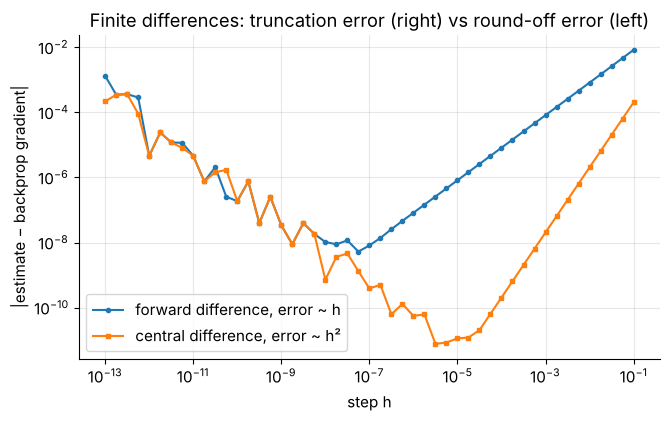

 forward difference: best h = 6e-08, smallest error = 5.3e-09
 central difference: best h = 3e-06, smallest error = 7.7e-12


In [37]:
r_h = np.random.default_rng(0)
net_h = make_mlp([2, 4, 3], r_h, act=Tanh)
X_h, y_h = r_h.normal(size=(8, 2)), r_h.integers(0, 3, size=8)
ce_h = SoftmaxCrossEntropy()
ce_h.forward(net_h.forward(X_h), y_h)
net_h.backward(ce_h.backward())
W_h = net_h.layers[0].W
exact_h = W_h.grad[0, 1]                               # the backprop value of dL/dW[0, 1]


def loss_shifted(delta):
    """Loss after adding delta to the single weight W[0, 1] (the weight is restored afterwards)."""
    old = W_h.value[0, 1]
    W_h.value[0, 1] = old + delta
    value = ce_h.forward(net_h.forward(X_h), y_h)
    W_h.value[0, 1] = old
    return value


hs = np.logspace(-13, -1, 49)
f0 = loss_shifted(0.0)
err_fwd = np.array([abs((loss_shifted(h) - f0) / h - exact_h) for h in hs])
err_ctr = np.array([abs((loss_shifted(h) - loss_shifted(-h)) / (2 * h) - exact_h) for h in hs])
err_fwd, err_ctr = np.maximum(err_fwd, 1e-17), np.maximum(err_ctr, 1e-17)   # exact zeros cannot be drawn on a log axis

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.loglog(hs, err_fwd, "o-", ms=3, label="forward difference, error ~ h")
ax.loglog(hs, err_ctr, "s-", ms=3, label="central difference, error ~ h²")
ax.set(xlabel="step h", ylabel="|estimate − backprop gradient|",
       title="Finite differences: truncation error (right) vs round-off error (left)")
ax.legend()
plt.show()
for name, err in [("forward", err_fwd), ("central", err_ctr)]:
    print(f"{name:>8} difference: best h = {hs[np.argmin(err)]:.0e}, smallest error = {err.min():.1e}")

Both curves are V-shaped: to the right of the minimum the Taylor truncation error dominates (slope 1 for the forward difference, slope 2 for the central one), and to the left the round-off error $\propto 1/h$ takes over. The central difference is far more accurate at its best $h$, which is why gradient checks use it with $h \approx 10^{-5}$ to $10^{-6}$.

**How to compare two gradients.** An absolute difference of $10^{-6}$ is excellent if the gradient is around $1$ and terrible if it is around $10^{-6}$. So we use the **relative error**

$$
\text{rel}(\mathbf{g}_{\text{bp}}, \mathbf{g}_{\text{fd}}) = \frac{\lVert \mathbf{g}_{\text{bp}} - \mathbf{g}_{\text{fd}} \rVert}{\lVert \mathbf{g}_{\text{bp}} \rVert + \lVert \mathbf{g}_{\text{fd}} \rVert} \in [0, 1].
$$

Rules of thumb in float64 with $h = 10^{-5}$: below $10^{-7}$ the gradient is correct, between $10^{-7}$ and $10^{-4}$ be suspicious (unless the network has kinks, see below), and above $10^{-4}$ there is almost certainly a bug.

The checker below perturbs every entry of every parameter, one at a time. That is $2P$ forward passes, fine for a tiny network and exactly why we use it only for *testing*, never for training.

In [38]:
def relative_error(a, b):
    """||a - b|| / (||a|| + ||b||), defined as 0 when both are zero."""
    denom = np.linalg.norm(a) + np.linalg.norm(b)
    return 0.0 if denom == 0 else float(np.linalg.norm(a - b) / denom)


def param_labels(model):
    """Readable names such as 'W[1] (2, 5)' for every parameter of a Sequential model."""
    labels, k = [], 0
    for layer in model.layers:
        if layer.parameters():
            k += 1
            labels += [f"{p.name}[{k}] {p.value.shape}" for p in layer.parameters()]
    return labels


def grad_check(model, loss_fn, X, y, h=1e-5):
    """Relative error between backprop and central differences, for every parameter array."""
    loss_fn.forward(model.forward(X), y)
    model.backward(loss_fn.backward())
    analytic = [p.grad.copy() for p in model.parameters()]
    errors = []
    for p, g in zip(model.parameters(), analytic):
        numeric = np.zeros_like(p.value)
        for idx in np.ndindex(p.value.shape):
            old = p.value[idx]
            p.value[idx] = old + h
            up = loss_fn.forward(model.forward(X), y)
            p.value[idx] = old - h
            down = loss_fn.forward(model.forward(X), y)
            p.value[idx] = old                         # always restore the parameter
            numeric[idx] = (up - down) / (2 * h)
        errors.append(relative_error(g, numeric))
    return pd.Series(errors, index=param_labels(model), name="relative error")

Now check a correct network, and two networks with a planted bug of the "shapes are fine" kind:

- `BiasMeanLinear` averages its bias gradient over the batch instead of summing it. Because the loss gradient already contains $\frac1m$, this divides by $m$ twice (pitfall 3 of Section 4.5).
- `ForgetfulTanh` uses $1 - a$ instead of $1 - a^2$ as the derivative of tanh.

In [39]:
class BiasMeanLinear(Linear):
    def backward(self, grad_out):
        grad_in = super().backward(grad_out)
        self.b.grad = grad_out.mean(axis=0, keepdims=True)    # BUG: should be a sum
        return grad_in


class ForgetfulTanh(Tanh):
    def backward(self, grad_out):
        return grad_out * (1.0 - self.out)                     # BUG: should be 1 - out**2


def small_net(linear_cls=Linear, act_cls=Tanh, seed=3):
    r = np.random.default_rng(seed)
    return Sequential(linear_cls(3, 5, r), act_cls(), linear_cls(5, 4, r), act_cls(), linear_cls(4, 3, r))


r_gc = np.random.default_rng(4)
X_gc, y_gc = r_gc.normal(size=(6, 3)), r_gc.integers(0, 3, size=6)
checks = pd.DataFrame({
    "correct": grad_check(small_net(), SoftmaxCrossEntropy(), X_gc, y_gc),
    "bias-mean bug": grad_check(small_net(linear_cls=BiasMeanLinear), SoftmaxCrossEntropy(), X_gc, y_gc),
    "tanh-derivative bug": grad_check(small_net(act_cls=ForgetfulTanh), SoftmaxCrossEntropy(), X_gc, y_gc),
})
display(checks.map(lambda v: f"{v:.1e}"))

,correct,bias-mean bug,tanh-derivative bug
"W[1] (3, 5)",6.0e-11,6.0e-11,7.1e-01
"b[1] (1, 5)",6.8e-11,7.1e-01,4.7e-01
"W[2] (5, 4)",2.6e-11,2.6e-11,2.2e-01
"b[2] (1, 4)",3.2e-11,7.1e-01,3.2e-01
"W[3] (4, 3)",4.5e-11,4.5e-11,4.5e-11
"b[3] (1, 3)",2.4e-11,7.1e-01,2.4e-11


The correct network passes with relative errors around $10^{-10}$ or smaller. The bias bug shows up only in the bias rows, with an error of order 1: the computed gradient is $m = 6$ times too small, and a vector compared with one six times longer in the same direction has relative error $(6 - 1)/(6 + 1) \approx 0.71$. The tanh bug corrupts every parameter *below* the faulty activation (the last layer's gradients are still right, because the error enters the backward pass only after them). Reading *which* rows fail tells you where the bug lives.

> **Common pitfall.** Gradient checks on ReLU networks can fail spuriously: if some pre-activation $z$ lies within $h$ of the kink at $0$, the two evaluations $f(\theta \pm h)$ straddle the kink and the finite difference is meaningless. Use smooth activations (or check that no $|z|$ is tiny) when testing, use float64, switch dropout off, and use a few examples so that the check runs fast.

### 5.4 The final exam: identical results to PyTorch

PyTorch computes gradients with autograd, which knows nothing about our formulas. If we give a PyTorch network **exactly the same weights**, both libraries must produce the same loss and the same gradients. Remember the transpose: `nn.Linear` stores `weight` with shape `(out_features, in_features)`, which is our $W^\top$.

In [40]:
r_cmp = np.random.default_rng(11)
ours = make_mlp([4, 16, 16, 3], r_cmp, act=Tanh)
X_cmp, y_cmp = r_cmp.normal(size=(10, 4)), r_cmp.integers(0, 3, size=10)
ce_cmp = SoftmaxCrossEntropy()
loss_ours = ce_cmp.forward(ours.forward(X_cmp), y_cmp)
ours.backward(ce_cmp.backward())

theirs = nn.Sequential(nn.Linear(4, 16), nn.Tanh(), nn.Linear(16, 16), nn.Tanh(), nn.Linear(16, 3)).double()
our_linears = [layer for layer in ours.layers if isinstance(layer, Linear)]
torch_linears = [layer for layer in theirs if isinstance(layer, nn.Linear)]
with torch.no_grad():                                  # copying weights is not part of the computation graph
    for mine, tl in zip(our_linears, torch_linears):
        tl.weight.copy_(torch.from_numpy(mine.W.value.T))     # PyTorch stores W transposed
        tl.bias.copy_(torch.from_numpy(mine.b.value.ravel()))
loss_theirs = nn.functional.cross_entropy(theirs(torch.from_numpy(X_cmp)), torch.from_numpy(y_cmp))
loss_theirs.backward()

print(f"loss  ours: {loss_ours:.12f}   PyTorch: {loss_theirs.item():.12f}")
display(pd.DataFrame([{"layer": k,
                       "max |dW ours - dW PyTorch|": np.abs(mine.W.grad - tl.weight.grad.numpy().T).max(),
                       "max |db ours - db PyTorch|": np.abs(mine.b.grad.ravel() - tl.bias.grad.numpy()).max()}
                      for k, (mine, tl) in enumerate(zip(our_linears, torch_linears), start=1)]))

loss  ours: 1.080107962722   PyTorch: 1.080107962722


,layer,max |dW ours - dW PyTorch|,max |db ours - db PyTorch|
0,1,4.1633e-17,8.3267e-17
1,2,4.1633e-17,7.6328e-17
2,3,4.1633e-17,6.2450e-17


Identical to about $10^{-16}$, the precision of float64. From now on we can trust our library, and we know precisely what PyTorch's `loss.backward()` computes: the same chain of Rule 1 and Rule 2 steps that we wrote by hand.

**Quick check.** In `Linear.backward`, why must `self.x` be the input of the **same** forward pass, and what goes wrong if you call `forward` on a validation batch between a training batch's `forward` and its `backward`?

<details>
<summary>Answer</summary>

$\nabla W = A^\top\bar Z$ pairs each example's input with that example's error signal. The cache is overwritten by every `forward` call, so a validation forward in between replaces `self.x` (and the ReLU masks) with validation data: the shapes may even still match, and the gradient would silently combine validation inputs with training errors. Always run `forward` → loss → `backward` for a batch without interruption (PyTorch avoids this class of bug by storing the cache inside the graph of each forward call).
</details>

### ✏️ Exercise 7: a softplus layer

Add a `SoftplusLayer` module to the library. `forward` must compute $\operatorname{softplus}(x) = \log(1 + e^{x})$ without overflow (reuse the stable `softplus` function from Section 3.2) and cache what `backward` needs. `backward(grad_out)` must return $\partial\mathcal{L}/\partial x$ using $\operatorname{softplus}'(x) = \sigma(x)$. The checker compares with PyTorch and runs a gradient check of a network that uses your layer.

In [41]:
# ✏️ Exercise 7: a SoftplusLayer module
class SoftplusLayer(Module):
    """Elementwise softplus with a backward pass."""

    def forward(self, x):
        # YOUR CODE HERE
        raise NotImplementedError

    def backward(self, grad_out):
        # YOUR CODE HERE
        raise NotImplementedError


def _test():
    layer = SoftplusLayer()
    x = np.array([[-800.0, -2.0, 0.0], [1.5, 30.0, 800.0]])
    out = layer.forward(x)
    assert np.all(np.isfinite(out)), "forward overflowed: use the stable softplus"
    xt = torch.tensor(x, requires_grad=True)
    ref = nn.functional.softplus(xt)
    assert np.allclose(out, ref.detach().numpy()), "forward values are wrong"
    upstream = np.random.default_rng(0).normal(size=x.shape)
    ref.backward(torch.tensor(upstream))
    assert np.allclose(layer.backward(upstream), xt.grad.numpy()), "backward is wrong"
    r = np.random.default_rng(1)
    net = Sequential(Linear(3, 4, r), SoftplusLayer(), Linear(4, 2, r))
    errs = grad_check(net, SoftmaxCrossEntropy(), r.normal(size=(5, 3)), r.integers(0, 2, size=5))
    assert errs.max() < 1e-6, f"gradient check failed inside a network: {errs.round(8).to_dict()}"


run_check("Exercise 7", _test)

⏳ Exercise 7: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
class SoftplusLayer(Module):
    def forward(self, x):
        self.x = x                          # cache the input: the derivative sigma(x) needs it
        return softplus(x)

    def backward(self, grad_out):
        return grad_out * sigmoid(self.x)   # Rule 1 with g'(x) = sigma(x)
```
Unlike `Tanh`, here the cheapest derivative formula uses the *input*, so the layer caches `x`. Both `softplus` and `sigmoid` were written to avoid overflow, so $x = \pm 800$ is harmless.
</details>

### ✏️ Exercise 8: your own gradient checker

Write `numerical_gradient(f, x, h)` that returns the central-difference estimate of the gradient of a scalar function `f` at the float array `x` (any shape). Perturb one entry at a time **in place**, and restore every entry **exactly** afterwards (save the old value). Also write `rel_error(a, b)` $= \lVert a - b\rVert / (\lVert a\rVert + \lVert b\rVert)$, returning `0.0` when both are zero.

In [42]:
# ✏️ Exercise 8: central differences and relative error
def numerical_gradient(f, x, h=1e-5):
    """Central-difference gradient of the scalar function f at x (modified in place, then restored)."""
    # YOUR CODE HERE
    raise NotImplementedError


def rel_error(a, b):
    """||a - b|| / (||a|| + ||b||), or 0.0 if both a and b are zero."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    x = np.array([[1.0, -2.0], [0.5, 3.0]])
    x_before = x.copy()
    g = numerical_gradient(lambda v: np.sum(v ** 3) + v[0, 1] * v[1, 0], x)
    expected = 3 * x_before ** 2 + np.array([[0.0, 0.5], [-2.0, 0.0]])
    assert np.shape(g) == x.shape, f"gradient must have shape {x.shape}"
    assert np.allclose(g, expected, atol=1e-6), f"expected {expected.tolist()}, got {np.round(g, 6).tolist()}"
    assert np.array_equal(x, x_before), "x must be restored exactly (save the old value and put it back)"
    assert np.isclose(rel_error(np.array([1.0, 2.0]), np.array([1.0, 2.0])), 0.0)
    assert np.isclose(rel_error(np.array([3.0, 0.0]), np.array([0.0, 4.0])), 5.0 / 7.0), "check the formula"
    assert rel_error(np.zeros(3), np.zeros(3)) == 0.0, "two zero vectors should give 0.0"
    r = np.random.default_rng(2)
    net = small_net()
    Xn, yn = r.normal(size=(4, 3)), r.integers(0, 3, size=4)
    loss_fn = SoftmaxCrossEntropy()
    loss_fn.forward(net.forward(Xn), yn)
    net.backward(loss_fn.backward())
    W = net.layers[0].W
    g_bp = W.grad.copy()
    g_fd = numerical_gradient(lambda _: loss_fn.forward(net.forward(Xn), yn), W.value)
    assert rel_error(g_bp, g_fd) < 1e-7, ("your checker disagrees with backprop on a correct network "
                                          "(perturb x in place: the network reads W.value directly, "
                                          "so changing a copy has no effect)")


run_check("Exercise 8", _test)

⏳ Exercise 8: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def numerical_gradient(f, x, h=1e-5):
    grad = np.zeros_like(x)
    for idx in np.ndindex(x.shape):
        old = x[idx]
        x[idx] = old + h
        f_plus = f(x)
        x[idx] = old - h
        f_minus = f(x)
        x[idx] = old                        # exact restore, no accumulated round-off
        grad[idx] = (f_plus - f_minus) / (2 * h)
    return grad

def rel_error(a, b):
    denom = np.linalg.norm(a) + np.linalg.norm(b)
    return 0.0 if denom == 0 else float(np.linalg.norm(a - b) / denom)
```
Restoring with `x[idx] += h` and `x[idx] -= h` would leave tiny round-off changes in `x`. Saving `old` avoids that. In the last test the lambda ignores its argument, because the network reads its weights directly from `W.value`, the array that `numerical_gradient` perturbs in place.
</details>

## 6. Training MLPs on nonlinear data

### 6.1 Mini-batches, epochs and shuffling

The training loss is an average over all $n$ training examples, $\mathcal{L}(\boldsymbol\theta) = \frac1n\sum_{i=1}^{n}\ell_i(\boldsymbol\theta)$, so its exact gradient costs a forward and backward pass over the *whole* training set. **Mini-batch stochastic gradient descent** instead estimates the gradient from a small random subset $\mathcal{B}$ of $B$ examples (the **batch size**):

$$
\mathbf{g}_{\mathcal{B}} = \frac{1}{B}\sum_{i \in \mathcal{B}} \nabla_{\boldsymbol\theta}\,\ell_i(\boldsymbol\theta), \qquad \boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\,\mathbf{g}_{\mathcal{B}} .
$$

If the batch is a uniformly random subset, every example is equally likely to be in it, so $\mathbb{E}[\mathbf{g}_{\mathcal{B}}] = \nabla\mathcal{L}$: the mini-batch gradient is an **unbiased** but **noisy** estimate of the true gradient, and the noise (its variance) shrinks like $1/B$. A batch of 32 examples gives a usable direction at a tiny fraction of the cost of the full gradient, so we can take many more steps for the same amount of computation.

Vocabulary you will see in every training log:

- a **step** (or **iteration**) is one parameter update, computed from one mini-batch.
- an **epoch** is one full pass over the training set, i.e. $\lceil n/B \rceil$ steps (the last batch may be smaller).
- **shuffling**: at the start of every epoch the training set is put in a new random order and then cut into consecutive batches. Every example is used exactly once per epoch, and every batch is a random mix of examples.

Here is the simplest optimizer (Section 8 adds momentum and Adam) and the training loop we will use for the rest of the notebook. Each step is the same three-beat rhythm you will write in PyTorch: **forward, backward, update**.

In [43]:
class SGD:
    """Plain stochastic gradient descent: theta <- theta - lr * grad (in place)."""

    def __init__(self, params, lr=0.1):
        self.params, self.lr = list(params), lr

    def step(self):
        for p in self.params:
            p.value -= self.lr * p.grad              # in place: the layers see the new values


def accuracy(model, X, y):
    """Fraction of examples whose highest logit is the true class."""
    return float(np.mean(model.forward(X).argmax(axis=1) == y))


def fit(model, loss_fn, opt, X, y, *, epochs, batch_size, rng, X_val=None, y_val=None,
        shuffle=True, classify=True, record_steps=False):
    """Mini-batch training loop. Returns a dict of per-epoch metrics (and per-step losses on request)."""
    history = {"loss": [], "acc": [], "val_loss": [], "val_acc": [], "step_loss": []}
    n = len(X)
    for epoch in range(epochs):
        model.train()
        order = rng.permutation(n) if shuffle else np.arange(n)
        running = 0.0
        for start in range(0, n, batch_size):
            idx = order[start:start + batch_size]                     # one mini-batch of indices
            loss = loss_fn.forward(model.forward(X[idx]), y[idx])     # 1. forward
            model.backward(loss_fn.backward())                        # 2. backward
            opt.step()                                                # 3. update
            running += loss * len(idx)
            if record_steps:
                history["step_loss"].append(loss)
        history["loss"].append(running / n)          # average loss *during* the epoch (a cheap proxy)
        model.eval()
        if classify:
            history["acc"].append(accuracy(model, X, y))
        if X_val is not None:
            history["val_loss"].append(loss_fn.forward(model.forward(X_val), y_val))
            if classify:
                history["val_acc"].append(accuracy(model, X_val, y_val))
    return history

Two details of `fit` matter later. The recorded training loss is the average of the mini-batch losses *during* the epoch, while the weights were still changing. It is free to compute but slightly pessimistic. And the model is switched to `eval()` mode for measurements, which will matter once dropout appears (Section 10).

### 6.2 Four nonlinear datasets

We generate four classic 2D problems in code, so that we can draw everything the network does:

- **XOR**: points in the square $[-1, 1]^2$, labeled 1 when $x_1$ and $x_2$ have opposite signs (the continuous version of the four-point XOR of Section 1.4).
- **circles**: a noisy ring of radius 1 around a noisy ring of radius 0.5.
- **two moons**: two interleaving half-circles.
- **spiral**: three arms winding around the origin, one per class: a genuinely hard 3-class problem for any linear model.

For each problem we also draw a separate **validation set** from the same generator with a different seed. It plays the role of new, unseen data.

In [44]:
def make_xor(n, rng, noise=0.05):
    """Uniform points in [-1, 1]^2, with class 1 when x1 and x2 have opposite signs (then a little noise)."""
    X = rng.uniform(-1, 1, size=(n, 2))
    y = ((X[:, 0] > 0) ^ (X[:, 1] > 0)).astype(int)
    return X + noise * rng.normal(size=X.shape), y


def make_circles(n, rng, noise=0.08, inner_radius=0.5):
    """Outer ring of radius 1 (class 0) around an inner ring of radius inner_radius (class 1)."""
    y = rng.permutation((np.arange(n) >= n // 2).astype(int))
    radius = np.where(y == 0, 1.0, inner_radius)
    angle = rng.uniform(0, 2 * np.pi, size=n)
    return np.c_[radius * np.cos(angle), radius * np.sin(angle)] + noise * rng.normal(size=(n, 2)), y


def make_moons(n, rng, noise=0.15):
    """Two interleaving half-circles: upper arc (class 0) and a shifted lower arc (class 1)."""
    y = rng.permutation((np.arange(n) >= n // 2).astype(int))
    t = rng.uniform(0, np.pi, size=n)
    upper = np.c_[np.cos(t), np.sin(t)]
    lower = np.c_[1.0 - np.cos(t), 0.5 - np.sin(t)]
    return np.where(y[:, None] == 0, upper, lower) + noise * rng.normal(size=(n, 2)), y


def make_spiral(n_per_class, rng, n_classes=3, turns=1.25, noise=0.2):
    """n_classes spiral arms, where the angle grows with the radius, plus angular noise."""
    Xs, ys = [], []
    for k in range(n_classes):
        r = np.sqrt(rng.uniform(0.01, 1.0, size=n_per_class))       # sqrt: spread points evenly in area
        theta = 2 * np.pi * (k / n_classes + turns * r) + noise * rng.normal(size=n_per_class)
        Xs.append(np.c_[r * np.cos(theta), r * np.sin(theta)])
        ys.append(np.full(n_per_class, k))
    X, y = np.vstack(Xs), np.concatenate(ys)
    order = rng.permutation(len(y))
    return X[order], y[order]


datasets = {
    "XOR": (make_xor(400, np.random.default_rng(1)), make_xor(1000, np.random.default_rng(11))),
    "circles": (make_circles(400, np.random.default_rng(2)), make_circles(1000, np.random.default_rng(12))),
    "moons": (make_moons(400, np.random.default_rng(3)), make_moons(1000, np.random.default_rng(13))),
    "spiral": (make_spiral(200, np.random.default_rng(4)), make_spiral(300, np.random.default_rng(14))),
}

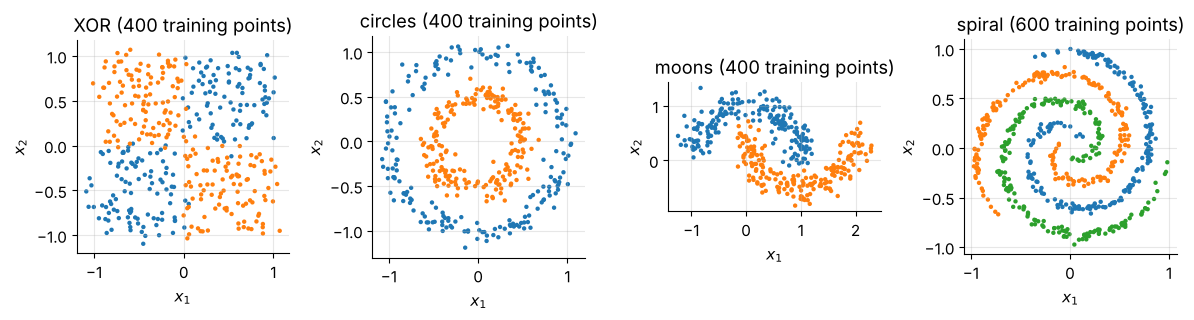

,dataset,classes,train size,validation size,logistic regression val. accuracy
0,XOR,2,400,1000,0.656
1,circles,2,400,1000,0.486
2,moons,2,400,1000,0.864
3,spiral,3,600,900,0.490


In [45]:
def plot_points(ax, X, y, s=10):
    for k in np.unique(y):
        ax.scatter(X[y == k, 0], X[y == k, 1], s=s, color=CLASS_COLORS[k], label=f"class {k}", edgecolors="none")


fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
rows = []
for ax, (name, ((X_tr, y_tr), (X_va, y_va))) in zip(axes, datasets.items()):
    plot_points(ax, X_tr, y_tr)
    ax.set(title=f"{name} ({len(y_tr)} training points)", xlabel="$x_1$", ylabel="$x_2$")
    ax.set_aspect("equal")
    logreg = LogisticRegression().fit(X_tr, y_tr)            # the best *linear* classifier, for reference
    rows.append({"dataset": name, "classes": len(np.unique(y_tr)), "train size": len(y_tr), "validation size": len(y_va),
                 "logistic regression val. accuracy": logreg.score(X_va, y_va)})
fig.tight_layout()
plt.show()
display(pd.DataFrame(rows).round(3))

A linear classifier fails on three of the four problems: on circles it is at chance level (about $0.49$), on the spiral it gets only about half of the points right (chance is $\tfrac13$), and on XOR the best it can do is cut off a corner of the square ($0.66$). Only on the moons, which are *almost* linearly separable, does it do reasonably well ($0.86$).

### 6.3 Training an MLP on each problem

We now train the same architecture on all four problems: $2 \to 32 \to 32 \to K$ with ReLU hidden layers ($K$ = number of classes), He initialization, plain SGD with learning rate $0.3$, batches of 32 and 200 epochs. To see what a classifier does, we color every point of a fine grid by the class it predicts: the borders between colored regions are the **decision boundaries**.

In [46]:
def plot_decision_boundary(ax, model, X, y, title="", resolution=200, margin=0.3):
    """Color the plane by the predicted class and overlay the data points."""
    x_min, y_min = X.min(axis=0) - margin
    x_max, y_max = X.max(axis=0) + margin
    G1, G2 = np.meshgrid(np.linspace(x_min, x_max, resolution), np.linspace(y_min, y_max, resolution))
    model.eval()
    pred = model.forward(np.c_[G1.ravel(), G2.ravel()]).argmax(axis=1).reshape(G1.shape)
    K = int(max(y.max(), pred.max())) + 1
    ax.contourf(G1, G2, pred, levels=np.arange(K + 1) - 0.5, colors=CLASS_COLORS[:K], alpha=0.25)
    plot_points(ax, X, y, s=8)
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", xlim=(x_min, x_max), ylim=(y_min, y_max))
    ax.set_aspect("equal")


trained, histories, rows = {}, {}, []
t_start = time.perf_counter()
for name, ((X_tr, y_tr), (X_va, y_va)) in datasets.items():
    r = np.random.default_rng(SEED)
    model = make_mlp([2, 32, 32, int(y_tr.max()) + 1], r)
    hist = fit(model, SoftmaxCrossEntropy(), SGD(model.parameters(), lr=0.3), X_tr, y_tr,
               epochs=200, batch_size=32, rng=r, X_val=X_va, y_val=y_va)
    trained[name], histories[name] = model, hist
    rows.append({"dataset": name, "final train loss": hist["loss"][-1], "train accuracy": hist["acc"][-1],
                 "validation accuracy": hist["val_acc"][-1]})
print(f"trained 4 networks in {time.perf_counter() - t_start:.1f} s")
display(pd.DataFrame(rows).round(4))

trained 4 networks in 1.5 s


,dataset,final train loss,train accuracy,validation accuracy
0,XOR,0.0721,0.9675,0.953
1,circles,0.0008,1.0000,1.000
2,moons,0.0023,1.0000,0.984
3,spiral,0.0021,1.0000,1.000


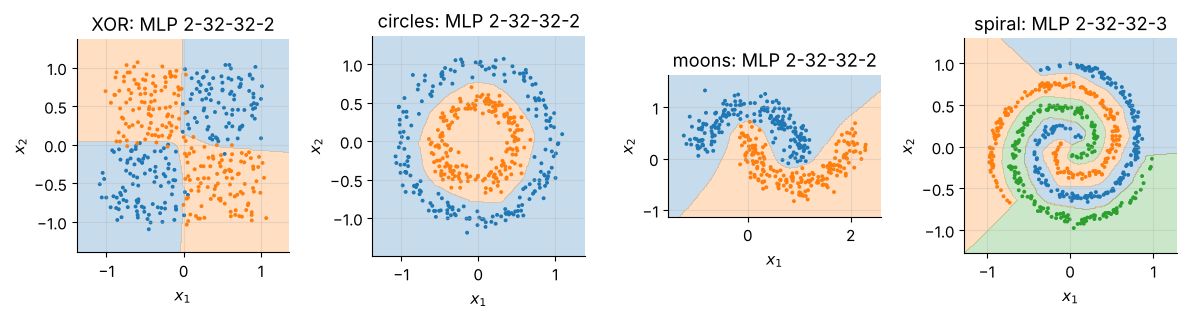

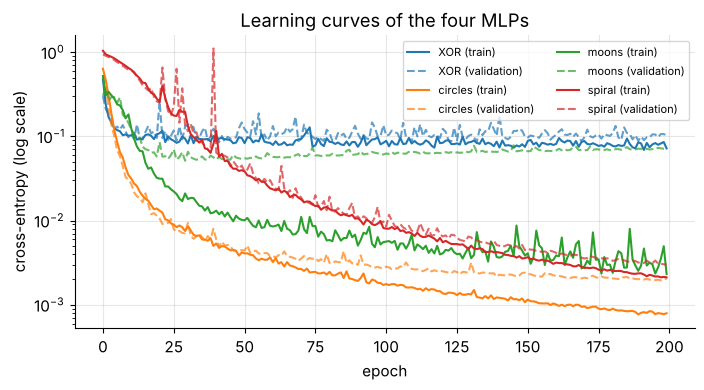

In [47]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, (name, ((X_tr, y_tr), _)) in zip(axes, datasets.items()):
    plot_decision_boundary(ax, trained[name], X_tr, y_tr, title=f"{name}: MLP 2-32-32-{int(y_tr.max()) + 1}")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.8))
for name, hist in histories.items():
    ax.plot(hist["loss"], label=f"{name} (train)")
    ax.plot(hist["val_loss"], ls="--", color=ax.lines[-1].get_color(), alpha=0.7, label=f"{name} (validation)")
ax.set_yscale("log")
ax.set(xlabel="epoch", ylabel="cross-entropy (log scale)", title="Learning curves of the four MLPs")
ax.legend(ncol=2, fontsize=8)
plt.show()

The same small network, trained in a few seconds with the same settings, solves all four problems: training accuracy 1.0 on circles, moons and spiral, and validation accuracy between $0.95$ and $1.0$. The boundaries bend wherever the data require it. XOR keeps a small loss on both sets because the added noise pushes some points across the axes, where no classifier can be right about them.

The learning curves tell the same story with more detail. Training losses fall steadily (note the log scale). Validation losses follow them at first and then level off, most visibly on moons and XOR: from there on the network is polishing its fit to the particular training points rather than learning anything that transfers. Section 10 deals with that gap. The occasional spikes are single SGD steps that overshoot. A learning rate of $0.3$ is on the bold side.

### 6.4 Looking inside: hidden units are half-planes

What exactly did the network build? With a *single* hidden layer the answer can be drawn. Hidden unit $j$ computes $\operatorname{ReLU}(\mathbf{w}_j^\top\mathbf{x} + b_j)$: it is exactly $0$ on one side of the line $\mathbf{w}_j^\top\mathbf{x} + b_j = 0$ and grows linearly with the distance to the line on the other side, a **ramp**. The output layer adds up these ramps with weights, so the difference of the two logits,

$$
z_1 - z_0 = \sum_{j=1}^{H} v_j\,\operatorname{ReLU}(\mathbf{w}_j^\top\mathbf{x} + b_j) + c ,
$$

is a **piecewise linear** surface whose creases lie on the $H$ lines. The decision boundary, where $z_1 - z_0 = 0$, is therefore made of straight segments: a polygon. Let us train a $2 \to 8 \to 2$ network on the circles and draw its 8 lines.

2-8-2 ReLU network on circles: train accuracy 1.000, validation accuracy 1.000


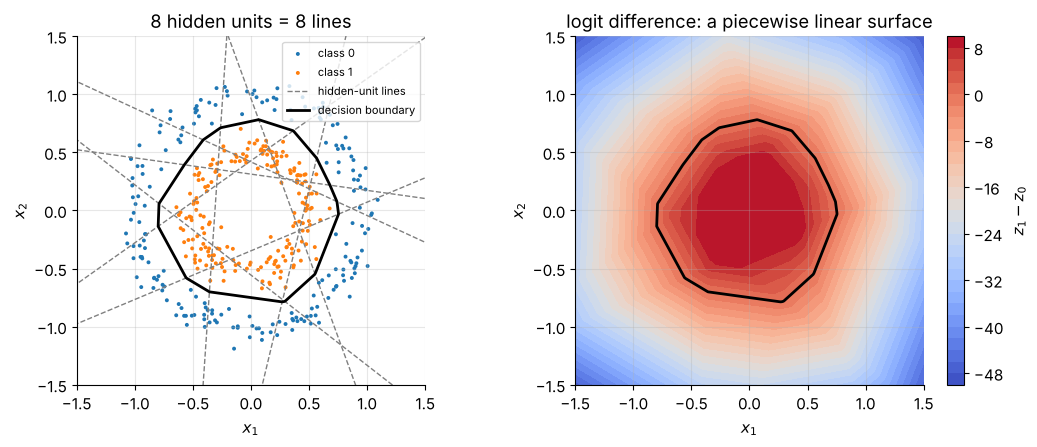

In [48]:
(X_c, y_c), (X_cv, y_cv) = datasets["circles"]
r = np.random.default_rng(SEED)
shallow = make_mlp([2, 8, 2], r)
hist_sh = fit(shallow, SoftmaxCrossEntropy(), SGD(shallow.parameters(), lr=0.3), X_c, y_c,
              epochs=300, batch_size=32, rng=r, X_val=X_cv, y_val=y_cv)
print(f"2-8-2 ReLU network on circles: train accuracy {hist_sh['acc'][-1]:.3f}, "
      f"validation accuracy {hist_sh['val_acc'][-1]:.3f}")

W_sh, b_sh = shallow.layers[0].W.value, shallow.layers[0].b.value.ravel()
G1, G2 = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-1.5, 1.5, 300))
logits_grid = shallow.forward(np.c_[G1.ravel(), G2.ravel()])
margin_grid = (logits_grid[:, 1] - logits_grid[:, 0]).reshape(G1.shape)       # z_1 - z_0

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
plot_points(axes[0], X_c, y_c, s=8)
for j in range(W_sh.shape[1]):
    w = W_sh[:, j]
    p0 = -b_sh[j] * w / (w @ w)                         # the point of the line closest to the origin
    d = np.array([-w[1], w[0]]) / np.linalg.norm(w)     # direction along the line
    seg = p0 + np.outer(np.linspace(-4, 4, 2), d)
    axes[0].plot(seg[:, 0], seg[:, 1], color="gray", lw=1, ls="--", label="hidden-unit lines" if j == 0 else None)
axes[0].contour(G1, G2, margin_grid, levels=[0.0], colors="black", linewidths=2)
axes[0].plot([], [], color="black", lw=2, label="decision boundary")
axes[0].set(xlim=(-1.5, 1.5), ylim=(-1.5, 1.5), title="8 hidden units = 8 lines", xlabel="$x_1$", ylabel="$x_2$")
axes[0].set_aspect("equal")
axes[0].legend(fontsize=8, loc="upper right")
im = axes[1].contourf(G1, G2, margin_grid, levels=30, cmap="coolwarm")
axes[1].contour(G1, G2, margin_grid, levels=[0.0], colors="black", linewidths=2)
fig.colorbar(im, ax=axes[1], label="$z_1 - z_0$")
axes[1].set(title="logit difference: a piecewise linear surface", xlabel="$x_1$", ylabel="$x_2$")
axes[1].set_aspect("equal")
fig.tight_layout()
plt.show()

Every corner of the decision boundary (black) sits on one of the dashed lines, but its sides do not follow the lines. Inside each region cut out by the lines, every hidden unit is either on for all points or off for all points, so $z_1 - z_0$ is linear there and the boundary is a straight segment. It can bend only where it crosses a line, that is, where one hidden unit switches on or off. All 8 lines cut right through the inner ring: it is the black polygon, not the lines, that encloses it. Each line crosses the closed boundary twice, so 8 units give the polygon up to 16 corners. In the right panel you can see the "tent" the output layer builds: high (inner class) in the middle, sloping down in flat facets. A wider hidden layer provides more lines and therefore a rounder polygon. Deeper networks can fold and reuse these regions, as Section 9 shows.

> **Key idea.** A ReLU network computes a piecewise linear function of its input. Each hidden unit contributes one "crease". Training moves the creases (through $\mathbf{w}_j, b_j$) and sets the heights of the facets (through the output weights).

### 6.5 Experiments: change one knob at a time

**Shuffling.** What if we forget to shuffle and the training file happens to be sorted by class? Then every epoch shows the network 200 class-0 points, then 200 class-1 points, then 200 class-2 points, in batches that each contain a single class. Each batch pulls the model toward "everything is this class". We train two identical networks on the spiral, one with shuffling and one on the sorted file without shuffling, and record the loss of every single step.

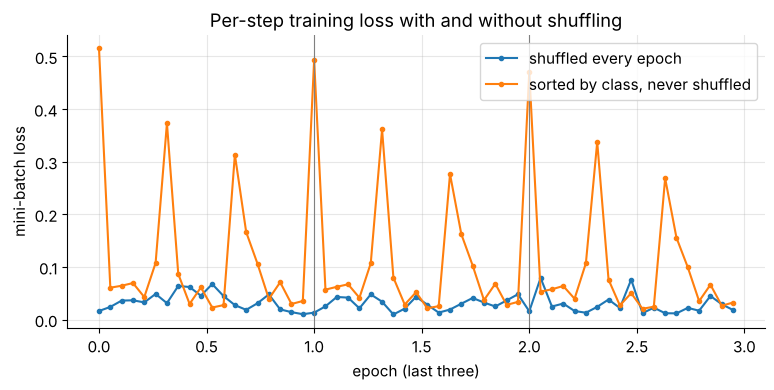

,shuffle,full training loss,validation accuracy,"share of val. predictions (class 0, 1, 2)"
0,True,0.0284,0.9911,"(0.324, 0.334, 0.341)"
1,False,0.2638,0.8967,"(0.291, 0.278, 0.431)"


In [49]:
(X_sp, y_sp), (X_spv, y_spv) = datasets["spiral"]
order_by_class = np.argsort(y_sp, kind="stable")
X_sorted, y_sorted = X_sp[order_by_class], y_sp[order_by_class]
steps_per_epoch = int(np.ceil(len(y_sp) / 32))

fig, ax = plt.subplots(figsize=(9, 3.8))
rows = []
for shuffle in [True, False]:
    r = np.random.default_rng(SEED)
    model = make_mlp([2, 32, 32, 3], r)
    hist = fit(model, SoftmaxCrossEntropy(), SGD(model.parameters(), lr=0.3), X_sorted, y_sorted, epochs=60,
               batch_size=32, rng=r, X_val=X_spv, y_val=y_spv, shuffle=shuffle, record_steps=True)
    last = hist["step_loss"][-3 * steps_per_epoch:]                       # the last three epochs
    ax.plot(np.arange(len(last)) / steps_per_epoch, last, "o-", ms=3,
            label="shuffled every epoch" if shuffle else "sorted by class, never shuffled")
    share = np.bincount(model.forward(X_spv).argmax(axis=1), minlength=3) / len(y_spv)
    rows.append({"shuffle": shuffle, "full training loss": SoftmaxCrossEntropy().forward(model.forward(X_sp), y_sp),
                 "validation accuracy": hist["val_acc"][-1],
                 "share of val. predictions (class 0, 1, 2)": tuple(np.round(share, 3))})
for k in range(1, 3):
    ax.axvline(k, color="gray", lw=0.8)
ax.set(xlabel="epoch (last three)", ylabel="mini-batch loss", title="Per-step training loss with and without shuffling")
ax.legend()
plt.show()
display(pd.DataFrame(rows).round(4))

With shuffling, the step losses are small and fluctuate randomly. Without it they follow a pattern that repeats every epoch: a spike at each class switch (the first batches of a new class arrive at a model that has just been pushed toward the previous class), then a decline. At the end of training the unshuffled model is biased toward the class it saw last (it predicts class 2 for about 43% of the validation points, where the truth is one third), and its validation accuracy is clearly lower. Shuffling costs nothing, so always do it (PyTorch: `DataLoader(..., shuffle=True)`).

**Batch size.** Next, we train with batch sizes 8, 32, 128 and 600 (the full training set, i.e. plain gradient descent) for the same 60 epochs and the same learning rate.

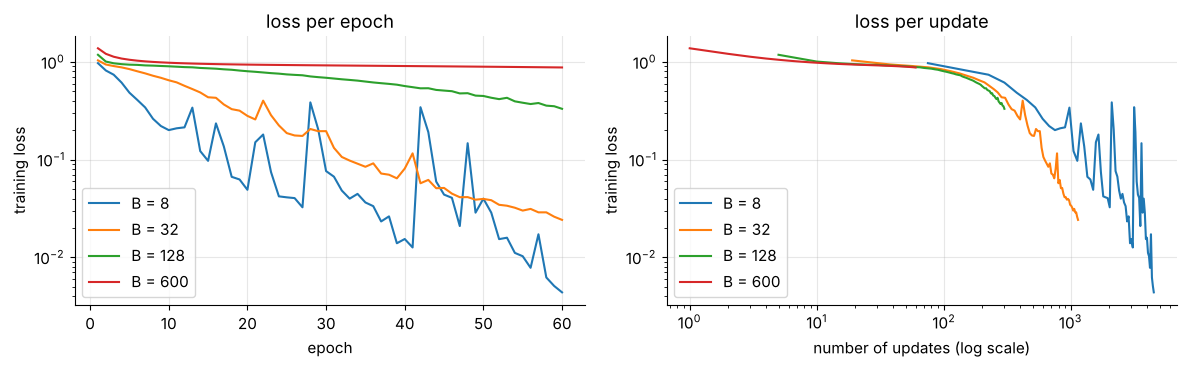

,batch size,steps per epoch,total steps,final train loss,validation accuracy,seconds
0,8,75,4500,0.0044,1.0000,0.3896
1,32,19,1140,0.0242,0.9933,0.1435
2,128,5,300,0.3317,0.8822,0.0897
3,600,1,60,0.8792,0.4878,0.0718


In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
rows = []
for bs in [8, 32, 128, 600]:
    r = np.random.default_rng(SEED)
    model = make_mlp([2, 32, 32, 3], r)
    t0 = time.perf_counter()
    hist = fit(model, SoftmaxCrossEntropy(), SGD(model.parameters(), lr=0.3), X_sp, y_sp, epochs=60,
               batch_size=bs, rng=r, X_val=X_spv, y_val=y_spv)
    seconds = time.perf_counter() - t0
    steps = int(np.ceil(len(y_sp) / bs))
    axes[0].plot(np.arange(1, 61), hist["loss"], label=f"B = {bs}")
    axes[1].plot(steps * np.arange(1, 61), hist["loss"], label=f"B = {bs}")
    rows.append({"batch size": bs, "steps per epoch": steps, "total steps": 60 * steps,
                 "final train loss": hist["loss"][-1], "validation accuracy": hist["val_acc"][-1], "seconds": seconds})
axes[0].set(xlabel="epoch", title="loss per epoch")
axes[1].set(xlabel="number of updates (log scale)", xscale="log", title="loss per update")
for ax in axes:
    ax.set(ylabel="training loss", yscale="log")
    ax.legend()
fig.tight_layout()
plt.show()
display(pd.DataFrame(rows).round(4))

Per **epoch** (left), small batches win by far: an epoch with $B = 8$ makes 75 updates, while full-batch gradient descent makes one, and after 60 epochs it has barely started. Per **update** (right), the order flips: a large batch gives a more accurate gradient, so each of its steps is worth more. But a step on 600 examples also costs about 75 times as much arithmetic as a step on 8. Small batches also pay in noise: the jagged $B = 8$ curve follows gradients estimated from only 8 points each. In practice the batch size is a compromise: big enough to use the hardware efficiently (GPUs process a batch of 64 almost as fast as a batch of 8), small enough to make many updates per epoch. Values between 16 and 512 are typical. Note also the wall-clock column: with tiny matrices, Python's per-step overhead dominates, so many small steps are slow. On a GPU with large models the balance shifts toward larger batches.

**Learning rate and dead ReLUs.** Finally, the learning rate. Besides the familiar "too small: slow, too large: unstable", ReLU networks have a specific failure: one large update can push a unit's pre-activation below zero for *every* input, and Section 3.4 showed that such a dead unit never receives gradient again. We count, for each hidden layer, the fraction of units that are inactive on all 600 training points, before and after 50 epochs.

In [51]:
def dead_fraction(model, X):
    """For each ReLU layer, the fraction of units that output 0 for every row of X."""
    model.eval()
    fractions, out = [], X
    for layer in model.layers:
        out = layer.forward(out)
        if isinstance(layer, ReLU):
            fractions.append(float(np.mean(~(out > 0).any(axis=0))))
    return fractions


rows = []
for lr in [0.03, 0.3, 1.0, 3.0]:
    r = np.random.default_rng(SEED)
    model = make_mlp([2, 32, 32, 3], r)
    dead_before = dead_fraction(model, X_sp)
    hist = fit(model, SoftmaxCrossEntropy(), SGD(model.parameters(), lr=lr), X_sp, y_sp, epochs=50, batch_size=32, rng=r)
    dead_after = dead_fraction(model, X_sp)
    rows.append({"learning rate": lr, "final train loss": hist["loss"][-1], "train accuracy": hist["acc"][-1],
                 "dead units, layer 1 (before -> after)": f"{dead_before[0]:.0%} -> {dead_after[0]:.0%}",
                 "dead units, layer 2 (before -> after)": f"{dead_before[1]:.0%} -> {dead_after[1]:.0%}"})
display(pd.DataFrame(rows).round(4))

,learning rate,final train loss,train accuracy,"dead units, layer 1 (before -> after)","dead units, layer 2 (before -> after)"
0,0.03,0.8091,0.5000,0% -> 0%,9% -> 16%
1,0.30,0.0397,0.9917,0% -> 0%,9% -> 9%
2,1.00,0.5228,0.6233,0% -> 59%,9% -> 22%
3,3.00,1.1321,0.3333,0% -> 62%,9% -> 100%


- $\eta = 0.03$ is slow: after 50 epochs the network is still far from a good fit. (Even here two more second-layer units die, and units can also drift slowly into the dead zone.)
- $\eta = 0.3$ trains well, and no additional units die.
- $\eta = 1.0$ kills more than half of the first-layer units and a fifth of the second layer. The survivors still learn something, but accuracy is poor.
- $\eta = 3.0$ kills *every* unit of the second layer. The output is then a constant (only the output bias can still learn), and accuracy drops to $\tfrac13$, i.e. guessing.

Even before training, 3 of the 32 second-layer units (9%) are dead on this data. Each of them has some positive incoming weights, so a suitable nonnegative input would switch it on. But all 32 first-layer outputs are computed from the same 2D point, so together they only trace out a two-dimensional sheet inside the 32-dimensional space, and on every training point the random weighted sum of these three units happens to stay below zero. This is common and harmless in moderation.

> **Common pitfall.** A training loss that suddenly stops improving and stays flat at the "constant prediction" level ($\log K$ for $K$ balanced classes, $\log 3 \approx 1.10$ here) is the signature of a network whose ReLUs have died. Lower the learning rate, use Leaky ReLU, or check the initialization.

**Quick check.** You train on $n = 1000$ examples with batch size 64 for 20 epochs. How many updates are made, and how large is the last batch of each epoch?

<details>
<summary>Answer</summary>

Each epoch has $\lceil 1000/64 \rceil = 16$ batches: 15 full batches of 64 ($960$ examples) and a last batch of $40$. Over 20 epochs that is $320$ updates. (PyTorch's `DataLoader` has a `drop_last=True` option that discards the smaller batch instead.)
</details>

### ✏️ Exercise 9: shuffled mini-batches

Write `minibatch_indices(n, batch_size, rng)` that returns a **list** of index arrays for one epoch: call `rng.permutation(n)` once, then cut the permutation into consecutive chunks of `batch_size` (the last chunk may be smaller, and there must be no empty chunk).

In [52]:
# ✏️ Exercise 9: the index bookkeeping of one epoch
def minibatch_indices(n, batch_size, rng):
    """List of index arrays covering a random permutation of range(n), in chunks of batch_size."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    batches = minibatch_indices(10, 4, np.random.default_rng(0))
    assert isinstance(batches, list), "return a list of index arrays"
    assert [len(b) for b in batches] == [4, 4, 2], f"batch sizes should be [4, 4, 2], got {[len(b) for b in batches]}"
    assert sorted(np.concatenate(batches).tolist()) == list(range(10)), "every example must appear exactly once"
    assert np.array_equal(np.concatenate(batches), np.random.default_rng(0).permutation(10)), \
        "call rng.permutation(n) once and slice it in order"
    rng_t = np.random.default_rng(1)
    epoch_a, epoch_b = minibatch_indices(100, 32, rng_t), minibatch_indices(100, 32, rng_t)
    assert not np.array_equal(np.concatenate(epoch_a), np.concatenate(epoch_b)), "two epochs should use different orders"
    assert len(minibatch_indices(64, 32, rng_t)) == 2, "no empty batch when n is a multiple of batch_size"


run_check("Exercise 9", _test)

⏳ Exercise 9: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def minibatch_indices(n, batch_size, rng):
    order = rng.permutation(n)
    return [order[start:start + batch_size] for start in range(0, n, batch_size)]
```
`range(0, n, batch_size)` produces the start of every chunk. Slicing past the end of an array simply returns the shorter remainder, so the last batch takes care of itself. This is exactly what the inner loop of `fit` does.
</details>

### 6.6 When training goes wrong: a debugging checklist

Neural networks fail quietly: a buggy network still produces numbers, and often its loss still goes down a little. Experienced practitioners run a few cheap sanity checks before any long training run.

1. **Check the loss at initialization.** With $K$ balanced classes and small random logits, the predicted distribution is nearly uniform and the loss is about $\log K$. A starting loss far above that points to badly scaled weights or broken labels.
2. **Overfit a tiny subset.** A healthy network must be able to drive the loss to almost zero on, say, 16 examples. If it cannot, something in the plumbing is broken (gradients, labels, the loss, the optimizer step) or the learning rate is far off.
3. **Gradient-check every new layer** (Section 5.3), on a small network in float64.
4. **Scale the inputs.** Standardize features to mean 0 and standard deviation 1 (using training-set statistics). Inputs in the thousands make the first layer's pre-activations huge, which saturates tanh/sigmoid units and destabilizes training.
5. **Watch the curves.** A loss stuck at $\log K$ suggests dead units or a learning rate that is too small, `nan` or `inf` suggests a learning rate that is too large or a missing log-sum-exp, and a growing gap between training and validation curves means overfitting (Section 10).

Here are checks 1 and 2 for our spiral network.

In [53]:
r = np.random.default_rng(SEED)
debug_net = make_mlp([2, 32, 32, 3], r)
loss_dbg = SoftmaxCrossEntropy()
print(f"loss at initialization: {loss_dbg.forward(debug_net.forward(X_sp), y_sp):.4f}   (log 3 = {np.log(3):.4f})")
hist_dbg = fit(debug_net, loss_dbg, SGD(debug_net.parameters(), lr=0.3), X_sp[:16], y_sp[:16],
               epochs=300, batch_size=16, rng=r)
print(f"after 300 full-batch steps on 16 examples: loss {hist_dbg['loss'][-1]:.5f}, accuracy {hist_dbg['acc'][-1]:.2f}")

loss at initialization: 1.3813   (log 3 = 1.0986)
after 300 full-batch steps on 16 examples: loss 0.01223, accuracy 1.00


The initial loss is in the right range (a little above $\log 3$, because He-initialized logits are not tiny), and the network memorizes the 16 examples. Note what this test does *not* show: a network with thousands of parameters can memorize 16 examples even with random labels, so passing it proves only that the machinery works, not that the model will generalize.

## 7. Initialization: breaking symmetry and keeping signals alive

Gradient descent needs a starting point. It seems like a minor detail, but a bad starting point can make a network untrainable before the first step is taken. Two separate things can go wrong: **symmetry** (all units learn the same thing) and **scale** (signals shrink to nothing or blow up as they pass through many layers).

### 7.1 Why not start from zero? The symmetry problem

Suppose every weight of the network starts with the same value, for example $0$ (and the biases at $0$, as usual). Then:

1. every hidden unit computes the same pre-activation $z_j = \mathbf{w}^\top\mathbf{x} + b$ for every input, hence the same activation.
2. in the backward pass, column $j$ of $\delta^{[1]} = (\delta^{[2]}W^{[2]\top}) \odot g'(Z^{[1]})$ depends on unit $j$ only through row $j$ of $W^{[2]}$ and column $j$ of $Z^{[1]}$, and these are the same for all units (every entry of $W^{[2]}$ is the same constant, so all its rows are identical), so all units receive **the same gradient**.
3. so after the update the units are still identical, and by induction they stay identical forever.

The layer then behaves like a single unit, however wide it is. With exact zeros it is even worse: $A^{[1]} = 0$ for tanh and ReLU, so $\nabla W^{[2]} = A^{[1]\top}\delta^{[2]} = 0$, and $\delta^{[1]} = \delta^{[2]}W^{[2]\top} = 0$, so the only parameters that ever move are the output biases. **Random** initial weights break the symmetry: units start different, receive different gradients and specialize. (Biases can start at zero, because the random weights already make the units different.)

Let us train the $2 \to 8 \to 2$ network on the circles from three starting points: all weights $0$, all weights $0.5$, and the random He initialization used so far.

In [54]:
def constant_init_net(value, act, seed=SEED):
    """A 2-8-2 network whose weights all start at the same value (value=None keeps the random He init)."""
    net = make_mlp([2, 8, 2], np.random.default_rng(seed), act=act)
    if value is not None:
        for layer in net.layers:
            if isinstance(layer, Linear):
                layer.W.value[:] = value
    return net


rows = []
for label, value in [("all zeros", 0.0), ("all 0.5", 0.5), ("random (He)", None)]:
    for act in [Tanh, ReLU]:
        r = np.random.default_rng(SEED)
        net = constant_init_net(value, act)
        hist = fit(net, SoftmaxCrossEntropy(), SGD(net.parameters(), lr=0.3), X_c, y_c, epochs=200, batch_size=32, rng=r)
        W1 = net.layers[0].W.value
        rows.append({"initial weights": label, "activation": act.__name__.rstrip("()"),
                     "train accuracy": hist["acc"][-1],
                     "largest difference between hidden units' weights": np.abs(W1 - W1[:, :1]).max()})
display(pd.DataFrame(rows).round(4))

,initial weights,activation,train accuracy,largest difference between hidden units' weights
0,all zeros,Tanh,0.500,0.0000
1,all zeros,ReLU,0.500,0.0000
2,all 0.5,Tanh,0.500,0.0000
3,all 0.5,ReLU,0.645,0.0000
4,random (He),Tanh,1.000,3.5891
5,random (He),ReLU,1.000,5.6852


With zeros, the weights never leave zero and the accuracy stays at $0.5$. With the constant $0.5$ the weights *do* change, but all 8 hidden units remain exact copies of each other after 200 epochs (difference $0$): the network is effectively a $2 \to 1 \to 2$ network, whose decision boundary is a single line, and it fails on circles. Only the random initialization lets the units specialize, and it solves the problem.

### 7.2 The variance argument: Xavier and He initialization

Random, but how large? Look at one pre-activation of layer $l$ in a wide network,

$$
z = \sum_{k=1}^{n_{\text{in}}} w_k\,a_k ,
$$

where the weights $w_k$ are drawn independently with mean $0$ and variance $\sigma_w^2$, independently of the incoming activations $a_k$. Because the weights have mean zero, $\mathbb{E}[z] = 0$, and the variance of a sum of uncorrelated terms is the sum of the variances:

$$
\operatorname{Var}(z) = \sum_{k=1}^{n_{\text{in}}} \mathbb{E}[w_k^2]\,\mathbb{E}[a_k^2] = n_{\text{in}}\,\sigma_w^2\,\mathbb{E}[a^2] .
$$

The quantity $\mathbb{E}[a^2]$ depends on the activation:

- **tanh (or no activation) near zero:** $\tanh z \approx z$, so $\mathbb{E}[a^2] \approx \operatorname{Var}(z_{\text{prev}})$ and $\operatorname{Var}(z) \approx n_{\text{in}}\sigma_w^2\operatorname{Var}(z_{\text{prev}})$. The variance is preserved from layer to layer when $\sigma_w^2 = 1/n_{\text{in}}$.
- **ReLU:** if $z_{\text{prev}}$ is symmetric around $0$, then ReLU keeps exactly the positive half, so $\mathbb{E}[\operatorname{ReLU}(z_{\text{prev}})^2] = \tfrac12\mathbb{E}[z_{\text{prev}}^2] = \tfrac12\operatorname{Var}(z_{\text{prev}})$. Now $\operatorname{Var}(z) = \tfrac12 n_{\text{in}}\sigma_w^2\operatorname{Var}(z_{\text{prev}})$, preserved when $\sigma_w^2 = 2/n_{\text{in}}$.

Through $L$ layers the variance is multiplied by the per-layer factor $L$ times, so anything other than a factor of $1$ shrinks or grows **exponentially with depth**. The same argument applied to the backward pass (where $\delta^{[l]} = (\delta^{[l+1]}W^{[l+1]\top}) \odot g'$ sums over the $n_{\text{out}}$ units of the next layer) asks for $\sigma_w^2 = 1/n_{\text{out}}$ instead. The standard recipes are:

| name | variance of the weights | designed for |
|---|---|---|
| LeCun | $\sigma_w^2 = 1/n_{\text{in}}$ | tanh-like activations (forward pass only) |
| **Xavier / Glorot** (2010) | $\sigma_w^2 = 2/(n_{\text{in}} + n_{\text{out}})$ | tanh, sigmoid: a compromise between the forward and backward conditions |
| **He / Kaiming** (2015) | $\sigma_w^2 = 2/n_{\text{in}}$ | ReLU and its relatives |

The weights can be drawn from a normal distribution with this variance or from a uniform distribution $U(-c, c)$ with $c^2/3$ equal to it (a uniform variable on $[-c, c]$ has variance $c^2/3$). Let us check the key fact behind He initialization, $\mathbb{E}[\operatorname{ReLU}(z)^2] = \tfrac12\operatorname{Var}(z)$, and peek at what PyTorch does by default.

In [55]:
z_mc = np.random.default_rng(0).normal(0.0, 3.0, size=1_000_000)
print(f"E[ReLU(z)^2] / Var(z) = {np.mean(np.maximum(z_mc, 0.0) ** 2) / z_mc.var():.4f}   (theory: 0.5)")

layer_t = nn.Linear(256, 256)                     # PyTorch's default initialization
w_t = layer_t.weight.detach().numpy()
print(f"PyTorch nn.Linear(256, 256): weights in [{w_t.min():.4f}, {w_t.max():.4f}], std {w_t.std():.4f}. "
      f"1/sqrt(256) = {1 / np.sqrt(256):.4f}, 1/sqrt(3*256) = {1 / np.sqrt(3 * 256):.4f}, He std = {np.sqrt(2 / 256):.4f}")

E[ReLU(z)^2] / Var(z) = 0.5007   (theory: 0.5)
PyTorch nn.Linear(256, 256): weights in [-0.0625, 0.0625], std 0.0361; 1/sqrt(256) = 0.0625, 1/sqrt(3*256) = 0.0361, He std = 0.0884


PyTorch's default for `nn.Linear` draws weights (and biases) uniformly from $\big[-1/\sqrt{n_{\text{in}}}, 1/\sqrt{n_{\text{in}}}\big]$, a variance of $1/(3n_{\text{in}})$: smaller than LeCun and He. That works fine for the small networks of Notebooks 11 and 12 (one or two hidden layers). With ReLU units, though, the variance argument above says that the signal shrinks at every layer, and Notebook 13 shows the effect already with three hidden layers: training starts with a long plateau, which He initialization removes. For deeper ReLU stacks, ask for He initialization explicitly with `torch.nn.init.kaiming_normal_` (and `xavier_normal_` for Xavier).

### 7.3 Experiment: signals in a 10-layer network

Theory says that the wrong scale makes signals vanish or explode exponentially with depth. Let us watch it happen. We push 500 random inputs through stacks of 10 hidden layers of width 256 (followed by a 10-class softmax output with random labels), record the activations of every hidden layer, and backpropagate once to record the gradient norm $\lVert\nabla W^{[l]}\rVert$ of every layer.

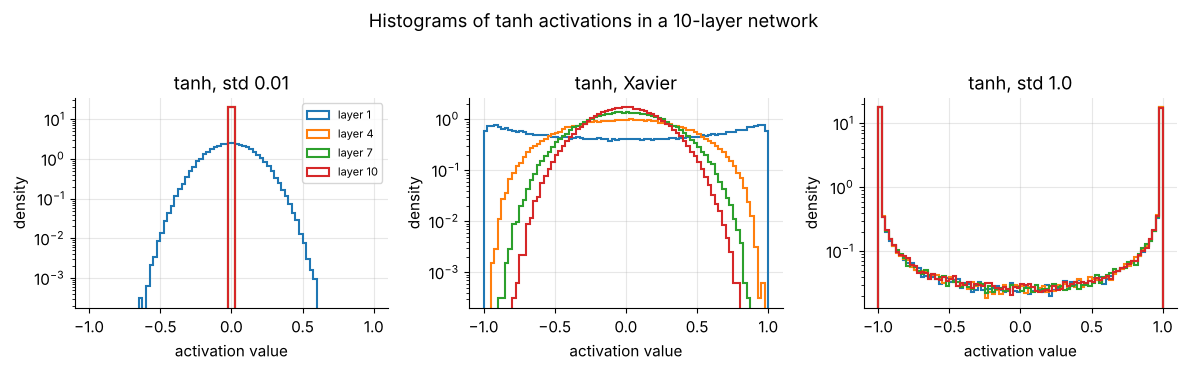

In [56]:
def deep_stack_stats(act_cls, init, depth=10, width=256, m=500, seed=SEED):
    """Activations of every hidden layer and the gradient norm of every hidden weight matrix."""
    r = np.random.default_rng(seed)
    layers = []
    for _ in range(depth):
        layers += [Linear(width, width, r, init), act_cls()]
    net = Sequential(*layers, Linear(width, 10, r, "xavier"))
    X_deep = r.normal(size=(m, width))
    out, acts = X_deep, []
    for layer in net.layers:
        out = layer.forward(out)
        if not isinstance(layer, Linear):
            acts.append(out)                                   # output of each activation layer
    loss_fn = SoftmaxCrossEntropy()
    loss_fn.forward(out, r.integers(0, 10, size=m))
    net.backward(loss_fn.backward())
    grad_norms = [np.linalg.norm(layer.W.grad) for layer in net.layers if isinstance(layer, Linear)][:depth]
    return acts, np.array(grad_norms)


configs = {"tanh, std 0.01": (Tanh, 0.01), "tanh, Xavier": (Tanh, "xavier"), "tanh, std 1.0": (Tanh, 1.0),
           "sigmoid, Xavier": (Sigmoid, "xavier"), "ReLU, Xavier": (ReLU, "xavier"), "ReLU, He": (ReLU, "he")}
stack_results = {name: deep_stack_stats(*cfg) for name, cfg in configs.items()}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, name in zip(axes, ["tanh, std 0.01", "tanh, Xavier", "tanh, std 1.0"]):
    acts, _ = stack_results[name]
    for l in [0, 3, 6, 9]:
        ax.hist(acts[l].ravel(), bins=np.linspace(-1, 1, 81), histtype="step", density=True, lw=1.5, label=f"layer {l + 1}")
    ax.set(title=name, xlabel="activation value", ylabel="density", yscale="log")
axes[0].legend(fontsize=8)
fig.suptitle("Histograms of tanh activations in a 10-layer network", y=1.02)
fig.tight_layout()
plt.show()

- **Too small** (std $0.01$, left): each layer multiplies the spread by about $256 \times 0.01^2 \cdot$ (slope $\approx 1$), i.e. shrinks the variance roughly 40-fold. After a few layers every activation is essentially $0$ and the histogram collapses into a spike.
- **Xavier** (middle): the distribution stays spread out over all ten layers (it narrows slowly, because tanh's slope is below 1 away from $0$).
- **Too large** (std $1.0$, right): pre-activations are huge, so almost every tanh output sits at $\pm 1$, in the flat zone where $g'(z) \approx 0$: the units are **saturated**.

The same view for the sigmoid and ReLU stacks. About half of all ReLU outputs are exactly zero, so for ReLU the histograms show only the positive values.

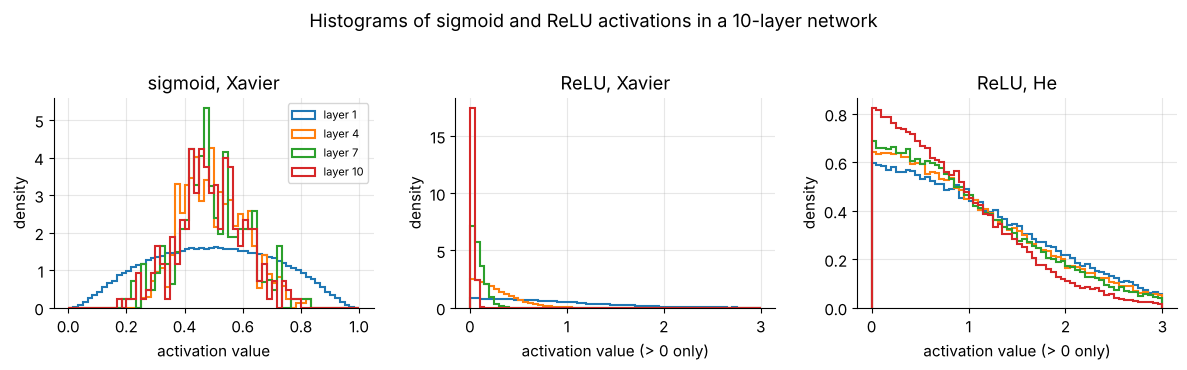

sigmoid stack, layer  1: variation of a unit across the 500 inputs (mean std) 0.2081 | spread between units 0.0097
sigmoid stack, layer  4: variation of a unit across the 500 inputs (mean std) 0.0027 | spread between units 0.1114
sigmoid stack, layer 10: variation of a unit across the 500 inputs (mean std) 0.0000 | spread between units 0.1160


In [57]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, name in zip(axes, ["sigmoid, Xavier", "ReLU, Xavier", "ReLU, He"]):
    acts, _ = stack_results[name]
    is_relu = name.startswith("ReLU")
    for l in [0, 3, 6, 9]:
        values = acts[l].ravel()
        if is_relu:
            values = values[values > 0]                  # drop the exact zeros
        ax.hist(values, bins=np.linspace(0, 3 if is_relu else 1, 61), histtype="step", density=True,
                lw=1.5, label=f"layer {l + 1}")
    ax.set(title=name, xlabel="activation value" + (" (> 0 only)" if is_relu else ""), ylabel="density")
axes[0].legend(fontsize=8)
fig.suptitle("Histograms of sigmoid and ReLU activations in a 10-layer network", y=1.02)
fig.tight_layout()
plt.show()
acts_sig, _ = stack_results["sigmoid, Xavier"]
for l in [0, 3, 9]:
    print(f"sigmoid stack, layer {l + 1:>2}: variation of a unit across the 500 inputs (mean std) "
          f"{acts_sig[l].std(axis=0).mean():.4f} | spread between units {acts_sig[l].mean(axis=0).std():.4f}")

- **sigmoid, Xavier**: the activations crowd around $0.5$ and break up into narrow spikes. Each spike is a single unit whose output is almost the same for every input: from layer 4 on, a unit varies across the 500 inputs by less than $0.003$ (printed above), while different units differ by about $0.11$. The culprit is the offset: every sigmoid output is about $0.5$ plus a small input-dependent part, so each pre-activation of the next layer is dominated by $0.5$ times the sum of that unit's weights, the same number for every input. The input-dependent part, meanwhile, is multiplied by a slope of at most $\tfrac14$ at every layer and fades away. The deep layers have effectively **forgotten the input**. Zero-centered activations such as tanh avoid this trap.
- **ReLU, Xavier**: the distribution slides toward $0$ layer after layer. By layer 10 almost everything sits in the first bin.
- **ReLU, He**: the distribution keeps the same shape at every depth, which is exactly what the variance argument promised.

Now the summary statistics for all six configurations: the standard deviation of the activations, and the gradient norm, layer by layer.

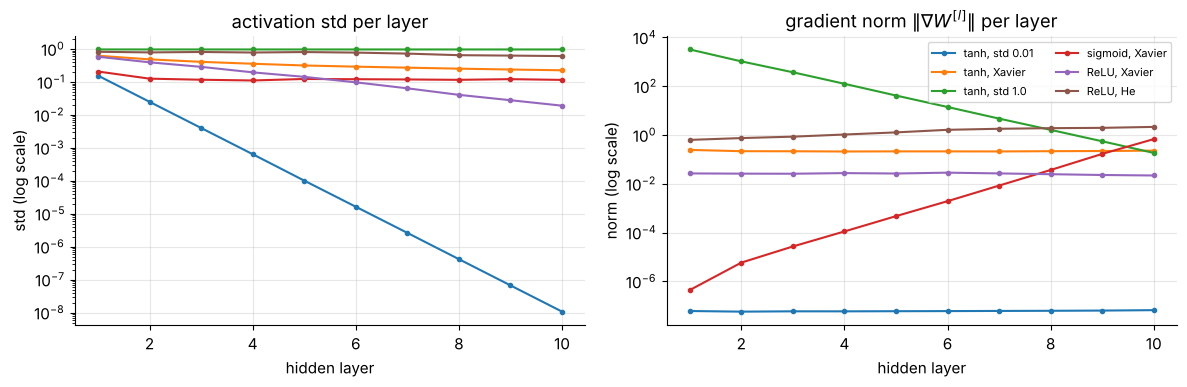

,configuration,"act. std, layer 1","act. std, layer 10","grad norm, layer 1","grad norm, layer 10"
0,"tanh, std 0.01",1.56e-01,1.07e-08,6.14e-08,6.66e-08
1,"tanh, Xavier",6.28e-01,2.27e-01,2.47e-01,2.30e-01
2,"tanh, std 1.0",9.75e-01,9.74e-01,3.23e+03,1.86e-01
3,"sigmoid, Xavier",2.09e-01,1.16e-01,4.42e-07,6.84e-01
4,"ReLU, Xavier",5.85e-01,1.91e-02,2.68e-02,2.21e-02
5,"ReLU, He",8.28e-01,6.12e-01,6.34e-01,2.16e+00


In [58]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rows = []
for name, (acts, grad_norms) in stack_results.items():
    stds = [a.std() for a in acts]
    axes[0].plot(range(1, 11), stds, "o-", ms=3, label=name)
    axes[1].plot(range(1, 11), grad_norms, "o-", ms=3, label=name)
    rows.append({"configuration": name, "act. std, layer 1": stds[0], "act. std, layer 10": stds[-1],
                 "grad norm, layer 1": grad_norms[0], "grad norm, layer 10": grad_norms[-1]})
axes[0].set(title="activation std per layer", xlabel="hidden layer", ylabel="std (log scale)", yscale="log")
axes[1].set(title=r"gradient norm $\|\nabla W^{[l]}\|$ per layer", xlabel="hidden layer", ylabel="norm (log scale)", yscale="log")
axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()
display(pd.DataFrame(rows).map(lambda v: f"{v:.2e}" if isinstance(v, float) else v))

Read the table row by row:

- **tanh, std 0.01**: the activations vanish (their std drops from about $0.16$ to essentially zero) and every weight gradient is around $10^{-7}$: the network cannot learn.
- **tanh, std 1.0**: the activations saturate, and the gradients **explode** toward the input: layer 1 receives a gradient more than ten thousand times larger than layer 10. Large weights multiply the backward signal at every layer by more than the (small) saturated derivative removes.
- **sigmoid, Xavier**: the classic **vanishing gradient**: the gradient of layer 1 is about a million times smaller than that of layer 10, because every sigmoid layer multiplies the backward signal by $\sigma' \le \tfrac14$. The first layers barely learn. This is why sigmoid hidden units fell out of use for deep networks.
- **ReLU, Xavier**: Xavier's variance $2/(256 + 256) = 1/256$ is half of what ReLU needs, so the activation std shrinks by a factor of about $1/\sqrt2$ per layer, and the variance argument predicts $0.58 \cdot 2^{-9/2} \approx 0.026$ at layer 10 (nine factors of $1/\sqrt2$). This particular draw of random weights gives $0.019$: with only 256 units, each layer's factor fluctuates a little around $1/\sqrt2$, but averaged over many random draws the prediction is met closely.
- **ReLU, He** and **tanh, Xavier**: activations and gradients stay within the same order of magnitude across all ten layers. These are the healthy configurations.

> **Key idea.** Choose the initial weight variance so that one layer multiplies the signal's variance by about $1$: $\sigma_w^2 = 2/n_{\text{in}}$ for ReLU (He), $\sigma_w^2 = 2/(n_{\text{in}} + n_{\text{out}})$ for tanh/sigmoid (Xavier). Initialize biases to zero.

> **Going deeper.** Careful initialization is only the first line of defense. Very deep modern networks also use **normalization layers** (BatchNorm, LayerNorm), which re-standardize activations at every layer during training, and **residual connections** $\mathbf{h}_{l+1} = \mathbf{h}_l + F(\mathbf{h}_l)$, which give the gradient a path that skips the multiplications altogether. Together they made networks with hundreds of layers trainable.

**Quick check.** A network has a hidden layer with 1024 inputs and 512 outputs, followed by ReLU. What standard deviation should its initial weights have under He initialization, and under Xavier?

<details>
<summary>Answer</summary>

He: $\sigma_w = \sqrt{2/1024} \approx 0.0442$. Xavier: $\sigma_w = \sqrt{2/(1024 + 512)} \approx 0.0361$. Since the layer is followed by a ReLU, He is the appropriate choice. Xavier would make the signal shrink by a factor of about $\sqrt{0.0361^2 \cdot 1024 / 2} \approx 0.82$ per layer.
</details>

## 8. Optimizers: SGD, momentum and Adam

Backpropagation tells us the gradient. The **optimizer** decides what to do with it. Plain SGD takes a step $-\eta\,\mathbf{g}$. This section shows where that simple rule struggles and how the two most widely used improvements, momentum and Adam, fix it.

### 8.1 The trouble with plain gradient descent: ravines

Loss surfaces of neural networks are full of long, narrow valleys: steep in some directions, almost flat in others. The simplest model of such a **ravine** is the quadratic

$$
f(u, v) = \tfrac12\big(u^2 + \kappa\,v^2\big), \qquad \nabla f = (u,\; \kappa v), \qquad \kappa = 50 .
$$

A gradient step with learning rate $\eta$ updates the two coordinates independently:

$$
u \leftarrow (1 - \eta)\,u, \qquad v \leftarrow (1 - \eta\kappa)\,v .
$$

The steep direction $v$ is stable only if $|1 - \eta\kappa| < 1$, i.e. $\eta < 2/\kappa = 0.04$. Beyond that, $v$ grows at every step and the iteration diverges. But with $\eta < 0.04$, the flat direction $u$ shrinks by a factor of at least $0.96$ per step: painfully slow. The steepest direction limits the step size, the flattest direction sets the pace, and the number of steps needed grows with the **condition number** $\kappa$ (the ratio of the largest to the smallest curvature). This is the basic reason plain SGD can be slow.

### 8.2 Momentum: a heavy ball rolling downhill

**Momentum** keeps a running "velocity" $\mathbf{v}$ that accumulates past gradients (we use PyTorch's convention):

$$
\mathbf{v} \leftarrow \mu\,\mathbf{v} + \mathbf{g}, \qquad \boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\,\mathbf{v}, \qquad \text{typically } \mu = 0.9 .
$$

Unrolling the recursion, $\mathbf{v}_t = \mathbf{g}_t + \mu\,\mathbf{g}_{t-1} + \mu^2\mathbf{g}_{t-2} + \cdots$, an exponentially weighted sum of past gradients. Two consequences:

- Along a direction where the gradient is **consistent** (the floor of the ravine), the terms add up: for a constant gradient, $\mathbf{v} \to \mathbf{g}(1 + \mu + \mu^2 + \cdots) = \mathbf{g}/(1 - \mu)$. The effective learning rate becomes $\eta/(1 - \mu)$, ten times larger for $\mu = 0.9$.
- Along a direction where the gradient **flips sign** at every step (across the ravine), consecutive terms cancel, damping the zig-zag.

Think of a heavy ball rolling down the valley: its inertia carries it along the floor and smooths out the bouncing between the walls. Momentum also averages out some of the noise of mini-batch gradients.

### 8.3 Adam: momentum plus a per-parameter step size

**Adam** (Kingma and Ba, 2015) keeps two exponential moving averages for every parameter: of the gradient ($\mathbf{m}$, the "first moment") and of the squared gradient ($\mathbf{s}$, the "second moment"). At step $t = 1, 2, \dots$, with all operations elementwise:

$$
\mathbf{m} \leftarrow \beta_1\mathbf{m} + (1 - \beta_1)\,\mathbf{g}, \qquad
\mathbf{s} \leftarrow \beta_2\mathbf{s} + (1 - \beta_2)\,\mathbf{g}^2, \qquad
\hat{\mathbf{m}} = \frac{\mathbf{m}}{1 - \beta_1^t}, \qquad
\hat{\mathbf{s}} = \frac{\mathbf{s}}{1 - \beta_2^t},
$$

$$
\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\,\frac{\hat{\mathbf{m}}}{\sqrt{\hat{\mathbf{s}}} + \varepsilon},
\qquad \text{defaults: } \beta_1 = 0.9,\; \beta_2 = 0.999,\; \varepsilon = 10^{-8},\; \eta = 10^{-3}.
$$

- $\hat{\mathbf{m}}$ plays the role of momentum: a smoothed gradient direction.
- Dividing by $\sqrt{\hat{\mathbf{s}}}$, the typical size of each parameter's recent gradients, gives **every parameter its own step size**. A parameter with huge gradients takes steps of about $\eta$, and so does a parameter with tiny gradients. In particular, multiplying the loss by any constant $c > 0$ multiplies both $\hat{\mathbf{m}}$ and $\sqrt{\hat{\mathbf{s}}}$ by $c$ and leaves the update unchanged (up to $\varepsilon$): Adam is invariant to the scale of the gradients, which makes its learning rate much easier to choose.
- **Bias correction.** Both averages start at $\mathbf{0}$, so early on they are biased toward zero. If the gradient were constant, $\mathbf{g}_s = \mathbf{g}$, then $\mathbf{m}_t = (1 - \beta_1)\sum_{s=1}^{t}\beta_1^{t-s}\,\mathbf{g} = (1 - \beta_1^t)\,\mathbf{g}$ (a geometric sum). Dividing by $1 - \beta_1^t$ removes exactly this factor. Without the correction, the first steps would be tiny for $\mathbf{m}$ and, worse, $\mathbf{s}$ would be underestimated far more ($1 - \beta_2 = 0.001$), making early steps erratically large.

Here are the two optimizers for our library, with the same `step()` interface as `SGD`:

In [59]:
class Momentum:
    """SGD with momentum (PyTorch convention): v <- mu * v + g, then theta <- theta - lr * v."""

    def __init__(self, params, lr=0.01, momentum=0.9):
        self.params, self.lr, self.mu = list(params), lr, momentum
        self.velocity = [np.zeros_like(p.value) for p in self.params]

    def step(self):
        for p, v in zip(self.params, self.velocity):
            v *= self.mu
            v += p.grad
            p.value -= self.lr * v


class Adam:
    """Adam with bias-corrected first and second moment estimates."""

    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        self.params, self.lr, self.betas, self.eps = list(params), lr, betas, eps
        self.m = [np.zeros_like(p.value) for p in self.params]
        self.s = [np.zeros_like(p.value) for p in self.params]
        self.t = 0

    def step(self):
        self.t += 1
        beta1, beta2 = self.betas
        for p, m, s in zip(self.params, self.m, self.s):
            m *= beta1
            m += (1 - beta1) * p.grad
            s *= beta2
            s += (1 - beta2) * p.grad ** 2
            m_hat = m / (1 - beta1 ** self.t)
            s_hat = s / (1 - beta2 ** self.t)
            p.value -= self.lr * m_hat / (np.sqrt(s_hat) + self.eps)

### 8.4 The three optimizers in the ravine

We start all three at $(u, v) = (-4, 1)$ on the ravine with $\kappa = 50$ and take 60 steps: SGD with $\eta = 0.035$ (just below the stability limit $0.04$), momentum with $\eta = 0.02$ and $\mu = 0.8$, and Adam with $\eta = 0.3$. The "network" here is a single `Param` holding $(u, v)$, whose gradient we set by hand.

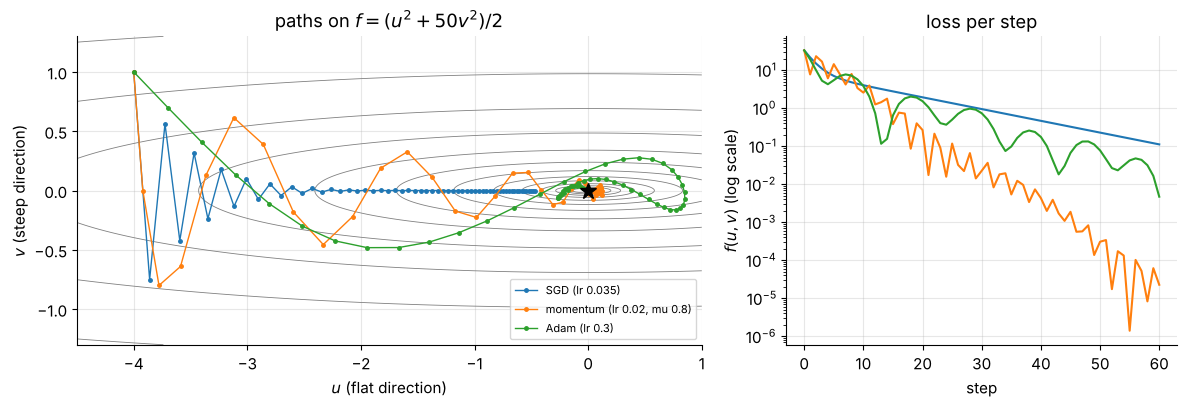

,f after 10 steps,f after 30 steps,f after 60 steps
SGD (lr 0.035),4.0e+00,9.4e-01,1.1e-01
"momentum (lr 0.02, mu 0.8)",2.6e+00,2.3e-02,2.3e-05
Adam (lr 0.3),3.8e+00,7.3e-01,4.7e-03


In [60]:
KAPPA = np.array([1.0, 50.0])


def ravine_path(make_opt, steps=60, start=(-4.0, 1.0), scale=1.0):
    """Optimize f(u, v) = scale * (u^2 + 50 v^2) / 2 from `start`. Return the visited points."""
    theta = Param(np.array(start), "theta")
    opt = make_opt([theta])
    path = [theta.value.copy()]
    for _ in range(steps):
        theta.grad = scale * KAPPA * theta.value          # exact gradient of the quadratic
        opt.step()
        path.append(theta.value.copy())
    return np.array(path)


def ravine_f(path):
    return 0.5 * (KAPPA * path ** 2).sum(axis=1)


ravine_opts = {"SGD (lr 0.035)": lambda ps: SGD(ps, lr=0.035),
               "momentum (lr 0.02, mu 0.8)": lambda ps: Momentum(ps, lr=0.02, momentum=0.8),
               "Adam (lr 0.3)": lambda ps: Adam(ps, lr=0.3)}
paths = {name: ravine_path(make) for name, make in ravine_opts.items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
U, V = np.meshgrid(np.linspace(-4.5, 1.0, 300), np.linspace(-1.3, 1.3, 300))
axes[0].contour(U, V, 0.5 * (U ** 2 + 50 * V ** 2), levels=np.logspace(-2, 2, 14), colors="gray", linewidths=0.6)
for name, path in paths.items():
    axes[0].plot(path[:, 0], path[:, 1], "o-", ms=2.5, lw=1, label=name)
    axes[1].semilogy(ravine_f(path), label=name)
axes[0].plot(0, 0, "k*", ms=12)
axes[0].set(title=r"paths on $f = (u^2 + 50v^2)/2$", xlabel="$u$ (flat direction)", ylabel="$v$ (steep direction)")
axes[1].set(title="loss per step", xlabel="step", ylabel="$f(u, v)$ (log scale)")
axes[0].legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()
display(pd.DataFrame({name: {"f after 10 steps": ravine_f(p)[10], "f after 30 steps": ravine_f(p)[30],
                             "f after 60 steps": ravine_f(p)[60]} for name, p in paths.items()}).T.map(lambda v: f"{v:.1e}"))

SGD bounces between the walls (its $v$-factor $1 - 0.035 \cdot 50 = -0.75$ flips the sign at every step) while it creeps along the floor, still far from the minimum after 60 steps. Momentum builds up speed along the floor and reaches a loss thousands of times smaller. Adam's first steps move both coordinates by about the same amount, $\eta$ each: that is the per-parameter normalization at work, giving the steep direction no bigger steps than the flat one. Its momentum then carries it past the minimum, and it circles back in a slowly shrinking loop. With a fixed $\eta$, Adam settles only slowly (its steps stay of order $\eta$ as long as the gradient keeps a consistent sign), which is one reason it is often combined with a learning rate that decays during training.

This tidy quadratic happens to suit tuned momentum very well. Adam's real advantage shows up in messy, high-dimensional networks whose parameters have gradients of wildly different sizes. Here is the scale-invariance property from Section 8.3 in action: multiply the loss by $1000$.

In [61]:
adam_1 = ravine_path(lambda ps: Adam(ps, lr=0.3))
adam_1000 = ravine_path(lambda ps: Adam(ps, lr=0.3), scale=1000.0)
with np.errstate(over="ignore", invalid="ignore"):                  # SGD is expected to blow up here
    sgd_1000 = ravine_path(lambda ps: SGD(ps, lr=0.035), scale=1000.0)
print("Adam, loss x1000: largest difference from the original path =", np.abs(adam_1 - adam_1000).max())
print("SGD,  loss x1000: |v| after 5 steps =", f"{abs(sgd_1000[5, 1]):.2e}", "(diverged)")

Adam, loss x1000: largest difference from the original path = 1.0206414546853892e-08
SGD,  loss x1000: |v| after 5 steps = 1.64e+16 (diverged)


Adam follows exactly the same path (up to rounding and the tiny $\varepsilon$), while SGD with the same learning rate explodes, because its steps are $1000$ times larger. With SGD, the learning rate has to be re-tuned whenever the scale of the loss or of the gradients changes. With Adam it mostly does not.

### 8.5 The optimizers on a real network

Back to the spiral and the $2 \to 32 \to 32 \to 3$ ReLU network, 60 epochs with batches of 32. We compare SGD with two learning rates, momentum, and Adam with two learning rates.

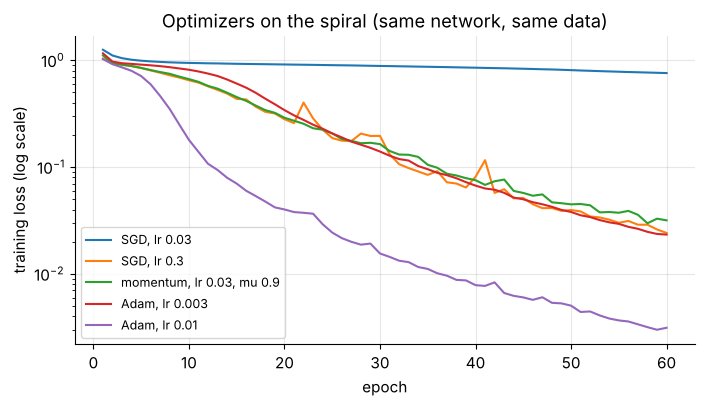

,optimizer,loss after 5 epochs,loss after 20 epochs,loss after 60 epochs,validation accuracy
0,"SGD, lr 0.03",0.9915,0.9142,0.7596,0.5356
1,"SGD, lr 0.3",0.8457,0.2807,0.0242,0.9933
2,"momentum, lr 0.03, mu 0.9",0.8495,0.2898,0.0317,0.9900
3,"Adam, lr 0.003",0.9110,0.3417,0.0233,0.9944
4,"Adam, lr 0.01",0.7118,0.0401,0.0031,1.0000


In [62]:
spiral_opts = {"SGD, lr 0.03": lambda ps: SGD(ps, lr=0.03),
               "SGD, lr 0.3": lambda ps: SGD(ps, lr=0.3),
               "momentum, lr 0.03, mu 0.9": lambda ps: Momentum(ps, lr=0.03, momentum=0.9),
               "Adam, lr 0.003": lambda ps: Adam(ps, lr=0.003),
               "Adam, lr 0.01": lambda ps: Adam(ps, lr=0.01)}
fig, ax = plt.subplots(figsize=(8, 4))
rows = []
for name, make in spiral_opts.items():
    r = np.random.default_rng(SEED)
    model = make_mlp([2, 32, 32, 3], r)
    hist = fit(model, SoftmaxCrossEntropy(), make(model.parameters()), X_sp, y_sp, epochs=60, batch_size=32,
               rng=r, X_val=X_spv, y_val=y_spv)
    ax.plot(range(1, 61), hist["loss"], label=name)
    rows.append({"optimizer": name, "loss after 5 epochs": hist["loss"][4], "loss after 20 epochs": hist["loss"][19],
                 "loss after 60 epochs": hist["loss"][-1], "validation accuracy": hist["val_acc"][-1]})
ax.set(yscale="log", xlabel="epoch", ylabel="training loss (log scale)", title="Optimizers on the spiral (same network, same data)")
ax.legend(fontsize=9)
plt.show()
display(pd.DataFrame(rows).round(4))

Three lessons from this table:

- **SGD is sensitive to its learning rate**: with $\eta = 0.03$ it has barely started after 60 epochs (loss $0.76$, validation accuracy $0.54$), while $\eta = 0.3$ solves the problem.
- **Momentum with $\eta = 0.03$ and $\mu = 0.9$ behaves almost exactly like SGD with $\eta = 0.3$**, just as the effective-learning-rate formula $\eta/(1 - \mu) = 0.03/0.1 = 0.3$ predicts. Momentum is not magic. On a noisy problem like this one, much of its benefit is a larger effective step taken more smoothly.
- **Adam** with $\eta = 0.01$ reaches the lowest loss by far, and even with the more cautious $\eta = 0.003$ it matches the best SGD run. This robustness is why Adam (or its variant AdamW, Section 10) is a popular first choice for training MLPs. The next notebooks deliberately start from a simple baseline, plain SGD (Notebooks 11 and 12) or SGD with momentum (Notebook 13), and then compare it with Adam.

> **Common pitfall.** "Adam with lr 0.01 worked for my small MLP, so lr 0.01 must be good for Adam in general" is not true. The scale invariance of Section 8.3 removes the dependence on the *gradient's* size, but not on the *problem*: large networks typically need $10^{-4}$ to $10^{-3}$. Always try a few values spaced by factors of about 3 (e.g. $10^{-3}, 3 \times 10^{-3}, 10^{-2}$).

> **Going deeper.** In practice the learning rate is also changed *during* training by a **schedule**: a short **warm-up** (growing from near 0 for the first few hundred steps, which protects Adam while its moment estimates are still unreliable) followed by a **decay** (step-wise, exponential or cosine-shaped), so that the final iterations settle into a minimum instead of rattling around it as in the ravine picture. PyTorch provides these in `torch.optim.lr_scheduler`.

### ✏️ Exercise 10: one step of Adam

Write `adam_update(theta, grad, m, s, t, lr, beta1, beta2, eps)` as a **pure function**: it must not modify its input arrays, and it returns the new `(theta, m, s)` after Adam step number `t` (the first step is `t = 1`). The checker runs five steps side by side with `torch.optim.Adam` and also checks the "first step moves every coordinate by about `lr`" property.

In [63]:
# ✏️ Exercise 10: Adam, one step at a time
def adam_update(theta, grad, m, s, t, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
    """Return (new_theta, new_m, new_s) after Adam step t >= 1, without modifying the inputs."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    c = np.array([1.0, 10.0, 100.0])                       # f(theta) = sum(c * theta^2): very different curvatures
    theta, m, s = np.array([1.0, -2.0, 0.5]), np.zeros(3), np.zeros(3)
    theta_t = torch.tensor(theta.copy(), requires_grad=True)
    opt_t = torch.optim.Adam([theta_t], lr=0.1)
    for t in range(1, 6):
        grad = 2 * c * theta
        theta_before = theta.copy()
        theta_new, m, s = adam_update(theta, grad, m, s, t, lr=0.1)
        assert np.array_equal(theta, theta_before), "do not modify theta in place. Return a new array"
        theta = theta_new
        opt_t.zero_grad()
        (torch.tensor(c) * theta_t ** 2).sum().backward()
        opt_t.step()
        assert np.allclose(theta, theta_t.detach().numpy(), atol=1e-10), \
            f"step {t}: got {theta}, torch.optim.Adam gives {theta_t.detach().numpy()}"
    first, _, _ = adam_update(np.ones(2), np.array([1e-3, 1e3]), np.zeros(2), np.zeros(2), 1, lr=0.1)
    assert np.allclose(1.0 - first, 0.1, atol=1e-4), "the first step should move each coordinate by about lr"


run_check("Exercise 10", _test)

⏳ Exercise 10: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def adam_update(theta, grad, m, s, t, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
    m = beta1 * m + (1 - beta1) * grad          # new arrays: the inputs stay untouched
    s = beta2 * s + (1 - beta2) * grad ** 2
    m_hat = m / (1 - beta1 ** t)
    s_hat = s / (1 - beta2 ** t)
    return theta - lr * m_hat / (np.sqrt(s_hat) + eps), m, s
```
At $t = 1$ the bias corrections give $\hat m = g$ and $\hat s = g^2$, so the step is $\eta\,g/(|g| + \varepsilon) \approx \eta\,\operatorname{sign}(g)$: every coordinate moves by about $\eta$, whether its gradient is $10^{-3}$ or $10^{3}$.
</details>

## 9. What can an MLP represent? Universal approximation, width and depth

Section 6 showed MLPs bending their decision boundaries around circles and spirals. How far does this go? Could a big enough MLP represent *any* function? The answer is yes (in a precise sense), and the reason is surprisingly concrete: simple activations can be added up to build arbitrary shapes, like bricks. We work in one dimension, where everything can be drawn, with the target function

$$
t(x) = x\sin(3x) + \tfrac12 x \qquad \text{on } [-2, 2].
$$

### 9.1 Building functions out of ReLUs

Pick $n + 1$ points $k_0 < k_1 < \dots < k_n$ (the **knots**) and connect the values $t(k_j)$ by straight segments. Call $s_j$ the slope of segment $j$ (between $k_{j-1}$ and $k_j$). This "connect the dots" function can be written exactly as a one-hidden-layer ReLU network:

$$
f(x) = t(k_0) + \sum_{i=0}^{n-1} c_i\,\operatorname{ReLU}(x - k_i), \qquad c_0 = s_1, \quad c_i = s_{i+1} - s_i \;\;(i \ge 1).
$$

*Why it works.* For $x \ge k_0$ and $x$ between $k_j$ and $k_{j+1}$, exactly the units $i = 0, \dots, j$ are active, so the slope of $f$ there is $c_0 + c_1 + \dots + c_j = s_1 + (s_2 - s_1) + \dots + (s_{j+1} - s_j) = s_{j+1}$, a telescoping sum. So $f$ starts at the right value $t(k_0)$, is continuous, and has the right slope on every segment: it passes through every knot. Each ReLU unit contributes one "kink" at its knot, and its outgoing weight $c_i$ is the **change of slope** there. As a network: unit $i$ has input weight $1$ and bias $-k_i$, output weight $c_i$, and the output bias is $t(k_0)$.

How good is the approximation? On a segment of width $\Delta$, linear interpolation is off by at most $\frac{\Delta^2}{8}\max|t''|$ (a standard calculus fact). With $n$ equal segments on $[-2, 2]$, $\Delta = 4/n$, so the error is at most $\frac{2\max|t''|}{n^2}$: **doubling the number of hidden units divides the error by about 4.**

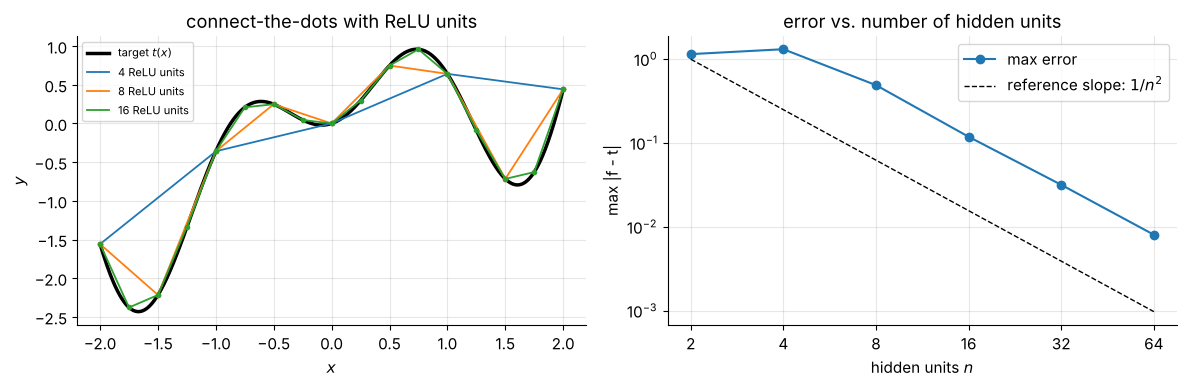

,hidden units,max error,error ratio when doubling
0,2,1.1497,NaN
1,4,1.3155,0.8740
2,8,0.4906,2.6816
3,16,0.1189,4.1249
4,32,0.0318,3.7424
5,64,0.0081,3.9393


In [64]:
def target_fn(x):
    return x * np.sin(3 * x) + 0.5 * x


def relu_interpolation_net(fn, a, b, n_units):
    """Weights of a 1 -> n_units -> 1 ReLU network that linearly interpolates fn at n_units + 1 equal knots."""
    knots = np.linspace(a, b, n_units + 1)
    slopes = np.diff(fn(knots)) / np.diff(knots)
    W1, b1 = np.ones((1, n_units)), -knots[None, :-1]           # unit i: ReLU(x - k_i)
    W2 = np.r_[slopes[0], np.diff(slopes)][:, None]             # change of slope at each knot
    b2 = np.array([[fn(knots[0])]])
    return W1, b1, W2, b2, knots


def two_layer_relu(x, W1, b1, W2, b2):
    return np.maximum(x[:, None] @ W1 + b1, 0.0) @ W2 + b2


x_dense = np.linspace(-2, 2, 2001)
rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x_dense, target_fn(x_dense), color="black", lw=2.5, label="target $t(x)$")
for n_units in [2, 4, 8, 16, 32, 64]:
    W1, b1, W2, b2, knots = relu_interpolation_net(target_fn, -2.0, 2.0, n_units)
    approx = two_layer_relu(x_dense, W1, b1, W2, b2).ravel()
    rows.append({"hidden units": n_units, "max error": np.abs(approx - target_fn(x_dense)).max()})
    if n_units in (4, 8, 16):
        axes[0].plot(x_dense, approx, lw=1.3, label=f"{n_units} ReLU units")
        axes[0].plot(knots, target_fn(knots), "o", ms=3, color=axes[0].lines[-1].get_color())
err_df = pd.DataFrame(rows)
err_df["error ratio when doubling"] = err_df["max error"].shift(1) / err_df["max error"]
axes[0].set(title="connect-the-dots with ReLU units", xlabel="$x$", ylabel="$y$")
axes[0].legend(fontsize=8)
axes[1].loglog(err_df["hidden units"], err_df["max error"], "o-", label="max error")
axes[1].loglog(err_df["hidden units"], 4.0 / err_df["hidden units"] ** 2, "k--", lw=1, label="reference slope: $1/n^2$")
axes[1].set(title="error vs. number of hidden units", xlabel="hidden units $n$", ylabel="max |f - t|")
axes[1].minorticks_off()
axes[1].set_xticks(err_df["hidden units"], [str(n) for n in err_df["hidden units"]])
axes[1].legend()
fig.tight_layout()
plt.show()
display(err_df.round(4))

The table confirms the $1/n^2$ rate: once the knots are dense enough to follow the wiggles, every doubling of the width cuts the maximum error by a factor close to 4. With 64 units the curve is drawn to within about $0.01$. Nothing in this construction is specific to our target: **any continuous function on an interval can be approximated this way**, to any accuracy, by taking enough knots.

### 9.2 Sigmoid units build bumps

The same idea works with S-shaped activations, through a different brick. A steep sigmoid $\sigma(s(x - a))$ with a large steepness $s$ is almost a step from $0$ to $1$ at $x = a$. The difference of two such steps is a **bump**:

$$
\operatorname{bump}_{[a, b]}(x) = \sigma\big(s(x - a)\big) - \sigma\big(s(x - b)\big) \approx \begin{cases} 1 & a < x < b \\ 0 & \text{otherwise}, \end{cases}
$$

which uses two hidden units. Cut $[-2, 2]$ into $n$ intervals and add one bump per interval, with height equal to the target's value at the interval's midpoint: the result is a staircase that hugs the target. (Neighboring steps can be merged, so $n + 1$ sigmoid units suffice.)

8 bumps (9 sigmoid units after merging): max error on [-1.9, 1.9] = 0.783
32 bumps (33 sigmoid units after merging): max error on [-1.9, 1.9] = 0.235


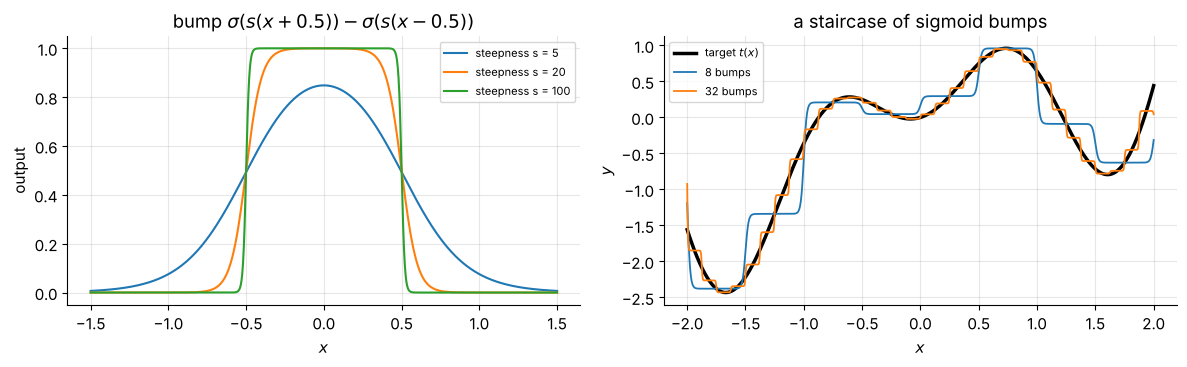

In [65]:
x_bump = np.linspace(-1.5, 1.5, 601)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for steep in [5, 20, 100]:
    axes[0].plot(x_bump, sigmoid(steep * (x_bump + 0.5)) - sigmoid(steep * (x_bump - 0.5)), label=f"steepness s = {steep}")
axes[0].set(title=r"bump $\sigma(s(x + 0.5)) - \sigma(s(x - 0.5))$", xlabel="$x$", ylabel="output")
axes[0].legend(fontsize=8)

axes[1].plot(x_dense, target_fn(x_dense), color="black", lw=2.5, label="target $t(x)$")
for n_bumps in [8, 32]:
    edges = np.linspace(-2, 2, n_bumps + 1)
    heights = target_fn((edges[:-1] + edges[1:]) / 2)                    # value at each interval's midpoint
    steep = 10 * n_bumps                                                  # steeper bricks for narrower intervals
    staircase = sum(h * (sigmoid(steep * (x_dense - lo)) - sigmoid(steep * (x_dense - hi)))
                    for h, lo, hi in zip(heights, edges[:-1], edges[1:]))
    inner = np.abs(x_dense) < 1.9                                         # ignore the half-height ends
    print(f"{n_bumps} bumps ({n_bumps + 1} sigmoid units after merging): "
          f"max error on [-1.9, 1.9] = {np.abs(staircase - target_fn(x_dense))[inner].max():.3f}")
    axes[1].plot(x_dense, staircase, lw=1.3, label=f"{n_bumps} bumps")
axes[1].set(title="a staircase of sigmoid bumps", xlabel="$x$", ylabel="$y$")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

Steeper sigmoids give sharper bumps, and more bumps give a finer staircase. The staircase converges more slowly than the ReLU interpolant (its error shrinks like $1/n$, because each step is flat while the target is sloped), but it converges. Only one property of the sigmoid was used: it goes from one constant level to another. Any such activation would do.

### 9.3 The universal approximation theorem

These constructions are the heart of a famous family of results.

> **Universal approximation theorem** (Cybenko 1989 for sigmoids, Hornik 1991, and Leshno, Lin, Pinkus and Schocken 1993 for the general case). Let $g$ be any continuous activation function that is **not a polynomial**. For every continuous function $f$ on a closed, bounded set $K \subset \mathbb{R}^d$ and every tolerance $\varepsilon > 0$, there is a network with **one hidden layer** of finitely many $g$-units such that $|f(\mathbf{x}) - \hat f(\mathbf{x})| < \varepsilon$ for all $\mathbf{x} \in K$.

Why "not a polynomial"? If $g$ is a polynomial of degree $p$, then every unit $g(\mathbf{w}^\top\mathbf{x} + b)$ is a polynomial of degree at most $p$ in $\mathbf{x}$, and so is any sum of them. And the degree $p$ is fixed by the activation, no matter how many units you add. A polynomial of degree $p$ has at most $p - 1$ turning points, so it cannot stay within $0.5$ of $\sin(10x)$ on $[0, 10]$, which swings between $-1$ and $1$ about 32 times, unless $p > 30$. The extreme case is the identity activation ($p = 1$): the network is linear (Section 1.5).

In more than one dimension the bricks are different but the idea is the same: a hidden unit is a "ridge" that varies only across its hyperplane, and a second layer can combine several half-planes with an AND to build a localized tower (Exercise 11 asks you to build one by hand). The one-hidden-layer theorem shows that even the AND can be avoided, at the price of many more units.

What the theorem does **not** say is just as important:

1. **How many units.** The width needed can be astronomically large. For general functions of $d$ inputs, covering the input space with bricks needs a number of units that grows exponentially with $d$.
2. **That training finds them.** The theorem says good weights *exist*. Gradient descent may or may not find them (Section 9.4).
3. **Generalization.** Fitting a function on a finite training set says nothing, by itself, about new inputs (Section 10).
4. **Extrapolation.** The guarantee holds only on the bounded set $K$. Outside the range of the training data, a ReLU network continues linearly forever, whatever the true function does.

### 9.4 Width in practice: training instead of constructing

The constructions placed every kink by hand. Can gradient descent find comparable weights on its own? We train $1 \to H \to 1$ ReLU networks with $H \in \{2, 4, 8, 32\}$ on 200 equally spaced samples of $t$, using the mean squared error and Adam (learning rate $0.01$, full batch, 1500 epochs).

One 1D-specific detail: with zero initial biases, unit $j$ has its kink at $x = -b_j/w_j = 0$, so *all* kinks would start at the origin. We spread the initial kinks uniformly over $[-2, 2]$ by setting $b_j = -w_j k_j$ with random $k_j$. (In higher dimensions this is less of an issue, since random weight vectors already point in different directions.)

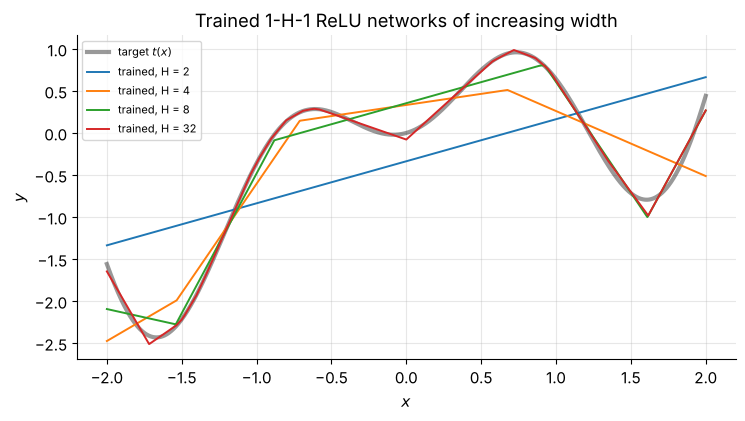

,hidden units H,parameters,final train MSE,"RMSE on [-2, 2]",RMSE of the hand-built interpolant
0,2,7,0.6159,0.7865,0.6649
1,4,13,0.1129,0.3305,0.6833
2,8,25,0.0290,0.1684,0.2052
3,32,97,0.0017,0.0397,0.0131


In [66]:
x_fit = np.linspace(-2, 2, 200)[:, None]
y_fit = target_fn(x_fit)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(x_dense, target_fn(x_dense), color="black", lw=3, alpha=0.4, label="target $t(x)$")
rows = []
for width in [2, 4, 8, 32]:
    r = np.random.default_rng(SEED)
    net = make_mlp([1, width, 1], r)
    first = net.layers[0]
    first.b.value = -first.W.value * r.uniform(-2, 2, size=(1, width))      # kinks at random points in [-2, 2]
    hist = fit(net, MSELoss(), Adam(net.parameters(), lr=0.01), x_fit, y_fit, epochs=1500,
               batch_size=len(x_fit), rng=r, classify=False)
    pred = net.forward(x_dense[:, None]).ravel()
    W1c, b1c, W2c, b2c, _ = relu_interpolation_net(target_fn, -2.0, 2.0, width)
    rows.append({"hidden units H": width, "parameters": 3 * width + 1, "final train MSE": hist["loss"][-1],
                 "RMSE on [-2, 2]": np.sqrt(np.mean((pred - target_fn(x_dense)) ** 2)),
                 "RMSE of the hand-built interpolant": np.sqrt(np.mean(
                     (two_layer_relu(x_dense, W1c, b1c, W2c, b2c).ravel() - target_fn(x_dense)) ** 2))})
    ax.plot(x_dense, pred, lw=1.4, label=f"trained, H = {width}")
ax.set(title="Trained 1-H-1 ReLU networks of increasing width", xlabel="$x$", ylabel="$y$")
ax.legend(fontsize=8)
plt.show()
display(pd.DataFrame(rows).round(4))

Wider is better here too: the training error and the error on the whole interval fall steadily as $H$ grows. Compare the last two columns: for $H = 4$ and $H = 8$ training beats the hand-built interpolant with equally spaced knots (it is free to put kinks where the curve bends most), while for $H = 2$ and $H = 32$ it falls short of it (for $H = 32$ by a factor of about 3 in RMSE). This gap between "the weights exist" and "training finds them" is real, and it is one reason practitioners use networks wider than the theory strictly requires: extra units make the optimization easier.

### 9.5 Depth versus width: the sawtooth

If one hidden layer is enough in principle, why build deep networks? Because depth can be **exponentially more efficient**. Let us count linear pieces.

**A shallow network has few pieces.** In one dimension, unit $j$ of a single hidden layer, $\operatorname{ReLU}(w_jx + b_j)$, has at most one kink, at $x = -b_j/w_j$. The output is a weighted sum of these units plus a constant, so it can only bend at those points: **$H$ units give at most $H + 1$ linear pieces.**

**A deep network can have many.** The **tent map** on $[0, 1]$,

$$
T(x) = 2\operatorname{ReLU}(x) - 4\operatorname{ReLU}\big(x - \tfrac12\big) = \begin{cases} 2x & 0 \le x \le \tfrac12 \\ 2 - 2x & \tfrac12 \le x \le 1, \end{cases}
$$

is a tiny network with 2 hidden units. It maps each half of $[0, 1]$ onto the whole of $[0, 1]$, one half going up and the other coming down. Now compose it with itself: $T^{k} = T \circ T \circ \dots \circ T$ ($k$ times). If $T^{k}$ consists of $2^{k}$ pieces, each running monotonically over the full range $[0, 1]$, then applying $T$ once more splits every piece in two (at the point where the piece crosses $\tfrac12$), giving $2^{k+1}$ pieces of the same kind. By induction, **$T^k$ has $2^k$ linear pieces**: a sawtooth with $2^{k-1}$ teeth. As a network, $T^k$ is $k$ hidden layers of 2 ReLU units each (the output weights of one copy of $T$ merge with the input weights of the next).

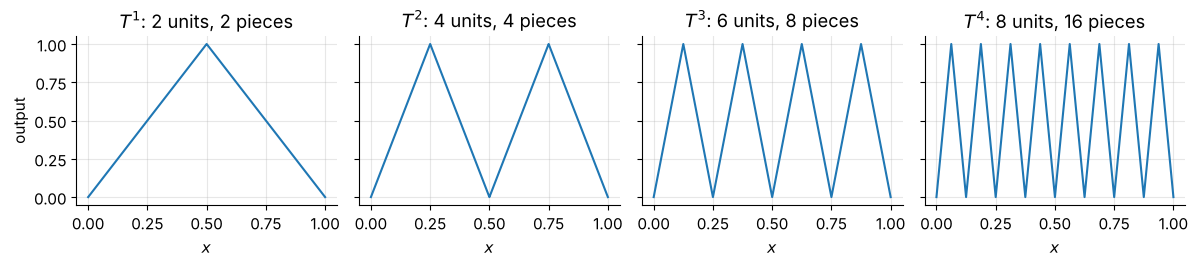

,hidden layers k,hidden units,linear pieces of T^k,units a one-hidden-layer net needs
0,1,2,2,1
1,2,4,4,3
2,3,6,8,7
3,4,8,16,15
4,5,10,32,31
5,6,12,64,63


In [67]:
def tent_block(h):
    """One tent map T(h) = 2 ReLU(h) - 4 ReLU(h - 1/2) as a 1 -> 2 -> 1 ReLU block, and h has shape (m, 1)."""
    hidden = np.maximum(h @ np.array([[1.0, 1.0]]) + np.array([[0.0, -0.5]]), 0.0)
    return hidden @ np.array([[2.0], [-4.0]])


def count_linear_pieces(x, y, tol=1e-6):
    """Number of linear pieces of a piecewise linear function sampled at x (kinks must lie on grid points)."""
    slopes = np.diff(y) / np.diff(x)
    return 1 + int(np.sum(np.abs(np.diff(slopes)) > tol))


x_saw = np.linspace(0, 1, 2 ** 12 + 1)                 # dyadic grid: every kink j / 2^k is a grid point
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8), sharey=True)
rows, h = [], x_saw[:, None]
for depth in range(1, 7):
    h = tent_block(h)                                   # one more hidden layer of 2 units
    pieces = count_linear_pieces(x_saw, h.ravel())
    rows.append({"hidden layers k": depth, "hidden units": 2 * depth, "linear pieces of T^k": pieces,
                 "units a one-hidden-layer net needs": pieces - 1})
    if depth <= 4:
        axes[depth - 1].plot(x_saw, h.ravel())
        axes[depth - 1].set(title=f"$T^{depth}$: {2 * depth} units, {pieces} pieces", xlabel="$x$")
axes[0].set_ylabel("output")
fig.tight_layout()
plt.show()
display(pd.DataFrame(rows))

With 6 hidden layers of 2 units (12 units in total) the network produces 64 linear pieces. A single hidden layer would need at least 63 units to do the same, and with 20 layers the comparison would be 40 units against more than half a million. Telgarsky (2016) turned this example into a theorem: there are functions that deep, narrow ReLU networks compute exactly but that shallow networks can only approximate with exponentially many units.

> **Key idea.** Width adds pieces one at a time. Depth can **multiply** them, because each layer can fold the output of the previous one and reuse all its pieces again. Deep networks are good at functions that are *compositions* of simpler functions, and many natural signals (pixels → edges → shapes → objects) seem to have that structure.

This does not make "as deep as possible" the right choice: Section 7 showed that depth makes signals and gradients harder to control, and the sawtooth is an extreme, very fragile function. In practice, MLPs for tabular data typically use 2 to 4 hidden layers, and the extra depth of modern architectures comes together with the stabilizing tricks mentioned in Section 7.3.

**Quick check.** A $1 \to 16 \to 1$ ReLU network and a $1 \to 4 \to 4 \to 4 \to 4 \to 1$ ReLU network both have 16 hidden units. Which can have more linear pieces on the real line, and what is the maximum for the first one?

<details>
<summary>Answer</summary>

The shallow network has at most $16 + 1 = 17$ pieces (one kink per unit). The deep one can have far more, because every layer folds the pieces produced by the layers below. With 4 units, a layer can compute the zigzag $4\operatorname{ReLU}(x) - 8\operatorname{ReLU}(x - \tfrac14) + 8\operatorname{ReLU}(x - \tfrac12) - 8\operatorname{ReLU}(x - \tfrac34)$, which maps each quarter of $[0, 1]$ onto all of $[0, 1]$ (slopes $\pm 4$). Composing four of them gives $4^4 = 256$ pieces. And no 4-layer network of width 4 can do much better: on each existing piece, each of a layer's 4 units adds at most one kink, so a layer multiplies the number of pieces by at most $5$, for at most $5^4 = 625$.
</details>

### ✏️ Exercise 11: build a 2D tower by hand

In two dimensions a single unit is a ridge: it cannot be "on" in a small region and "off" everywhere else. But a second layer can combine half-planes. Complete `square_tower_params()` so that the network

$$
H = \sigma(XW_1 + \mathbf{b}_1) \;\;(4 \text{ hidden units}), \qquad \text{out} = \sigma(HW_2 + b_2) \;\;(1 \text{ output unit})
$$

outputs more than $0.95$ for points inside the unit square $[0, 1]^2$ (at least $0.1$ away from its border) and less than $0.05$ for points at least $0.1$ outside it. Hint: let each hidden unit detect one side of the square ($x_1 > 0$, $x_1 < 1$, $x_2 > 0$, $x_2 < 1$) with a steep sigmoid. Then make the output unit an AND: it should fire only if all four hidden units are on.

In [68]:
# ✏️ Exercise 11: a hand-built "tower" network
def square_tower_params():
    """Return (W1, b1, W2, b2) with shapes (2, 4), (1, 4), (4, 1), (1, 1)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    W1, b1, W2, b2 = square_tower_params()
    shapes = [np.shape(W1), np.shape(b1), np.shape(W2), np.shape(b2)]
    assert shapes == [(2, 4), (1, 4), (4, 1), (1, 1)], f"wrong shapes {shapes}"
    r = np.random.default_rng(0)
    pts = r.uniform(-2, 3, size=(20000, 2))
    out = sigmoid(sigmoid(pts @ W1 + b1) @ W2 + b2).ravel()
    inside = np.all((pts > 0.1) & (pts < 0.9), axis=1)
    dist_out = np.linalg.norm(np.maximum(np.maximum(-pts, pts - 1), 0), axis=1)   # distance to the square
    outside = dist_out > 0.1
    assert out[inside].min() > 0.95, f"inside the square the output must exceed 0.95 (min was {out[inside].min():.3f})"
    assert out[outside].max() < 0.05, f"far outside the output must stay below 0.05 (max was {out[outside].max():.3f})"


run_check("Exercise 11", _test)

⏳ Exercise 11: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def square_tower_params():
    s, t = 50.0, 20.0                                  # steepness of the walls and of the AND
    W1 = s * np.array([[1.0, -1.0, 0.0, 0.0],          # columns: x1 > 0, x1 < 1, x2 > 0, x2 < 1
                       [0.0, 0.0, 1.0, -1.0]])
    b1 = s * np.array([[0.0, 1.0, 0.0, 1.0]])
    W2 = t * np.ones((4, 1))                          # out = sigma(t * (h1 + h2 + h3 + h4 - 3.5))
    b2 = np.array([[-3.5 * t]])
    return W1, b1, W2, b2
```
At distance $0.1$ inside, every wall unit outputs at least $\sigma(5) \approx 0.993$, so the four sum to more than $3.97$ and the output is $\sigma(20 \cdot 0.47) > 0.9999$. At distance $0.1$ outside, at least one wall unit outputs at most $\sigma(-5) \approx 0.007$, so the sum is below $3.01$ and the output is below $\sigma(-9.8) \approx 6 \times 10^{-5}$. Adding many such towers of different heights (one more layer) approximates any continuous function of two variables, the 2D version of the staircase of Section 9.2.
</details>

## 10. Regularization: weight decay, early stopping and dropout

Section 9 showed that a wide enough network can fit almost anything. That is a blessing and a curse: with few, noisy training examples, a big network can fit **the noise** as well as the signal. It then has a tiny training loss but makes worse predictions on new data. This is **overfitting**, and the techniques that fight it are called **regularization**.

### 10.1 Overfitting, made visible

We use a 1D regression problem, where overfitting can be seen with the naked eye. The truth is $f(x) = \sin(3x) + 0.3x$ on $[-1.5, 1.5]$. We observe only 24 training points with Gaussian noise of standard deviation $0.25$, plus 300 validation points drawn the same way. Because the noise has variance $0.25^2 = 0.0625$, no model can reach a validation MSE much below $0.0625$: that part of the error is **irreducible**. And since we invented the problem, we can also measure what we really care about and normally cannot see: the distance between the learned curve and the true $f$.

The model is deliberately oversized: a $1 \to 64 \to 64 \to 1$ ReLU network (4353 parameters for 24 data points), trained with Adam ($\eta = 0.01$) on the full training set for 1200 epochs.

lowest validation MSE 0.0652 at epoch 97; after 1200 epochs: train MSE 0.0221, validation MSE 0.0881


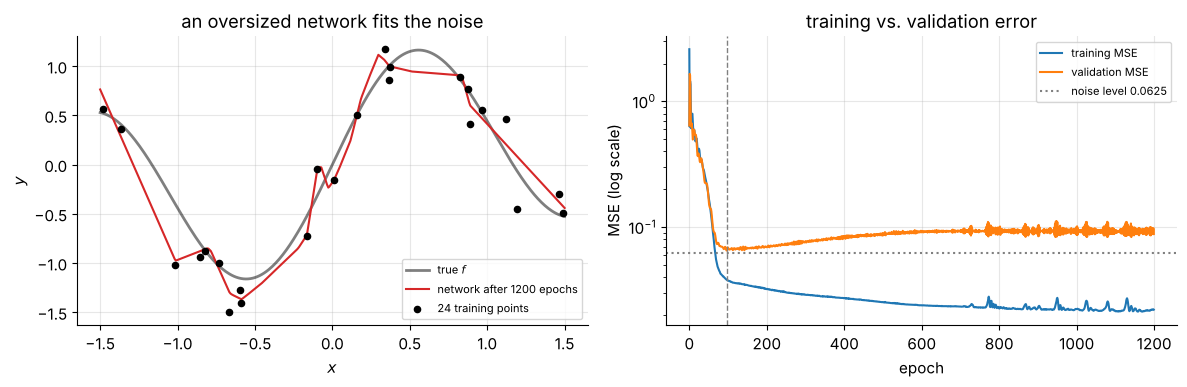

In [69]:
def wavy(x):
    return np.sin(3 * x) + 0.3 * x


r_reg = np.random.default_rng(7)
x_reg = np.sort(r_reg.uniform(-1.5, 1.5, 24))[:, None]
y_reg = wavy(x_reg) + 0.25 * r_reg.normal(size=x_reg.shape)
x_regv = r_reg.uniform(-1.5, 1.5, 300)[:, None]
y_regv = wavy(x_regv) + 0.25 * r_reg.normal(size=x_regv.shape)
x_grid = np.linspace(-1.5, 1.5, 400)[:, None]


def weight_norm(model):
    """Frobenius norm of all weight matrices together (biases excluded)."""
    return float(np.sqrt(sum((p.value ** 2).sum() for p in model.parameters() if p.name == "W")))


def regression_report(name, net, hist=None):
    """Final metrics of a trained regression network (always measured in eval mode)."""
    net.eval()
    mse = MSELoss()
    return {"model": name, "train MSE": mse.forward(net.forward(x_reg), y_reg),
            "validation MSE": mse.forward(net.forward(x_regv), y_regv),
            "MSE vs. true f": float(np.mean((net.forward(x_grid) - wavy(x_grid)) ** 2)),
            "weight norm": weight_norm(net)}


r = np.random.default_rng(SEED)
net_plain = make_mlp([1, 64, 64, 1], r)
hist_plain = fit(net_plain, MSELoss(), Adam(net_plain.parameters(), lr=0.01), x_reg, y_reg, epochs=1200,
                 batch_size=len(x_reg), rng=r, X_val=x_regv, y_val=y_regv, classify=False)
reg_rows = [regression_report("no regularization", net_plain)]
best_plain = int(np.argmin(hist_plain["val_loss"]))
print(f"lowest validation MSE {hist_plain['val_loss'][best_plain]:.4f} at epoch {best_plain + 1}, and "
      f"after 1200 epochs: train MSE {hist_plain['loss'][-1]:.4f}, validation MSE {hist_plain['val_loss'][-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x_grid, wavy(x_grid), color="black", lw=2, alpha=0.5, label="true $f$")
axes[0].plot(x_grid, net_plain.forward(x_grid), color="C3", label="network after 1200 epochs")
axes[0].scatter(x_reg, y_reg, color="black", s=20, zorder=3, label="24 training points")
axes[0].set(title="an oversized network fits the noise", xlabel="$x$", ylabel="$y$")
axes[0].legend(fontsize=8)
axes[1].plot(hist_plain["loss"], label="training MSE")
axes[1].plot(hist_plain["val_loss"], label="validation MSE")
axes[1].axhline(0.0625, color="gray", ls=":", label="noise level 0.0625")
axes[1].axvline(best_plain, color="gray", ls="--", lw=1)
axes[1].set(yscale="log", xlabel="epoch", ylabel="MSE (log scale)", title="training vs. validation error")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

The training error keeps falling, far below the noise level: the network is memorizing the particular noise values of its 24 points, and the left panel shows the result, a curve that zigzags to pass near each training point. The validation error tells the truth: it falls at first, reaches its minimum early (dashed line), and then **rises** while the training error keeps improving. That widening gap is the signature of overfitting.

> **Key idea.** The training loss measures how well the model fits the data it has seen. What we want is low error on data it has *not* seen. Regularization trades a slightly worse fit on the training set for a better fit on new data, usually by preferring **simpler, smoother** functions.

### 10.2 L2 regularization (weight decay)

Add a penalty on the size of the weights to the loss:

$$
\mathcal{L}_{\text{reg}}(\boldsymbol\theta) = \mathcal{L}(\boldsymbol\theta) + \frac{\lambda}{2}\sum_{l}\big\lVert W^{[l]}\big\rVert_F^2,
\qquad \nabla_{W^{[l]}}\mathcal{L}_{\text{reg}} = \nabla_{W^{[l]}}\mathcal{L} + \lambda\,W^{[l]},
$$

where $\lVert W\rVert_F^2$ is the sum of the squares of all entries and $\lambda \ge 0$ sets the strength. (Biases are usually not penalized: they shift units without making the function any steeper.) With plain SGD, the update becomes

$$
W \leftarrow W - \eta\big(\nabla_W\mathcal{L} + \lambda W\big) = (1 - \eta\lambda)\,W - \eta\,\nabla_W\mathcal{L},
$$

so before every gradient step the weights are shrunk by the factor $1 - \eta\lambda$: hence the name **weight decay**. Why do small weights mean a simpler function? A network's output can change quickly only if some weights are large: the slope of a ReLU network is a sum of products of weights along paths through the network. Keeping weights small limits how sharply the function can bend toward individual noisy points.

In code, weight decay is one extra line before the optimizer step. We implement it as a small wrapper, so it works with any of our optimizers:

In [70]:
class WeightDecay:
    """Wrap an optimizer and add lam * W to the gradient of every weight matrix (biases are not decayed)."""

    def __init__(self, opt, lam):
        self.opt, self.lam, self.params = opt, lam, opt.params

    def step(self):
        for p in self.params:
            if p.name == "W":
                p.grad = p.grad + self.lam * p.value          # gradient of (lam / 2) * ||W||^2
        self.opt.step()


reg_nets = {"no regularization": net_plain}
for lam in [1e-3, 1e-2]:
    r = np.random.default_rng(SEED)
    net = make_mlp([1, 64, 64, 1], r)
    fit(net, MSELoss(), WeightDecay(Adam(net.parameters(), lr=0.01), lam), x_reg, y_reg, epochs=1200,
        batch_size=len(x_reg), rng=r, X_val=x_regv, y_val=y_regv, classify=False)
    reg_nets[f"L2, lambda = {lam:g}"] = net
    reg_rows.append(regression_report(f"L2, lambda = {lam:g}", net))
display(pd.DataFrame(reg_rows).round(4))

,model,train MSE,validation MSE,MSE vs. true f,weight norm
0,no regularization,0.0222,0.0881,0.0420,22.3147
1,"L2, lambda = 0.001",0.0235,0.0838,0.0395,6.6033
2,"L2, lambda = 0.01",0.0357,0.0730,0.0255,3.7430


A small penalty, $\lambda = 10^{-3}$, already shrinks the weight norm more than threefold, although the errors barely move. With $\lambda = 10^{-2}$ the effect is clear: the training error rises toward the noise level (the network stops chasing the noise), and the error against the true function drops by about 40%. Too large a $\lambda$ would eventually flatten the curve and **underfit**. Like the learning rate, $\lambda$ is a **hyperparameter** chosen by comparing validation errors.

> **Going deeper.** For SGD, "add $\lambda W$ to the gradient" and "shrink the weights by $1 - \eta\lambda$" are the same thing. For Adam they are not: the added $\lambda W$ gets divided by Adam's per-parameter scale $\sqrt{\hat s}$, so weights with large gradients are barely regularized. **AdamW** (Loshchilov and Hutter, 2019) applies the shrinkage directly to the weights, outside the adaptive step, and usually generalizes better. In PyTorch, prefer `torch.optim.AdamW(params, lr, weight_decay=...)` over `Adam(..., weight_decay=...)`.

### 10.3 Early stopping

The validation curve of Section 10.1 suggests the simplest regularizer of all: **stop training when the validation error stops improving**, and keep the weights from the best epoch. In practice we wait a few epochs before giving up (the validation error is noisy), a number called the **patience**.

In [71]:
def fit_early_stopping(model, loss_fn, opt, X, y, X_val, y_val, *, max_epochs, patience, batch_size, rng):
    """Train epoch by epoch, remember the parameters with the lowest validation loss, stop after
    `patience` epochs without improvement, and restore the best parameters."""
    best_loss, best_epoch, best_params = np.inf, -1, None
    history = {"loss": [], "val_loss": []}
    for epoch in range(max_epochs):
        h = fit(model, loss_fn, opt, X, y, epochs=1, batch_size=batch_size, rng=rng,
                X_val=X_val, y_val=y_val, classify=False)
        history["loss"] += h["loss"]
        history["val_loss"] += h["val_loss"]
        if h["val_loss"][0] < best_loss:                         # strict improvement
            best_loss, best_epoch = h["val_loss"][0], epoch
            best_params = [p.value.copy() for p in model.parameters()]   # a snapshot, not a reference!
        elif epoch - best_epoch >= patience:
            break
    for p, saved in zip(model.parameters(), best_params):
        p.value[...] = saved                                     # restore the best weights in place
    return history, best_epoch


r = np.random.default_rng(SEED)
net_es = make_mlp([1, 64, 64, 1], r)
hist_es, best_es = fit_early_stopping(net_es, MSELoss(), Adam(net_es.parameters(), lr=0.01), x_reg, y_reg,
                                      x_regv, y_regv, max_epochs=1200, patience=100, batch_size=len(x_reg), rng=r)
print(f"stopped after {len(hist_es['val_loss'])} epochs. Best epoch {best_es + 1} restored "
      f"(validation MSE {hist_es['val_loss'][best_es]:.4f})")
reg_nets["early stopping"] = net_es
reg_rows.append(regression_report("early stopping (patience 100)", net_es))

stopped after 197 epochs; best epoch 97 restored (validation MSE 0.0652)


Early stopping ran the same training as Section 10.1 (same seed, so the same trajectory) but stopped about a hundred epochs after the validation minimum and rolled back to it. It costs nothing, needs no change to the loss, and saves compute.

> **Common pitfall.** Once the validation set is used to *choose* something (the stopping epoch, $\lambda$, the architecture), its error is no longer an unbiased estimate of performance on new data: you have tuned on it. The standard discipline is a three-way split: **train** (fit the weights), **validation** (choose hyperparameters and when to stop), **test** (touched once, at the very end, to report the final number). Here the "MSE vs. true $f$" column plays the role of the test set.

Also note `p.value.copy()` in the snapshot. Without `.copy()` the "best" parameters would be references to the live arrays, which keep changing as training continues, and the restore would silently do nothing.

### 10.4 Dropout

**Dropout** (Srivastava, Hinton et al., 2014) regularizes in a completely different way: during training, every hidden activation is independently set to zero with probability $p$ (the **drop rate**), with a fresh random mask for every mini-batch. Each training step thus uses a different random "thinned" sub-network, so no unit can rely on specific other units being present. Units are forced to learn features that are useful on their own, which reduces co-adaptation, a form of overfitting. One can also view dropout as training a huge ensemble of thinned networks that share weights.

**Inverted dropout** (the version every library uses) rescales the survivors so that the expected activation is unchanged. With a mask $M$ whose entries are $1$ with probability $1 - p$ and $0$ otherwise,

$$
\text{training:}\quad \operatorname{out} = \frac{A \odot M}{1 - p}, \qquad \mathbb{E}[\operatorname{out}_{ij}] = \frac{(1 - p)\,a_{ij}}{1 - p} = a_{ij}; \qquad \text{evaluation:}\quad \operatorname{out} = A .
$$

Because of the rescaling, the network needs no change at test time: dropout is simply switched off (`model.eval()` in PyTorch). The backward pass is Rule 1 with the same mask: $\bar A = \bar{\operatorname{out}} \odot M/(1 - p)$. Dropped units pass back no gradient, exactly like an inactive ReLU.

In [72]:
class Dropout(Module):
    """Inverted dropout: in training mode, zero each entry with probability p and scale survivors by 1/(1-p)."""

    def __init__(self, p, rng):
        self.p, self.rng, self.mask = p, rng, None

    def forward(self, x):
        if not self.training or self.p == 0.0:
            self.mask = None
            return x                                             # evaluation mode: identity
        self.mask = (self.rng.random(x.shape) >= self.p) / (1.0 - self.p)
        return x * self.mask

    def backward(self, grad_out):
        return grad_out if self.mask is None else grad_out * self.mask

    def __repr__(self):
        return f"Dropout(p={self.p})"


drop = Dropout(0.3, np.random.default_rng(0))
A_demo = np.ones((2000, 50))
out_train = drop.forward(A_demo)
print(f"training mode: fraction of zeros {np.mean(out_train == 0):.3f} (p = 0.3), survivors equal {out_train.max():.4f} "
      f"(1/0.7 = {1 / 0.7:.4f}), mean {out_train.mean():.4f} (input mean 1.0)")
upstream = np.random.default_rng(1).normal(size=A_demo.shape)
print("backward uses the same mask:", np.array_equal(drop.backward(upstream), upstream * drop.mask))
drop.eval()
print("evaluation mode returns the input unchanged:", np.array_equal(drop.forward(A_demo), A_demo))

training mode: fraction of zeros 0.299 (p = 0.3), survivors equal 1.4286 (1/0.7 = 1.4286), mean 1.0011 (input mean 1.0)
backward uses the same mask: True
evaluation mode returns the input unchanged: True


The empirical drop fraction is close to $0.3$, the survivors are scaled to $1/0.7$, and the mean activation is preserved. Now train the regression network with dropout ($p = 0.2$) after each hidden layer.

,model,train MSE,validation MSE,MSE vs. true f,weight norm
0,no regularization,0.0222,0.0881,0.0420,22.3147
1,"L2, lambda = 0.001",0.0235,0.0838,0.0395,6.6033
2,"L2, lambda = 0.01",0.0357,0.0730,0.0255,3.7430
3,early stopping (patience 100),0.0381,0.0652,0.0155,15.3287
4,"dropout, p = 0.2",0.0226,0.0818,0.0323,19.5498


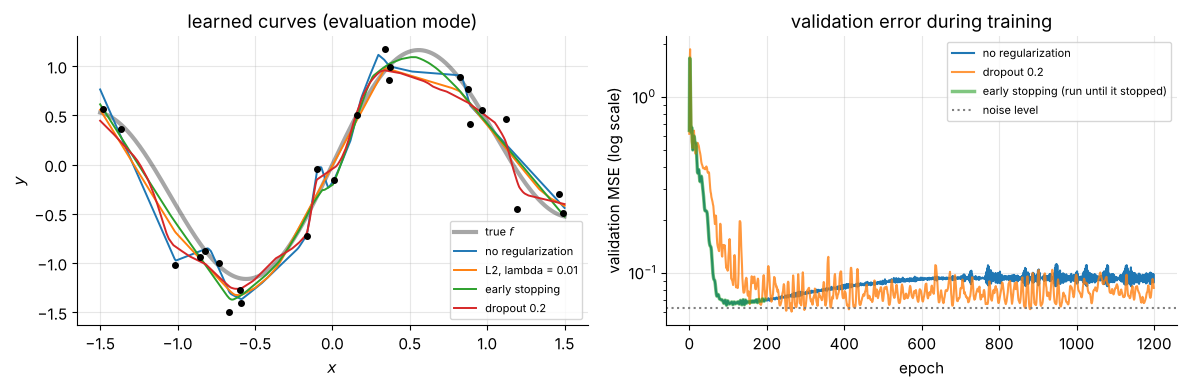

In [73]:
r = np.random.default_rng(SEED)
r_drop = np.random.default_rng(SEED + 1)
net_drop = Sequential(Linear(1, 64, r), ReLU(), Dropout(0.2, r_drop),
                      Linear(64, 64, r), ReLU(), Dropout(0.2, r_drop), Linear(64, 1, r))
hist_drop = fit(net_drop, MSELoss(), Adam(net_drop.parameters(), lr=0.01), x_reg, y_reg, epochs=1200,
                batch_size=len(x_reg), rng=r, X_val=x_regv, y_val=y_regv, classify=False)
reg_nets["dropout 0.2"] = net_drop
reg_rows.append(regression_report("dropout, p = 0.2", net_drop))
display(pd.DataFrame(reg_rows).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x_grid, wavy(x_grid), color="black", lw=3, alpha=0.35, label="true $f$")
for name in ["no regularization", "L2, lambda = 0.01", "early stopping", "dropout 0.2"]:
    reg_nets[name].eval()
    axes[0].plot(x_grid, reg_nets[name].forward(x_grid), lw=1.4, label=name)
axes[0].scatter(x_reg, y_reg, color="black", s=16, zorder=3)
axes[0].set(title="learned curves (evaluation mode)", xlabel="$x$", ylabel="$y$")
axes[0].legend(fontsize=8)
axes[1].plot(hist_plain["val_loss"], label="no regularization")
axes[1].plot(hist_drop["val_loss"], label="dropout 0.2", alpha=0.8)
axes[1].plot(hist_es["val_loss"], label="early stopping (run until it stopped)", lw=2.5, alpha=0.6)
axes[1].axhline(0.0625, color="gray", ls=":", label="noise level")
axes[1].set(yscale="log", xlabel="epoch", ylabel="validation MSE (log scale)", title="validation error during training")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

All three regularizers beat the unregularized network on the error that matters, the distance to the true function ($0.042$): dropout brings it to about $0.032$, L2 with $\lambda = 10^{-2}$ to about $0.026$, and early stopping, the winner on this problem, to about $0.016$, after only 197 of the 1200 epochs. Their training errors are all higher than the unregularized one, or equal: none of them fits the noise as eagerly. They act in different ways. Weight decay keeps the weights small at every step (norm $3.7$ instead of $22.3$). Early stopping ends training before the weights have grown into a noise-fitting configuration. Dropout trains a noisy ensemble of thinned networks. Its validation curve is jumpy because every training step uses a different random sub-network.

Which regularizer works best depends on the problem, the amount of data and the size of the model, so the honest answer is always "compare them on validation data". On large networks they are routinely **combined**: AdamW's weight decay, dropout in the wide layers, and early stopping on the validation loss.

**Quick check.** Your training accuracy is 99% and your validation accuracy is 70%. Name two remedies from this section and one remedy that is not about the model at all.

<details>
<summary>Answer</summary>

The large gap means overfitting. From this section: add weight decay, add dropout, or stop training earlier (keeping the best validation checkpoint), and a smaller network also helps. Not about the model: **get more training data** (or create more with data augmentation, e.g. flipped or shifted images), which is often the most effective cure of all.
</details>

### ✏️ Exercise 12: the early-stopping rule

Write `early_stopping_epochs(val_losses, patience)` that replays the rule used by `fit_early_stopping` on a given list of validation losses (one per epoch, epochs numbered from 0). Return `(best_epoch, stop_epoch)`: the epoch with the lowest loss seen before stopping (only a **strictly** lower loss counts as an improvement), and the epoch at which training stops, i.e. the first epoch that is `patience` epochs after the best one without improvement. If that never happens, training runs to the end and `stop_epoch` is the last epoch.

In [74]:
# ✏️ Exercise 12: replay early stopping on a list of validation losses
def early_stopping_epochs(val_losses, patience):
    """Return (best_epoch, stop_epoch) for the patience rule of fit_early_stopping."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    assert early_stopping_epochs([1.0, 0.8, 0.9, 0.85, 0.95, 0.7], 3) == (1, 4), \
        "three epochs without improvement after epoch 1 -> stop at epoch 4 (the later 0.7 is never seen)"
    assert early_stopping_epochs([1.0, 0.8, 0.9, 0.85, 0.7, 0.95], 3) == (4, 5), "no stop: run to the last epoch"
    assert early_stopping_epochs([0.5, 0.5, 0.5], 2) == (0, 2), "an equal loss is not an improvement"
    assert early_stopping_epochs([3.0, 2.0, 2.5, 1.0], 1) == (1, 2), "patience 1 stops at the first non-improvement"
    assert early_stopping_epochs([2.0], 5) == (0, 0), "a single epoch is both the best and the last"
    assert early_stopping_epochs(hist_es["val_loss"], 100) == (best_es, len(hist_es["val_loss"]) - 1), \
        "your rule should reproduce the run of Section 10.3"


run_check("Exercise 12", _test)

⏳ Exercise 12: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def early_stopping_epochs(val_losses, patience):
    best_epoch, best = 0, val_losses[0]
    for epoch in range(1, len(val_losses)):
        if val_losses[epoch] < best:                 # strict improvement
            best, best_epoch = val_losses[epoch], epoch
        elif epoch - best_epoch >= patience:
            return best_epoch, epoch
    return best_epoch, len(val_losses) - 1
```
This is the loop of `fit_early_stopping` without the training. In a real project you would also save the model's `state_dict` at every new best epoch, exactly like our parameter snapshot.
</details>

## 11. Bridge to PyTorch

Everything you built in this notebook has a direct counterpart in PyTorch. The difference is that PyTorch writes every `backward` method for you (autograd), runs on GPUs, and has been tuned for speed. Since you now know exactly what those components compute, PyTorch should feel like a familiar tool rather than a black box.

### 11.1 Every piece has a PyTorch twin

| our NumPy library | PyTorch | remarks |
|---|---|---|
| `Param` (`.value`, `.grad`) | `nn.Parameter` (a tensor with `requires_grad=True`), `.grad` | PyTorch **adds** new gradients to `.grad`, so clear them with `optimizer.zero_grad()` |
| `Linear(n_in, n_out, rng)` | `nn.Linear(n_in, n_out)` | stores `weight` with shape `(n_out, n_in)`, i.e. our $W^\top$ |
| `ReLU()`, `LeakyReLU()`, `Tanh()`, `Sigmoid()` | `nn.ReLU()`, `nn.LeakyReLU(0.01)`, `nn.Tanh()`, `nn.Sigmoid()` | also `nn.GELU()`, `nn.Softplus()`, `nn.SiLU()` |
| `Dropout(p, rng)` | `nn.Dropout(p)` | inverted dropout, active in training mode (the default for a new model, and after `model.train()`), switched off by `model.eval()` |
| `Sequential(...)` | `nn.Sequential(...)` | or subclass `nn.Module` and write `forward` |
| `SoftmaxCrossEntropy()` | `nn.CrossEntropyLoss()` | input: logits `(m, K)`, and target: class indices `(m,)` of dtype `long` |
| `BCEWithLogits()` | `nn.BCEWithLogitsLoss()` | input: logits, and target: floats in $\{0, 1\}$, same shape |
| `MSELoss()` | `nn.MSELoss()` | |
| `model.backward(loss_fn.backward())` | `loss.backward()` | autograd records the forward pass and replays it backwards |
| `SGD`, `Momentum`, `Adam` | `torch.optim.SGD(lr=...)`, `SGD(lr=..., momentum=0.9)`, `torch.optim.Adam` | same update rules as ours |
| `WeightDecay(Adam(...), lam)` | `torch.optim.Adam(..., weight_decay=lam)` | both add $\lambda W$ to the gradient before the Adam step (PyTorch also decays the biases unless you put them in a separate parameter group). In practice prefer the *decoupled* `torch.optim.AdamW(..., weight_decay=...)` (Section 10.2) |
| `model.train()`, `model.eval()` | `model.train()`, `model.eval()` | plus `torch.no_grad()` to skip graph building during evaluation |
| our `fit` loop, `rng.permutation` | `DataLoader(dataset, batch_size, shuffle=True)` + a loop you write | |

### 11.2 The same model in about 15 lines

Here is the spiral classifier of Sections 6 and 8 ($2 \to 32 \to 32 \to 3$, ReLU, Adam with $\eta = 0.01$, batches of 32, 60 epochs) written with PyTorch. The training loop is the forward–backward–update rhythm of our `fit`, plus one extra line, `zero_grad()`, and the device handling that lets the same code run on a GPU when one is available.

In [75]:
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(SEED)                                            # seeds the initial weights and the shuffling
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_loader = DataLoader(TensorDataset(torch.tensor(X_sp, dtype=torch.float32), torch.tensor(y_sp)),
                          batch_size=32, shuffle=True)
model_t = nn.Sequential(nn.Linear(2, 32), nn.ReLU(), nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, 3)).to(device)
loss_fn_t = nn.CrossEntropyLoss()
optimizer_t = torch.optim.Adam(model_t.parameters(), lr=0.01)

for epoch in range(60):
    model_t.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)   # the batch must live where the model lives
        optimizer_t.zero_grad()                 # 1. clear the gradients of the previous step
        loss = loss_fn_t(model_t(xb), yb)       # 2. forward pass and loss (on logits)
        loss.backward()                         # 3. backward pass: fills p.grad for every parameter
        optimizer_t.step()                      # 4. update the parameters

model_t.eval()
with torch.no_grad():                           # evaluation: no graph, no gradients
    val_pred = model_t(torch.tensor(X_spv, dtype=torch.float32, device=device)).argmax(dim=1).cpu().numpy()
print(f"PyTorch MLP on the spiral: final mini-batch loss {loss.item():.4f}, validation accuracy {np.mean(val_pred == y_spv):.4f}")

PyTorch MLP on the spiral: final mini-batch loss 0.0646, validation accuracy 0.9956


The PyTorch model reaches the same kind of result as our own Adam run of Section 8.5 (the numbers differ slightly because PyTorch draws different initial weights, with its own default scheme from Section 7.2, and shuffles differently). Note the data types: features become `float32` tensors (PyTorch's default precision), and the labels stay integers (`int64`, also called `long`), as `nn.CrossEntropyLoss` requires.

### 11.3 Same weights, same trajectory

Section 5.4 showed that one backward pass of our library matches autograd. A stronger test: start our library and PyTorch from **identical weights**, feed them **identical mini-batches**, and let both optimizers run for 100 steps. If the losses, gradients and update rules all agree, the two sets of weights must still be identical at the end.

In [76]:
def copy_weights_to_torch(ours, torch_model):
    """Copy the parameters of our Sequential MLP into a torch nn.Sequential with the same architecture."""
    our_linears = [layer for layer in ours.layers if isinstance(layer, Linear)]
    torch_linears = [layer for layer in torch_model if isinstance(layer, nn.Linear)]
    with torch.no_grad():
        for mine, tl in zip(our_linears, torch_linears):
            tl.weight.copy_(torch.from_numpy(mine.W.value.T))   # PyTorch stores W transposed
            tl.bias.copy_(torch.from_numpy(mine.b.value.ravel()))
    return our_linears, torch_linears


r = np.random.default_rng(SEED)
ours = make_mlp([2, 16, 16, 3], r)
twin = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU(), nn.Linear(16, 3)).double()
our_linears, twin_linears = copy_weights_to_torch(ours, twin)
opt_ours = Momentum(ours.parameters(), lr=0.05, momentum=0.9)
opt_twin = torch.optim.SGD(twin.parameters(), lr=0.05, momentum=0.9)
ce_ours, ce_twin = SoftmaxCrossEntropy(), nn.CrossEntropyLoss()

batch_order = np.random.default_rng(0).permutation(len(y_sp))
for step in range(100):
    idx = batch_order[(32 * step) % 576:(32 * step) % 576 + 32]      # identical mini-batches for both
    loss_ours = ce_ours.forward(ours.forward(X_sp[idx]), y_sp[idx])
    ours.backward(ce_ours.backward())
    opt_ours.step()
    opt_twin.zero_grad()
    loss_twin = ce_twin(twin(torch.from_numpy(X_sp[idx])), torch.from_numpy(y_sp[idx]))
    loss_twin.backward()
    opt_twin.step()

print(f"loss at step 100: ours {loss_ours:.10f} | PyTorch {loss_twin.item():.10f}")
print("largest weight difference after 100 momentum-SGD steps:",
      max(np.abs(m.W.value - t.weight.detach().numpy().T).max() for m, t in zip(our_linears, twin_linears)))

loss at step 100: ours 0.8315958329 | PyTorch 0.8315958329
largest weight difference after 100 momentum-SGD steps: 4.440892098500626e-16


After 100 updates the two sets of weights still agree to about $10^{-15}$. Our forward pass, our backpropagation, our loss and our momentum optimizer compute exactly what PyTorch computes. (We used float64 tensors, `.double()`, to compare at full precision. In practice PyTorch trains in float32.)

### 11.4 The general PyTorch workflow

The next notebooks (car fuel-efficiency regression, a 3-class nonlinear problem, facial-expression images) all follow the same recipe. Each step maps onto something you have done by hand:

1. **Data.** Load the data, split it into training, validation and test sets, and **standardize** the features using statistics of the training set only. Convert to tensors: `float32` features, `long` class labels (or `float32` regression targets).
2. **Batches.** Wrap the tensors in a `TensorDataset` and a `DataLoader`. Shuffle the training loader only.
3. **Model.** An `nn.Sequential` or an `nn.Module` subclass whose last layer outputs logits (classification) or raw values (regression). Move it to the device (`model.to(device)`). For images, an `nn.Flatten()` layer first turns each $H \times W$ image into a vector of $H \cdot W$ numbers, which is all an MLP can read.
4. **Loss and optimizer.** `nn.CrossEntropyLoss` / `nn.BCEWithLogitsLoss` / `nn.MSELoss`, plus an optimizer from `torch.optim`. The next notebooks begin with SGD (with momentum in Notebook 13) and then compare it with Adam. In your own projects, Adam or AdamW with a learning rate around $10^{-3}$ is a common starting point.
5. **Training loop.** For each epoch: `model.train()`. For each batch: `zero_grad()`, forward, loss, `backward()`, `step()`.
6. **Validation.** `model.eval()` and `torch.no_grad()`. Track the validation loss and a metric that people can interpret (accuracy for classification, and for regression the RMSE or the coefficient of determination $R^2 = 1 - \sum_i(y_i - \hat y_i)^2 / \sum_i(y_i - \bar y)^2$). Keep the best weights (early stopping) via `model.state_dict()`.
7. **Test.** Evaluate once on the test set at the very end and report that number.

Many projects write the model as an `nn.Module` subclass, which makes the forward pass explicit and easy to extend. Here is that style, together with parameter counting and saving/loading the weights:

In [77]:
import io


class MLP(nn.Module):
    """A ReLU MLP with optional dropout. The last layer returns logits."""

    def __init__(self, sizes, p_drop=0.0):
        super().__init__()
        layers = []
        for l in range(len(sizes) - 1):
            layers.append(nn.Linear(sizes[l], sizes[l + 1]))
            if l < len(sizes) - 2:
                layers += [nn.ReLU(), nn.Dropout(p_drop)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


torch.manual_seed(SEED)
mlp = MLP([2, 32, 32, 3], p_drop=0.2)
print(mlp)
print("trainable parameters:", sum(p.numel() for p in mlp.parameters() if p.requires_grad),
      "| our formula sum((n_in + 1) * n_out):", sum((a + 1) * b for a, b in zip([2, 32, 32], [32, 32, 3])))
print({name: tuple(t.shape) for name, t in mlp.state_dict().items()})

buffer = io.BytesIO()                            # a file path works the same way: torch.save(..., "mlp.pt")
torch.save(mlp.state_dict(), buffer)
buffer.seek(0)
restored = MLP([2, 32, 32, 3], p_drop=0.2)
restored.load_state_dict(torch.load(buffer, weights_only=True))
mlp.eval()
restored.eval()
x_probe = torch.randn(5, 2)
print("restored model gives identical outputs:", torch.equal(mlp(x_probe), restored(x_probe)))

MLP(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=3, bias=True)
  )
)
trainable parameters: 1251 | our formula sum((n_in + 1) * n_out): 1251
{'net.0.weight': (32, 2), 'net.0.bias': (32,), 'net.3.weight': (32, 32), 'net.3.bias': (32,), 'net.6.weight': (3, 32), 'net.6.bias': (3,)}
restored model gives identical outputs: True


The parameter count agrees with the formula of Section 2.3, and the `state_dict` keys show where each `nn.Linear` sits inside the `nn.Sequential` (indices 0, 3 and 6, because the ReLU and dropout layers in between have no parameters). Saving the `state_dict` (not the whole model object) is the recommended way to store weights.

### 11.5 Three classic PyTorch mistakes, demonstrated

**1. Forgetting `zero_grad()`.** PyTorch accumulates gradients, so without clearing them each step uses the sum of all previous gradients.

In [78]:
w_acc = torch.tensor([1.0, -2.0], requires_grad=True)
for call in range(1, 4):
    loss_acc = (w_acc ** 2).sum()                 # gradient is 2 w = (2, -4) every time
    loss_acc.backward()
    print(f"after backward call {call}: w.grad = {w_acc.grad.tolist()}")

after backward call 1: w.grad = [2.0, -4.0]
after backward call 2: w.grad = [4.0, -8.0]
after backward call 3: w.grad = [6.0, -12.0]


The true gradient is $(2, -4)$, but `.grad` grows with every call. (Accumulation is deliberate: it lets you add gradients over several small batches before one update. But in the standard loop it means you must call `zero_grad()` every step.)

**2. Evaluating in training mode.** Dropout stays active until you call `model.eval()`, so predictions become random:

In [79]:
mlp.train()
with torch.no_grad():
    in_train_mode = [mlp(x_probe)[0].numpy().round(4) for _ in range(2)]
mlp.eval()
with torch.no_grad():
    in_eval_mode = [mlp(x_probe)[0].numpy().round(4) for _ in range(2)]
print("train mode, same input twice:", in_train_mode[0], in_train_mode[1])
print("eval mode,  same input twice:", in_eval_mode[0], in_eval_mode[1])

train mode, same input twice: [-0.1006  0.06    0.1403] [-0.1691  0.0602  0.0627]
eval mode,  same input twice: [-0.108   0.107   0.0572] [-0.108   0.107   0.0572]


**3. Mismatched types and shapes in the loss.** `nn.CrossEntropyLoss` wants logits of shape `(m, K)` and `long` labels of shape `(m,)`, with no softmax in the model (Section 3.5). `nn.BCEWithLogitsLoss` wants float targets with the same shape as the logits, e.g. `y.float().unsqueeze(1)` for logits of shape `(m, 1)`. And a NumPy array of `float64` becomes a `float64` tensor, which a `float32` model refuses: convert with `torch.tensor(X, dtype=torch.float32)`.

> **Key idea.** PyTorch automates the *mechanics* (gradients, devices, data loading), not the *decisions*. Architecture, activations, initialization, loss, optimizer, learning rate, regularization and evaluation discipline are still yours, and this notebook has shown you why each choice matters.

## 12. Quiz

Twelve exam-style questions. Try each one on paper first. Every answer explains why the correct option is right and why each of the others is wrong.

**Q1. Counting parameters.** A fully connected MLP has widths $10 \to 20 \to 15 \to 4$, with a bias in every layer. How many trainable parameters does it have?

- A) 560
- B) 599
- C) 609
- D) 39

<details>
<summary>Answer</summary>

**B.** Each layer has $(n_{\text{in}} + 1)\,n_{\text{out}}$ parameters: $(10 + 1)\cdot 20 + (20 + 1)\cdot 15 + (15 + 1)\cdot 4 = 220 + 315 + 64 = 599$.
A counts only the weights ($200 + 300 + 60$) and forgets the $20 + 15 + 4 = 39$ biases. C adds 10 "biases" for the input layer, which does no computation and has no parameters. D is the number of units with weights, not the number of parameters.
</details>

**Q2. One step of backprop at the output.** For one example, a softmax classifier outputs probabilities $\mathbf{p} = (0.7, 0.2, 0.1)$ for classes $0, 1, 2$, and the true class is $2$. What is the gradient of the cross-entropy loss with respect to the logits $\mathbf{z}$?

- A) $(0.7,\ 0.2,\ -0.9)$
- B) $(-0.7,\ -0.2,\ 0.9)$
- C) $(0,\ 0,\ -10)$
- D) $(0.7,\ 0.2,\ 0.1)$

<details>
<summary>Answer</summary>

**A.** For softmax + cross-entropy, $\partial\ell/\partial\mathbf{z} = \mathbf{p} - \mathbf{y}$ with the one-hot $\mathbf{y} = (0, 0, 1)$. Gradient descent will raise the true class's logit and lower the others.
B is $\mathbf{y} - \mathbf{p}$, the *negative* gradient (the direction of the update, not the gradient). C is the gradient with respect to the *probabilities*, $-y_k/p_k$, before passing through the softmax. D forgets to subtract the label.
</details>

**Q3. Gradient of a weight matrix.** A layer computes $Z = AW + \mathbf{b}$ with $A \in \mathbb{R}^{32\times 64}$ and $W \in \mathbb{R}^{64\times 10}$. Given $\bar Z = \partial\mathcal{L}/\partial Z \in \mathbb{R}^{32\times 10}$, what is $\partial\mathcal{L}/\partial W$?

- A) $\bar Z\,W^\top$
- B) $A^\top\bar Z$
- C) $\bar Z^\top A$
- D) $A\,\bar Z^\top$

<details>
<summary>Answer</summary>

**B.** $\partial\mathcal{L}/\partial w_{pq} = \sum_i a_{ip}\bar z_{iq} = (A^\top\bar Z)_{pq}$, a $64 \times 10$ matrix like $W$.
A is $\partial\mathcal{L}/\partial A$ (shape $32 \times 64$), the signal passed to the previous layer. C has shape $10 \times 64$: it is the transpose of the right answer (which is exactly the gradient of PyTorch's `weight`, stored as $W^\top$, but not of our $W$). D multiplies a $32 \times 64$ matrix by a $10 \times 32$ matrix: the shapes do not even match.
</details>

**Q4. XOR.** Which statement is true?

- A) A single perceptron learns XOR if it is trained for enough epochs.
- B) Stacking three linear layers without activations makes XOR learnable.
- C) A network with one hidden layer of two ReLU units and a linear output can compute XOR exactly.
- D) Logistic regression on $(x_1, x_2)$ solves XOR if the learning rate is large enough.

<details>
<summary>Answer</summary>

**C.** For example $h_1 = \operatorname{ReLU}(x_1 + x_2)$, $h_2 = \operatorname{ReLU}(x_1 + x_2 - 1)$, $\hat y = h_1 - 2h_2$ (Section 2.6).
A: no line separates XOR (Section 1.4), and the perceptron cycles forever on non-separable data. B: linear layers collapse into one linear map (Section 1.5). D: logistic regression also draws a single line. No learning rate changes that.
</details>

**Q5. Deep sigmoid networks.** In a 20-layer network with sigmoid hidden units, the first layers barely change during training while the last layers learn normally. What is the most likely cause?

- A) Backprop multiplies the signal by $\sigma'(z) \le \tfrac14$ at every layer, so gradients vanish toward the input.
- B) Sigmoid outputs are negative half of the time.
- C) The loss function must be the mean squared error.
- D) The learning rate is too large for the last layers.

<details>
<summary>Answer</summary>

**A.** This is the vanishing gradient problem (Sections 3.3 and 7.3): twenty factors of at most $\tfrac14$ shrink the gradient by up to $4^{-20} \approx 10^{-12}$.
B is false: sigmoid outputs lie in $(0, 1)$, never negative (tanh is the zero-centered one). C is irrelevant: the loss affects only the output layer, and cross-entropy is the better choice anyway. D would make the *last* layers unstable, not the first layers frozen.
</details>

**Q6. Dead ReLUs.** After training with a very large learning rate, 60% of the units in a ReLU layer output $0$ for every training example. Which statement is correct?

- A) These units receive small gradients and will slowly recover.
- B) Their incoming weights and biases receive exactly zero gradient, so gradient descent cannot revive them.
- C) Calling `model.eval()` reactivates them.
- D) Their outgoing weights must have become infinite.

<details>
<summary>Answer</summary>

**B.** A unit that is off for every input has local derivative $0$ for every example, so $\delta$ is zero in its column and its incoming parameters get no gradient (Sections 3.4 and 6.5).
A describes Leaky ReLU, not ReLU. C: `eval()` only changes dropout-like layers, not ReLUs. D: nothing forces the outgoing weights to blow up. The unit simply contributes a constant $0$.
</details>

**Q7. He initialization.** A hidden layer has 512 inputs and is followed by a ReLU. What standard deviation should its initial weights have under He initialization?

- A) $0.0625$
- B) $0.0442$
- C) $0.0039$
- D) $0.0884$

<details>
<summary>Answer</summary>

**A.** He initialization uses $\sigma_w^2 = 2/n_{\text{in}} = 2/512$, so $\sigma_w = \sqrt{2/512} = 0.0625$.
B is $\sqrt{1/512}$ (LeCun), which shrinks a ReLU network's signal by $1/\sqrt2$ per layer. C is the *variance* $2/512$, not the standard deviation. D is $2/\sqrt{512}$, with the square root in the wrong place.
</details>

**Q8. Momentum.** SGD with momentum $\mu = 0.9$ and learning rate $\eta = 0.01$ moves through a region where the gradient is constant. After many steps, its steps are as large as those of plain SGD with which learning rate?

- A) $0.01$
- B) $0.009$
- C) $0.1$
- D) $0.019$

<details>
<summary>Answer</summary>

**C.** With a constant gradient the velocity converges to $\mathbf{g}(1 + \mu + \mu^2 + \cdots) = \mathbf{g}/(1 - \mu) = 10\,\mathbf{g}$, so the step is $\eta \cdot 10\,\mathbf{g} = 0.1\,\mathbf{g}$ (Section 8.2, confirmed experimentally in Section 8.5).
A ignores the accumulated velocity. B would be $\eta\mu$, a single damped term. D is $\eta(1 + \mu)$, only the first two terms of the geometric series.
</details>

**Q9. Adam.** Which statement about Adam (with bias correction) is correct?

- A) Multiplying the loss by 100 makes Adam's steps 100 times larger.
- B) On the very first step, every parameter moves by about $\eta$, against the sign of its gradient.
- C) Adam needs no learning rate.
- D) Bias correction matters mainly at the end of training.

<details>
<summary>Answer</summary>

**B.** At $t = 1$, $\hat m = g$ and $\hat s = g^2$, so the step is $\eta\,g/(|g| + \varepsilon) \approx \eta\operatorname{sign}(g)$ (Exercise 10).
A is false: $\hat m$ and $\sqrt{\hat s}$ both scale by 100, so the step is unchanged (Section 8.4). C: $\eta$ is still the main hyperparameter. It sets the size of every step. D is backwards: $1 - \beta^t$ is far from 1 only for small $t$, so the correction matters at the *start*.
</details>

**Q10. Inverted dropout.** With dropout rate $p = 0.25$, a unit's activation is $3.0$ and it is *not* dropped. What does the dropout layer output during training, and during evaluation?

- A) $3.0$ in training, $2.25$ in evaluation
- B) $2.25$ in training, $3.0$ in evaluation
- C) $4.0$ in training, $3.0$ in evaluation
- D) $0.75$ in training, $3.0$ in evaluation

<details>
<summary>Answer</summary>

**C.** Inverted dropout divides the survivors by the keep probability $1 - p = 0.75$ during training ($3.0/0.75 = 4.0$), so the expected output equals the input, and does nothing at evaluation time.
A describes the old, non-inverted variant, which instead scales activations down at test time. B multiplies by $0.75$ during training, which would shrink the expected activation. D outputs the keep probability itself.
</details>

**Q11. The cost of gradients.** A network has one million parameters. Roughly how much computation does one exact gradient cost with central finite differences, and with backpropagation?

- A) About two million forward passes, versus about three forward passes' worth.
- B) One million forward passes for each.
- C) Two forward passes, versus two million.
- D) Both cost about three forward passes.

<details>
<summary>Answer</summary>

**A.** Central differences need two loss evaluations per parameter. Backprop needs one forward pass plus a backward pass that costs about two forward passes (two matrix products per layer), whatever the number of parameters (Section 4.7).
B and D ignore the fundamental difference between the two methods. C swaps them.
</details>

**Q12. A PyTorch bug.** A classifier ends with `nn.Softmax(dim=1)` and is trained with `nn.CrossEntropyLoss()`. What happens?

- A) Nothing: the loss detects probabilities and skips its own softmax.
- B) Softmax is applied twice. The model still trains, but its loss can never get close to 0 and learning is weakened.
- C) PyTorch raises an error because the loss needs one-hot targets.
- D) The model outputs negative probabilities.

<details>
<summary>Answer</summary>

**B.** `nn.CrossEntropyLoss` always applies log-softmax to its input. Feeding it probabilities squashes the "logits" into $[0, 1]$, so even a perfect one-hot output gives the true class at most $e/(e + K - 1)$ and the loss is bounded below (about $0.551$ for $K = 3$, Section 3.5).
A: the loss cannot know what its input means. C: `nn.CrossEntropyLoss` takes integer class labels (it also accepts class probabilities as targets, but never requires one-hot vectors). D: softmax outputs are always positive.
</details>

## 13. Summary and going further

### Key formulas (row-major convention: one example per row)

| topic | formula |
|---|---|
| forward pass | $Z^{[l]} = A^{[l-1]}W^{[l]} + \mathbf{b}^{[l]}$, $\;A^{[l]} = g(Z^{[l]})$, $\;A^{[0]} = X \in \mathbb{R}^{m\times n_0}$, $\;W^{[l]} \in \mathbb{R}^{n_{l-1}\times n_l}$ |
| parameter count | $\sum_{l=1}^{L}(n_{l-1} + 1)\,n_l$ |
| output error (softmax + CE, sigmoid + BCE) | $\delta^{[L]} = P - Y$ |
| output error (identity + squared error) | $\delta^{[L]} = 2(\hat Y - Y)$ |
| backward recursion | $\delta^{[l]} = \big(\delta^{[l+1]}W^{[l+1]\top}\big) \odot g'(Z^{[l]})$ |
| parameter gradients | $\nabla_{W^{[l]}}\mathcal{L} = \frac1m A^{[l-1]\top}\delta^{[l]}$, $\;\nabla_{\mathbf{b}^{[l]}}\mathcal{L} = \frac1m\sum_i \delta^{[l]}_{i,:}$ |
| local rules | $A = g(Z) \Rightarrow \bar Z = \bar A \odot g'(Z)$, $\;Z = AW + \mathbf{b} \Rightarrow \bar W = A^\top\bar Z,\ \bar A = \bar Z W^\top,\ \bar{\mathbf{b}} = \textstyle\sum_i \bar Z_{i,:}$ |
| activation derivatives | $\sigma' = \sigma(1 - \sigma)$, $\tanh' = 1 - \tanh^2$, $\operatorname{ReLU}' = \mathbb{1}[z > 0]$, $\operatorname{softplus}' = \sigma$, $\operatorname{GELU}' = \Phi + z\varphi$ |
| gradient check | $\frac{f(\theta + h) - f(\theta - h)}{2h}$ (error $O(h^2)$), relative error $\frac{\lVert a - b\rVert}{\lVert a\rVert + \lVert b\rVert}$ |
| initialization | Xavier $\sigma_w^2 = \frac{2}{n_{\text{in}} + n_{\text{out}}}$ (tanh, sigmoid), He $\sigma_w^2 = \frac{2}{n_{\text{in}}}$ (ReLU), and biases $0$ |
| SGD / momentum | $\theta \leftarrow \theta - \eta g$, $\;v \leftarrow \mu v + g,\ \theta \leftarrow \theta - \eta v$ (effective rate $\eta/(1 - \mu)$) |
| Adam | $m \leftarrow \beta_1 m + (1 - \beta_1)g$, $s \leftarrow \beta_2 s + (1 - \beta_2)g^2$, $\theta \leftarrow \theta - \eta\,\frac{m/(1 - \beta_1^t)}{\sqrt{s/(1 - \beta_2^t)} + \varepsilon}$ |
| L2 / weight decay | $\mathcal{L} + \frac{\lambda}{2}\sum_l\lVert W^{[l]}\rVert_F^2$, gradient $+\lambda W$, i.e. $W \leftarrow (1 - \eta\lambda)W - \eta\nabla\mathcal{L}$ |
| inverted dropout | training: $A \odot M/(1 - p)$ with $M_{ij} \sim \text{Bernoulli}(1 - p)$, and evaluation: $A$ |

### Takeaways

- A neuron is a linear score followed by an activation. A single neuron draws one hyperplane, so it cannot solve XOR, and stacking linear layers without activations never helps.
- An MLP is a linear model on **learned features**: hidden layers re-describe the input until the classes become linearly separable. ReLU networks compute piecewise linear functions.
- **Backpropagation** is the chain rule applied from the loss backwards, reusing every intermediate result. A full gradient costs about as much as three forward passes (one forward pass plus a backward pass worth about two), whatever the number of parameters. Two local rules (elementwise activation, linear layer) are all an MLP needs.
- Always verify gradients: finite differences with a relative error, or a comparison with autograd.
- Match the output layer to the loss and feed **logits** to the loss: identity + MSE, sigmoid + BCE, softmax + CE. The gradient at the output is always "prediction minus target".
- Initialization must break symmetry (random weights) and preserve the signal's scale (Xavier for tanh, He for ReLU). Bad scales make activations and gradients vanish or explode exponentially with depth.
- Optimizers: momentum smooths and accelerates SGD. Adam adapts a step size per parameter and is the robust default. The learning rate remains the most important hyperparameter.
- Wide networks can approximate any continuous function on a bounded set (universal approximation), and depth can be exponentially more efficient than width. But representability does not guarantee trainability or generalization.
- Regularize when the training and validation errors diverge: weight decay, early stopping, dropout. Use a separate test set for the final, honest number.

### Going further

- Michael Nielsen, *Neural Networks and Deep Learning*, chapter 2, ["How the backpropagation algorithm works"](http://neuralnetworksanddeeplearning.com/chap2.html), and chapter 4, ["A visual proof that neural nets can compute any function"](http://neuralnetworksanddeeplearning.com/chap4.html).
- Ian Goodfellow, Yoshua Bengio and Aaron Courville, [*Deep Learning*](https://www.deeplearningbook.org/), chapters 6 (feedforward networks and back-propagation), 7 (regularization) and 8 (optimization).
- Stanford CS231n course notes: [backpropagation intuitions](https://cs231n.github.io/optimization-2/) and [setting up a network: initialization, regularization, losses](https://cs231n.github.io/neural-networks-2/).
- Xavier Glorot and Yoshua Bengio (2010), [Understanding the difficulty of training deep feedforward neural networks](https://proceedings.mlr.press/v9/glorot10a.html).
- Kaiming He et al. (2015), [Delving Deep into Rectifiers](https://arxiv.org/abs/1502.01852) (He initialization).
- Diederik Kingma and Jimmy Ba (2015), [Adam: A Method for Stochastic Optimization](https://arxiv.org/abs/1412.6980), and Ilya Loshchilov and Frank Hutter (2019), [Decoupled Weight Decay Regularization](https://arxiv.org/abs/1711.05101) (AdamW).
- Nitish Srivastava et al. (2014), [Dropout: A Simple Way to Prevent Neural Networks from Overfitting](https://jmlr.org/papers/v15/srivastava14a.html).
- Matus Telgarsky (2016), [Benefits of depth in neural networks](https://arxiv.org/abs/1602.04485).
- Andrej Karpathy's [micrograd](https://github.com/karpathy/micrograd): a complete reverse-mode autograd engine in about 100 lines of Python, a natural next step after Section 4.
- PyTorch tutorials: [Learn the Basics](https://pytorch.org/tutorials/beginner/basics/intro.html) and [Automatic differentiation with torch.autograd](https://pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html).

**Next up:** Notebook 11 uses PyTorch to train an MLP for a regression problem (predicting a car's fuel efficiency from its specifications), putting the workflow of Section 11.4 into practice.